# RateRight PGH: Data Cleaning and EDA

## 1. Project Scope
- Unit of analysis: parking zone × calendar day in Pittsburgh local time.
- Target: daily paid transactions = meter transactions + mobile transactions.
- Horizon for the modeling team: 7 days first, potentially 28 days.
- Scope: 9 zones chosen after comparing data availability in both files; Date is from November 2023–October to 2024
- Payments: descriptive context. Payment points: coverage context, not parking-space capacity.



## 2. Data Cleaning
### 2.1 Load Data


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

# import csv
transactions = pd.read_csv("transaction_info.csv")
payment_points = pd.read_csv("parking_info.csv")

transactions.columns = transactions.columns.str.strip()
payment_points.columns = payment_points.columns.str.strip()
print("Transactions shape:", transactions.shape)
print("Payment points shape:", payment_points.shape)
print("Transaction columns:", transactions.columns.tolist())
print("Payment-point columns:", payment_points.columns.tolist())
display(transactions.head())
display(payment_points.head())


Transactions shape: (2016000, 10)
Payment points shape: (1224, 17)
Transaction columns: ['_id', 'zone', 'start', 'end', 'utc_start', 'meter_transactions', 'meter_payments', 'mobile_transactions', 'mobile_payments', 'parent_zone']
Payment-point columns: ['_id', 'id', 'location', 'location_type', 'latitude', 'longitude', 'status', 'zone', 'all_groups', 'guid', 'in_service_utc', 'rate', 'max_hours', 'hours', 'restrictions', 'special_events', 'rate_as_of']


,_id,zone,start,end,utc_start,meter_transactions,meter_payments,mobile_transactions,mobile_payments,parent_zone
0,1,SHADYSIDE2,2014-01-02T05:40:00,2014-01-02T05:50:00,2014-01-02T10:40:00,1,4.0,0,0.0,411 - Shadyside
1,2,SQ.HILL1,2014-01-02T05:40:00,2014-01-02T05:50:00,2014-01-02T10:40:00,1,2.0,0,0.0,413 - Squirrel Hill
2,3,UPTOWN2,2014-01-02T05:50:00,2014-01-02T06:00:00,2014-01-02T10:50:00,1,2.0,0,0.0,403 - Uptown
3,4,Marathon/CMU,2014-01-02T06:00:00,2014-01-02T06:10:00,2014-01-02T11:00:00,1,2.0,0,0.0,415 - SS & SSW|401 - Downtown 1|404 - Strip Di...
4,5,SHADYSIDE2,2014-01-02T06:00:00,2014-01-02T06:10:00,2014-01-02T11:00:00,1,4.0,0,0.0,411 - Shadyside


,_id,id,location,location_type,latitude,longitude,status,zone,all_groups,guid,in_service_utc,rate,max_hours,hours,restrictions,special_events,rate_as_of
0,1,410168-SCHEDR4402,SCHENLEY DR,On street,40.440574,-79.948103,Removed,410 - Oakland 4,CMU Study|410 - Oakland 4|Z - Inactive/Removed...,EE7C4FB7-038A-461A-A667-002870BA4155,2012-08-27T11:24:43,NaN,NaN,NaN,NaN,NaN,2019-01-29
1,2,421009-CEDAR-0302,CEDAR AVE,On street,40.451356,-80.001150,Active,421 - NorthSide,NORTHSIDE|421 - NorthSide,5BAC585B-FE5C-4090-ABF8-005D6C670EF1,2013-08-08T11:34:15,$1/hr,4 HRS,"M-Sat, 8a-6p","M-F, 7AM-9AM",NaN,2019-01-29
2,3,409242-NDTHRG0106,N DITHRIDGE ST,On street,40.448784,-79.951793,Active,409 - Oakland 3,409 - Oakland 3|OAKLAND3,F4BDCD95-6853-413F-A1C6-009AF3F9D725,2012-09-04T16:08:27,$3/hr,No Max,"M-Sat, 8a-6p",NaN,NaN,2019-01-29
3,4,PBP412,Virtual Terminal for ParkMobile,Virtual Zone,NaN,NaN,Active,412 - East Liberty,EASTLIB,8FAADCCE-A7BD-4988-85FC-00DCAB30782C,2015-10-23T16:56:58,NaN,NaN,NaN,NaN,NaN,2019-01-29
4,5,426002-CENTRE1802,CENTRE AVE,On street,40.442621,-79.982096,Active,426 - Hill District,Hill District|426 - Hill District|HILL-DIST,DFCD9083-EE1C-477D-8F82-00F688A1F78C,2017-07-17T11:24:27,$1/hr,2 HRS,"M-Sat, 8a-6p",NaN,NaN,2019-01-29


### 2.2 Clean Zone Names and Dates


In [ ]:
transactions["zone"] = transactions["zone"].astype("string").str.strip()
transactions["zone"] = transactions["zone"].replace("", pd.NA)
if "parent_zone" in transactions.columns:
    transactions["parent_zone"] = transactions["parent_zone"].astype("string").str.strip()

# UTC -> Pittsburgh local time
if "utc_start" in transactions.columns:
    local_start = pd.to_datetime(transactions["utc_start"], errors="coerce", utc=True)
    transactions["start"] = local_start.dt.tz_convert("America/New_York").dt.tz_localize(None)
else:
    # This assumes the source start column already contains local time.
    transactions["start"] = pd.to_datetime(transactions["start"], errors="coerce")
    print("No utc_start column: verify that start is Pittsburgh local time.")

invalid_keys = transactions["zone"].isna() | transactions["start"].isna()
print("Rows with invalid zone or date (removed):", invalid_keys.sum())
transactions = transactions.loc[~invalid_keys].copy()
print("First timestamp:", transactions["start"].min())
print("Last timestamp:", transactions["start"].max())
print("Available zones:", sorted(transactions["zone"].unique()))


Rows with invalid zone or date (removed): 0
First timestamp: 2014-01-02 05:40:00
Last timestamp: 2024-11-26 10:40:00
Available zones: ['403 - HILL DISTRICT 2', '410 - West Circuit', 'CMU Study', 'East Liberty (On-street only)', 'HILL DISTRICT 2', 'HILL-DIST-2', 'Hill District', 'Marathon/CMU', 'Northshore Pgm 66', 'Northshore Pgm 67', 'S. Craig', 'SHADYSIDE1', 'SHADYSIDE2', 'SQ.HILL1', 'SQ.HILL2', 'Southside Lots', 'UPTOWN1', 'UPTOWN2', 'Uptown Pgm 81', 'Uptown Pgm 82', 'W CIRC DR', 'West Circuit']


### 2.3 Compare Data Availability Before Selecting Zones


1. **Transaction file:** Count unique interval records, complete valid daily targets, and calendar coverage within the same study period.
2. **Payment-point file:** Count unique point IDs and active physical points mapped to each zone.
3. Keep zones represented in both files and with at least one active physical point and one complete daily target.
4. Rank by complete target days, then transaction interval rows, then active physical points; select the first nine for the MVP.

**Why this order?** The model predicts daily transactions, so complete daily targets matter most. Payment-point records describe infrastructure; more payment points do not create more time-series training observations. Nine is the project's chosen scope, not a statistically optimal number. This ranking is a simple starting rule; validate continuity and forecast accuracy later.

Names are matched exactly using the payment-point `zone` field and individual `all_groups` tokens. Whole neighborhoods and subzones stay separate. Point membership can overlap across zones; do not add their counts as if they were disjoint.


In [ ]:
start_date = "2023-11-01"
end_date = "2024-11-01"  # End date excluded
n_calendar_days = (pd.Timestamp(end_date) - pd.Timestamp(start_date)).days

# 1. compare zones
period_data = transactions.loc[
    (transactions["start"] >= start_date) & (transactions["start"] < end_date)
].copy()
content_cols = [c for c in period_data.columns if c != "_id"]
print("Duplicate content rows removed before ranking:", period_data.duplicated(subset=content_cols).sum())
period_data = period_data.drop_duplicates(subset=content_cols)
conflicts = period_data.duplicated(["zone", "start"], keep=False)
if conflicts.any():
    display(period_data.loc[conflicts].head(20))
    raise ValueError("Review conflicting zone/time records before ranking zones.")
period_data["date"] = period_data["start"].dt.normalize()
counts = period_data[["meter_transactions", "mobile_transactions"]].apply(pd.to_numeric, errors="coerce")
period_data["valid_counts"] = (
    np.isfinite(counts).all(axis=1) & counts.ge(0).all(axis=1)
    & counts.mod(1).eq(0).all(axis=1)
)
# A daily target is usable only if every recorded interval has both valid counts.
complete_days = period_data.groupby(["zone", "date"])["valid_counts"].all()
transaction_summary = period_data.groupby("zone").agg(
    transaction_rows=("start", "size"),
    observed_days=("date", "nunique"),
    first_date=("date", "min"),
    last_date=("date", "max")
)
transaction_summary["usable_target_days"] = complete_days.groupby("zone").sum()
transaction_summary["usable_day_pct"] = (100 * transaction_summary["usable_target_days"] / n_calendar_days).round(1)
print("Transaction data availability by zone:")
display(transaction_summary.sort_values(["usable_target_days", "transaction_rows"], ascending=False))

# 2. payment point connect with zones
points = payment_points.copy()
for col in ["id", "zone", "status", "location_type", "all_groups"]:
    if col in points.columns:
        points[col] = points[col].astype("string").str.strip()
required = {"id", "zone", "status", "location_type"}
if not required.issubset(points.columns):
    raise ValueError("Payment-point comparison needs id, zone, status, and location_type.")
points["active_physical"] = (
    points["status"].str.casefold().eq("active").fillna(False)
    & points["location_type"].str.casefold().isin(["on street", "on-street", "lot"])
)
direct = points[["id", "zone", "active_physical"]]
if "all_groups" in points.columns:
    groups = points.assign(zone=points["all_groups"].str.split("|", regex=False)).explode("zone")
    memberships = pd.concat([direct, groups[["id", "zone", "active_physical"]]], ignore_index=True)
else:
    memberships = direct.copy()
memberships["zone"] = memberships["zone"].str.strip()
memberships = memberships.dropna(subset=["zone", "id"])
memberships = memberships.loc[memberships["zone"].ne("") & memberships["id"].ne("")]
# one id in one zone count once
memberships = memberships.groupby(["zone", "id"], as_index=False)["active_physical"].max()
point_summary = memberships.groupby("zone").agg(
    payment_point_records=("id", "nunique"),
    active_physical_points=("active_physical", "sum")
)
print("Payment-point availability by zone/group label:")
display(point_summary.sort_values("payment_point_records", ascending=False))

# 3. Outer join to show zones
zone_availability = transaction_summary.join(point_summary, how="outer")
quantity_cols = ["transaction_rows", "observed_days", "usable_target_days", "payment_point_records", "active_physical_points"]
zone_availability[quantity_cols] = zone_availability[quantity_cols].fillna(0).astype(int)
zone_availability["usable_day_pct"] = zone_availability["usable_day_pct"].fillna(0)
zone_availability["in_both_files"] = (
    zone_availability["transaction_rows"].gt(0) & zone_availability["payment_point_records"].gt(0)
)
zone_availability["eligible"] = (
    zone_availability["in_both_files"]
    & zone_availability["usable_target_days"].gt(0)
    & zone_availability["active_physical_points"].gt(0)
)
zone_availability = zone_availability.sort_index().sort_values(
    ["eligible", "usable_target_days", "transaction_rows", "active_physical_points"],
    ascending=False, kind="stable"
)
print("Combined zone comparison (both datasets):")
display(zone_availability.head(15))
print("Exact-match labels may include nested/overlapping areas: confirm the selected geographic units.")


Duplicate content rows removed before ranking: 0
Transaction data availability by zone:


,transaction_rows,observed_days,first_date,last_date,usable_target_days,usable_day_pct
zone,,,,,,
UPTOWN2,19488,309,2023-11-01,2024-10-31,309,84.4
UPTOWN1,7624,304,2023-11-01,2024-10-31,304,83.1
SHADYSIDE1,18669,301,2023-11-01,2024-10-31,301,82.2
SHADYSIDE2,21114,300,2023-11-01,2024-10-31,300,82.0
SQ.HILL1,18844,300,2023-11-01,2024-10-31,300,82.0
HILL-DIST-2,15022,300,2023-11-01,2024-10-31,300,82.0
SQ.HILL2,13015,300,2023-11-01,2024-10-31,300,82.0
W CIRC DR,11861,300,2023-11-01,2024-10-31,300,82.0
S. Craig,9548,300,2023-11-01,2024-10-31,300,82.0


Payment-point availability by zone/group label:


,payment_point_records,active_physical_points
zone,,
Marathon/CMU,176,166
Z - Inactive/Removed Terminals,133,0
415 - SS & SSW,103,100
SOUTHSIDE,102,100
421 - NorthSide,98,91
...,...,...
334 - Taylor Street Lot,2,1
337 - 52nd & Butler Lot,2,1
338 - 42nd & Butler Lot,2,1


Combined zone comparison (both datasets):


,transaction_rows,observed_days,first_date,last_date,usable_target_days,usable_day_pct,payment_point_records,active_physical_points,in_both_files,eligible
zone,,,,,,,,,,
UPTOWN2,19488,309,2023-11-01,2024-10-31,309,84.4,50,49,True,True
UPTOWN1,7624,304,2023-11-01,2024-10-31,304,83.1,13,12,True,True
SHADYSIDE1,18669,301,2023-11-01,2024-10-31,301,82.2,11,10,True,True
SHADYSIDE2,21114,300,2023-11-01,2024-10-31,300,82.0,43,42,True,True
SQ.HILL1,18844,300,2023-11-01,2024-10-31,300,82.0,47,46,True,True
HILL-DIST-2,15022,300,2023-11-01,2024-10-31,300,82.0,10,9,True,True
SQ.HILL2,13015,300,2023-11-01,2024-10-31,300,82.0,10,9,True,True
W CIRC DR,11861,300,2023-11-01,2024-10-31,300,82.0,2,1,True,True
S. Craig,9548,300,2023-11-01,2024-10-31,300,82.0,6,6,True,True


Exact-match labels may include nested/overlapping areas: confirm the selected geographic units.


### 2.4 Select Nine Zones from the Comparison

**Finding — complete after running:** There are 9 zones meet the eligibility rule.


Selected nine zones: ['UPTOWN2', 'UPTOWN1', 'SHADYSIDE1', 'SHADYSIDE2', 'SQ.HILL1', 'HILL-DIST-2', 'SQ.HILL2', 'W CIRC DR', 'S. Craig']


,transaction_rows,observed_days,first_date,last_date,usable_target_days,usable_day_pct,payment_point_records,active_physical_points,in_both_files,eligible,selected
zone,,,,,,,,,,,
UPTOWN2,19488,309,2023-11-01,2024-10-31,309,84.4,50,49,True,True,True
UPTOWN1,7624,304,2023-11-01,2024-10-31,304,83.1,13,12,True,True,True
SHADYSIDE1,18669,301,2023-11-01,2024-10-31,301,82.2,11,10,True,True,True
SHADYSIDE2,21114,300,2023-11-01,2024-10-31,300,82.0,43,42,True,True,True
SQ.HILL1,18844,300,2023-11-01,2024-10-31,300,82.0,47,46,True,True,True
HILL-DIST-2,15022,300,2023-11-01,2024-10-31,300,82.0,10,9,True,True,True
SQ.HILL2,13015,300,2023-11-01,2024-10-31,300,82.0,10,9,True,True,True
W CIRC DR,11861,300,2023-11-01,2024-10-31,300,82.0,2,1,True,True,True
S. Craig,9548,300,2023-11-01,2024-10-31,300,82.0,6,6,True,True,True


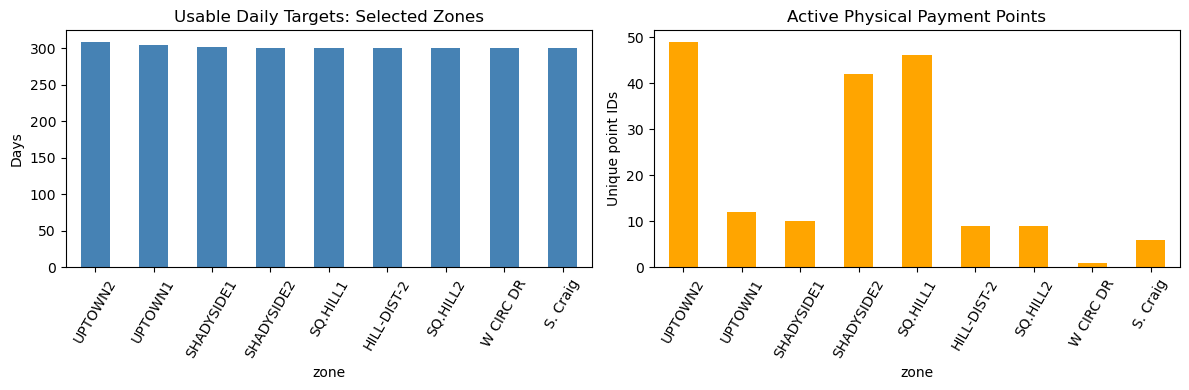

Filtered shape: (135185, 11)


,zone,parent_zone
1871795,HILL-DIST-2,403 - Uptown
1871820,S. Craig,409 - Oakland 3
1871821,SHADYSIDE1,411 - Shadyside
1871794,SHADYSIDE2,411 - Shadyside
1871817,SQ.HILL1,413 - Squirrel Hill
1871842,SQ.HILL2,413 - Squirrel Hill
1871812,UPTOWN1,403 - Uptown
1871813,UPTOWN2,403 - Uptown
1871796,W CIRC DR,410 - Oakland 4


In [ ]:
ranked_zones = zone_availability.loc[zone_availability["eligible"]].copy()
if len(ranked_zones) < 9:
    raise ValueError(
        f"Only {len(ranked_zones)} eligible zones found. Check names, all_groups, dates, "
        "and payment-point categories before selecting nine."
    )
forecast_zones = ranked_zones.head(9).index.tolist()
zone_availability["selected"] = zone_availability.index.isin(forecast_zones)
print("Selected nine zones:", forecast_zones)
display(zone_availability.loc[forecast_zones])

# seperate two pics
selected_summary = zone_availability.loc[forecast_zones]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
selected_summary["usable_target_days"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Usable Daily Targets: Selected Zones")
axes[0].set_ylabel("Days")
selected_summary["active_physical_points"].plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Active Physical Payment Points")
axes[1].set_ylabel("Unique point IDs")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

filtered = period_data.loc[period_data["zone"].isin(forecast_zones)].drop(columns="valid_counts").copy()
print("Filtered shape:", filtered.shape)
if "parent_zone" in filtered.columns:
    display(filtered[["zone", "parent_zone"]].drop_duplicates().sort_values("zone"))


**Finding** The 9 zones have enough data amounts for the team to train and test the model.


### 2.5 Check Duplicates and Numeric Values


In [ ]:
count_cols = ["meter_transactions", "mobile_transactions"]
payment_cols = ["meter_payments", "mobile_payments"]
value_cols = count_cols + payment_cols

# _id is a source identifier; it can hide duplicate transaction content.
content_cols = [c for c in filtered.columns if c != "_id"]
duplicate_rows = filtered.duplicated(subset=content_cols)
print("Duplicate content rows removed:", duplicate_rows.sum())
filtered = filtered.loc[~duplicate_rows].copy()

# One sampling zone should have one aggregate per time interval.
conflicts = filtered.duplicated(subset=["zone", "start"], keep=False)
if conflicts.any():
    display(filtered.loc[conflicts].head(20))
    raise ValueError("Conflicting zone/time records: review them before summing.")

for col in value_cols:
    filtered[col] = pd.to_numeric(filtered[col], errors="coerce")
    filtered.loc[~np.isfinite(filtered[col]), col] = np.nan

# Counts must be nonnegative whole numbers; retain unknowns as NaN.
for col in count_cols:
    invalid = (filtered[col] < 0) | (filtered[col].notna() & (filtered[col] % 1 != 0))
    print(col, "invalid counts set to NaN:", invalid.sum())
    filtered.loc[invalid, col] = np.nan

print("Missing/invalid numeric values:")
display(filtered[value_cols].isna().sum().to_frame("missing_values"))
print("Negative payment values retained for review:")
display(filtered[payment_cols].lt(0).sum().to_frame("negative_values"))


Duplicate content rows removed: 0
meter_transactions invalid counts set to NaN: 0
mobile_transactions invalid counts set to NaN: 0
Missing/invalid numeric values:


,missing_values
meter_transactions,0
mobile_transactions,0
meter_payments,0
mobile_payments,0


Negative payment values retained for review:


,negative_values
meter_payments,0
mobile_payments,0


**Finding** There are no duplicate rows, invalid counts, and missing values.


### 2.6 Aggregate to One Row per Zone per Day


In [ ]:
filtered["date"] = filtered["start"].dt.normalize()
groups = filtered.groupby(["zone", "date"])
daily = groups[value_cols].sum(min_count=1)

# A partially missing day must not look like a complete daily total.
missing_in_day = groups[value_cols].count().lt(groups.size(), axis=0)
daily = daily.mask(missing_in_day)
daily["total_transactions"] = daily["meter_transactions"] + daily["mobile_transactions"]
daily["total_payments"] = daily["meter_payments"] + daily["mobile_payments"]
daily["source_rows"] = groups.size()
daily = daily.reset_index()
display(daily.head())


,zone,date,meter_transactions,mobile_transactions,meter_payments,mobile_payments,total_transactions,total_payments,source_rows
0,HILL-DIST-2,2023-11-01,29.0,114.0,136.31,630.75,143.0,767.06,58
1,HILL-DIST-2,2023-11-02,22.0,135.0,102.16,727.30,157.0,829.46,55
2,HILL-DIST-2,2023-11-03,31.0,109.0,101.50,434.48,140.0,535.98,57
3,HILL-DIST-2,2023-11-04,20.0,50.0,99.13,242.55,70.0,341.68,37
4,HILL-DIST-2,2023-11-06,29.0,98.0,89.60,522.40,127.0,612.00,55


### 2.7 Complete the Calendar and Inspect Missing Days


In [ ]:
all_dates = pd.date_range(start_date, pd.Timestamp(end_date) - pd.Timedelta(days=1))
full_index = pd.MultiIndex.from_product([forecast_zones, all_dates], names=["zone", "date"])
daily_complete = daily.set_index(["zone", "date"]).reindex(full_index).reset_index()
daily_complete["has_records"] = daily_complete["source_rows"].notna()
daily_complete["source_rows"] = daily_complete["source_rows"].fillna(0).astype(int)
daily_complete["weekday"] = daily_complete["date"].dt.day_name()
daily_complete["missing_target"] = daily_complete["total_transactions"].isna()

coverage = daily_complete.groupby("zone").agg(
    calendar_days=("date", "size"),
    days_with_records=("has_records", "sum"),
    usable_target_days=("total_transactions", "count"),
    missing_target_days=("missing_target", "sum")
)
display(coverage)
missing_days = daily_complete.loc[~daily_complete["has_records"], ["zone", "date", "weekday"]]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
display(pd.crosstab(missing_days["zone"], missing_days["weekday"]).reindex(columns=weekday_order, fill_value=0))
shared_missing_dates = missing_days.groupby(["date", "weekday"]).size().reset_index(name="zones_without_records")
display(shared_missing_dates.sort_values(["zones_without_records", "date"], ascending=[False, True]).head(20))


,calendar_days,days_with_records,usable_target_days,missing_target_days
zone,,,,
HILL-DIST-2,366,300,300,66
S. Craig,366,300,300,66
SHADYSIDE1,366,301,301,65
SHADYSIDE2,366,300,300,66
SQ.HILL1,366,300,300,66
SQ.HILL2,366,300,300,66
UPTOWN1,366,304,304,62
UPTOWN2,366,309,309,57
W CIRC DR,366,300,300,66


weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
zone,,,,,,,
HILL-DIST-2,5,1,1,2,3,2,52
S. Craig,5,1,1,2,3,2,52
SHADYSIDE1,4,1,1,2,3,2,52
SHADYSIDE2,5,1,1,2,3,2,52
SQ.HILL1,5,1,1,2,3,2,52
SQ.HILL2,5,1,1,2,3,2,52
UPTOWN1,4,1,1,2,2,0,52
UPTOWN2,3,0,1,2,1,0,50
W CIRC DR,5,1,1,2,3,2,52


,date,weekday,zones_without_records
0,2023-11-05,Sunday,9
3,2023-11-12,Sunday,9
4,2023-11-19,Sunday,9
5,2023-11-23,Thursday,9
6,2023-11-24,Friday,9
8,2023-11-26,Sunday,9
9,2023-12-03,Sunday,9
10,2023-12-10,Sunday,9
11,2023-12-17,Sunday,9
12,2023-12-24,Sunday,9


**Finding** Most missing dates falling on Sundays and several shared dates around holidays. This pattern suggests a possible link to parking operations, but missing values are retained as unknown rather than assumed to be zero.


### 2.8 Payment-Point Coverage


In [ ]:
point_counts = zone_availability.loc[forecast_zones, "active_physical_points"]
display(point_counts.to_frame("active_physical_payment_points"))
matched_points = memberships.loc[memberships["zone"].isin(forecast_zones) & memberships["active_physical"]]
print("Unique matched physical point IDs:", matched_points["id"].nunique())
print("Points can belong to multiple zones; per-zone counts may overlap.")


,active_physical_payment_points
zone,
UPTOWN2,49
UPTOWN1,12
SHADYSIDE1,10
SHADYSIDE2,42
SQ.HILL1,46
HILL-DIST-2,9
SQ.HILL2,9
W CIRC DR,1
S. Craig,6


Unique matched physical point IDs: 184
Points can belong to multiple zones; per-zone counts may overlap.


**Finding** There are no missing group labels, no zero infrastructure.

### 2.9 Multi-year Weather Data Import


In [ ]:
import pandas as pd
import requests

points = payment_points.copy()

# clear data
for col in ["id", "zone", "status", "location_type"]:
    points[col] = points[col].astype("string").str.strip()

for col in ["latitude", "longitude"]:
    points[col] = pd.to_numeric(points[col], errors="coerce")

points = points[
    points["status"].str.lower().eq("active").fillna(False)
    & points["location_type"].str.lower().isin(
        ["on street", "on-street", "lot"]
    )
].copy()

# use both zone and all_groups
mapping_cols = ["id", "zone", "latitude", "longitude"]
zone_points = points[mapping_cols].copy()

if "all_groups" in points.columns:
    group_points = points.copy()
    group_points["zone"] = (
        group_points["all_groups"]
        .astype("string")
        .str.split("|", regex=False)
    )
    group_points = group_points.explode("zone")

    zone_points = pd.concat(
        [zone_points, group_points[mapping_cols]],
        ignore_index=True
    )

zone_points["zone"] = zone_points["zone"].str.strip()

zone_points = (
    zone_points[
        zone_points["zone"].isin(forecast_zones)
        & zone_points["latitude"].between(40, 41)
        & zone_points["longitude"].between(-81, -79)
    ]
    .dropna(subset=["id", "latitude", "longitude"])
    .drop_duplicates(subset=["zone", "id"])
)

# reindex zone
zone_coordinates = zone_points.groupby("zone").agg(
    latitude=("latitude", "median"),
    longitude=("longitude", "median"),
    payment_points_used=("id", "nunique")
).reindex(forecast_zones)

display(zone_coordinates)

# stop if one zone has no coordinates
missing_coordinates = zone_coordinates[
    ["latitude", "longitude"]
].isna().any(axis=1)

if missing_coordinates.any():
    raise ValueError(
        "zones without valid coordinate:"
        + str(zone_coordinates.index[missing_coordinates].tolist())
    )


# Download weather back to the earliest selected-zone transaction date.
# Keep the established study end date so the final 7-day holdout remains unchanged.
weather_history_start = transactions.loc[
    transactions["zone"].isin(forecast_zones), "start"
].dt.normalize().min()
weather_history_end = min(
    transactions.loc[transactions["zone"].isin(forecast_zones), "start"].dt.normalize().max(),
    pd.Timestamp(end_date) - pd.Timedelta(days=1)
)
weather_start = weather_history_start.strftime("%Y-%m-%d")
weather_end = weather_history_end.strftime("%Y-%m-%d")
print("Historical weather archive:", weather_start, "to", weather_end)

# The nine zone coordinates resolve to the same Open-Meteo grid cell in Pittsburgh.
# Download that grid once, then reuse the daily series for each zone to avoid API rate limits.
import time

representative_coordinates = zone_coordinates[["latitude", "longitude"]].median()
params = {
    "latitude": representative_coordinates["latitude"],
    "longitude": representative_coordinates["longitude"],
    "start_date": weather_start,
    "end_date": weather_end,
    "daily": "temperature_2m_mean,rain_sum,snowfall_sum",
    "timezone": "America/New_York",
    "temperature_unit": "celsius",
    "precipitation_unit": "mm"
}

archive_url = "https://archive-api.open-meteo.com/v1/archive"
max_attempts = 5
for attempt in range(max_attempts):
    response = requests.get(archive_url, params=params, timeout=120)
    if response.status_code != 429:
        response.raise_for_status()
        break

    if attempt == max_attempts - 1:
        response.raise_for_status()

    retry_after = response.headers.get("Retry-After")
    try:
        wait_seconds = float(retry_after) if retry_after else 10 * (2 ** attempt)
    except (TypeError, ValueError):
        wait_seconds = 10 * (2 ** attempt)
    wait_seconds = min(wait_seconds, 120)
    print(f"Open-Meteo rate limit (429); retrying in {wait_seconds:g} seconds...")
    time.sleep(wait_seconds)

result = response.json()
base_daily_weather = pd.DataFrame(result["daily"]).rename(columns={
    "time": "date",
    "temperature_2m_mean": "temp_mean",
    "rain_sum": "rain_mm",
    "snowfall_sum": "snow_cm"
})
base_daily_weather["date"] = pd.to_datetime(base_daily_weather["date"])

weather_list = []
weather_locations = []
for zone, row in zone_coordinates.iterrows():
    zone_daily_weather = base_daily_weather.copy()
    zone_daily_weather["zone"] = zone
    weather_list.append(zone_daily_weather)

    # Keep the requested zone coordinates and the shared returned grid for transparency.
    weather_locations.append({
        "zone": zone,
        "requested_latitude": row["latitude"],
        "requested_longitude": row["longitude"],
        "returned_latitude": result["latitude"],
        "returned_longitude": result["longitude"]
    })

zone_weather = pd.concat(weather_list, ignore_index=True)
weather_locations = pd.DataFrame(weather_locations)

display(zone_weather.head())
display(weather_locations)

parking_daily = daily_complete.copy()
parking_daily["date"] = pd.to_datetime(parking_daily["date"])

daily_weather = parking_daily.merge(
    zone_weather,
    on=["zone", "date"],
    how="left",
    validate="one_to_one"
)

weather_cols = ["temp_mean", "rain_mm", "snow_cm"]

display(daily_weather[
    ["zone", "date", "total_transactions"] + weather_cols
].head(10))

print("zone missing value:")
display(
    daily_weather.groupby("zone")[weather_cols]
    .agg(lambda x: x.isna().sum())
)

print("zone weather days:")
display(zone_weather.groupby("zone")["date"].nunique())

,latitude,longitude,payment_points_used
zone,,,
UPTOWN2,40.438475,-79.986835,49
UPTOWN1,40.442028,-79.988493,12
SHADYSIDE1,40.451303,-79.933626,10
SHADYSIDE2,40.456200,-79.937625,42
SQ.HILL1,40.435554,-79.922839,46
HILL-DIST-2,40.444741,-79.965607,9
SQ.HILL2,40.428288,-79.924958,9
W CIRC DR,40.439062,-79.943559,1
S. Craig,40.445518,-79.948837,6


Historical weather archive: 2014-01-02 to 2024-10-31


,date,temp_mean,rain_mm,snow_cm,zone
0,2014-01-02,-3.0,0.0,5.81,UPTOWN2
1,2014-01-03,-13.3,0.0,0.91,UPTOWN2
2,2014-01-04,-8.2,0.0,0.00,UPTOWN2
3,2014-01-05,-0.8,1.3,0.00,UPTOWN2
4,2014-01-06,-6.2,7.7,0.70,UPTOWN2


,zone,requested_latitude,requested_longitude,returned_latitude,returned_longitude
0,UPTOWN2,40.438475,-79.986835,40.45694,-79.97177
1,UPTOWN1,40.442028,-79.988493,40.45694,-79.97177
2,SHADYSIDE1,40.451303,-79.933626,40.45694,-79.97177
3,SHADYSIDE2,40.456200,-79.937625,40.45694,-79.97177
4,SQ.HILL1,40.435554,-79.922839,40.45694,-79.97177
5,HILL-DIST-2,40.444741,-79.965607,40.45694,-79.97177
6,SQ.HILL2,40.428288,-79.924958,40.45694,-79.97177
7,W CIRC DR,40.439062,-79.943559,40.45694,-79.97177
8,S. Craig,40.445518,-79.948837,40.45694,-79.97177


,zone,date,total_transactions,temp_mean,rain_mm,snow_cm
0,UPTOWN2,2023-11-01,367.0,2.1,0.0,0.07
1,UPTOWN2,2023-11-02,510.0,2.6,0.0,0.00
2,UPTOWN2,2023-11-03,460.0,6.6,0.0,0.00
3,UPTOWN2,2023-11-04,181.0,9.6,0.1,0.00
4,UPTOWN2,2023-11-05,NaN,9.1,0.0,0.00
5,UPTOWN2,2023-11-06,529.0,10.3,0.0,0.00
6,UPTOWN2,2023-11-07,488.0,14.7,0.1,0.00
7,UPTOWN2,2023-11-08,475.0,8.6,0.0,0.00
8,UPTOWN2,2023-11-09,497.0,12.6,2.4,0.00
9,UPTOWN2,2023-11-10,5.0,8.4,0.0,0.00


zone missing value：


,temp_mean,rain_mm,snow_cm
zone,,,
HILL-DIST-2,0,0,0
S. Craig,0,0,0
SHADYSIDE1,0,0,0
SHADYSIDE2,0,0,0
SQ.HILL1,0,0,0
SQ.HILL2,0,0,0
UPTOWN1,0,0,0
UPTOWN2,0,0,0
W CIRC DR,0,0,0


zone weather days：


zone
HILL-DIST-2    3956
S. Craig       3956
SHADYSIDE1     3956
SHADYSIDE2     3956
SQ.HILL1       3956
SQ.HILL2       3956
UPTOWN1        3956
UPTOWN2        3956
W CIRC DR      3956
Name: date, dtype: int64

## 3. Exploratory Data Analysis
All averages below use available daily targets; unknown days are excluded, not treated as zero.


### 3.1 Demand Distribution and Average by Zone


,count,mean,median,std,min,max
zone,,,,,,
HILL-DIST-2,300,143.67,141.0,58.36,1.0,358.0
S. Craig,300,47.03,47.0,11.82,19.0,79.0
SHADYSIDE1,301,390.16,398.0,51.54,25.0,504.0
SHADYSIDE2,300,663.06,679.0,85.98,336.0,809.0
SQ.HILL1,300,967.26,971.0,98.25,477.0,1230.0
SQ.HILL2,300,87.87,88.0,21.45,30.0,154.0
UPTOWN1,304,45.92,41.0,29.47,1.0,171.0
UPTOWN2,309,372.80,397.0,132.19,1.0,659.0
W CIRC DR,300,107.93,110.5,44.60,1.0,192.0


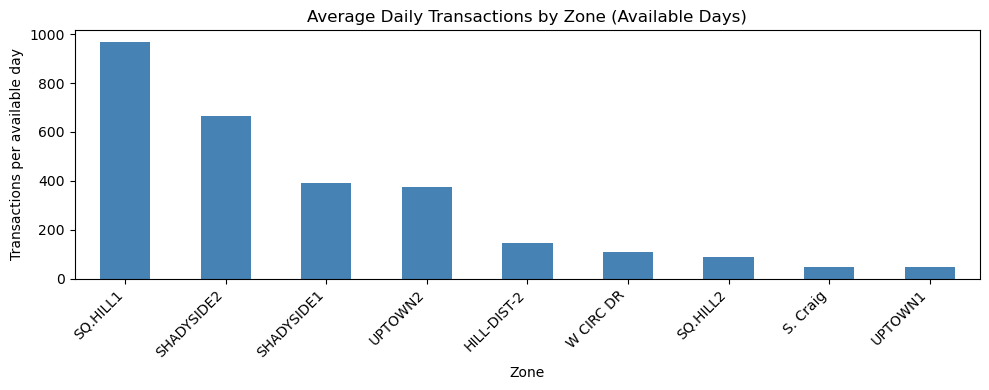

In [ ]:
zone_stats = daily_complete.groupby("zone")["total_transactions"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
display(zone_stats)
zone_stats["mean"].sort_values(ascending=False).plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Average Daily Transactions by Zone (Available Days)")
plt.xlabel("Zone")
plt.ylabel("Transactions per available day")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Finding** SQ.HILL1 has the highest average daily transaction volume, followed by SHADYSIDE2, while S. Craig and UPTOWN1 have the lowest averages.


### 3.2 Day-of-Week Patterns by Zone


zone,HILL-DIST-2,S. Craig,SHADYSIDE1,SHADYSIDE2,SQ.HILL1,SQ.HILL2,UPTOWN1,UPTOWN2,W CIRC DR
weekday,,,,,,,,,
Monday,150.0,43.9,358.2,638.4,902.3,78.4,39.1,411.9,118.7
Tuesday,158.5,43.7,395.4,682.7,950.9,94.2,57.5,430.8,129.6
Wednesday,165.4,45.2,391.6,698.3,972.4,100.0,55.2,420.7,127.7
Thursday,164.5,47.4,387.5,718.8,989.1,89.4,57.1,439.7,127.1
Friday,134.5,49.3,416.5,713.4,1052.4,104.8,41.9,384.5,101.4
Saturday,87.7,52.7,390.9,523.3,933.9,59.6,24.6,167.2,42.1
Sunday,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN


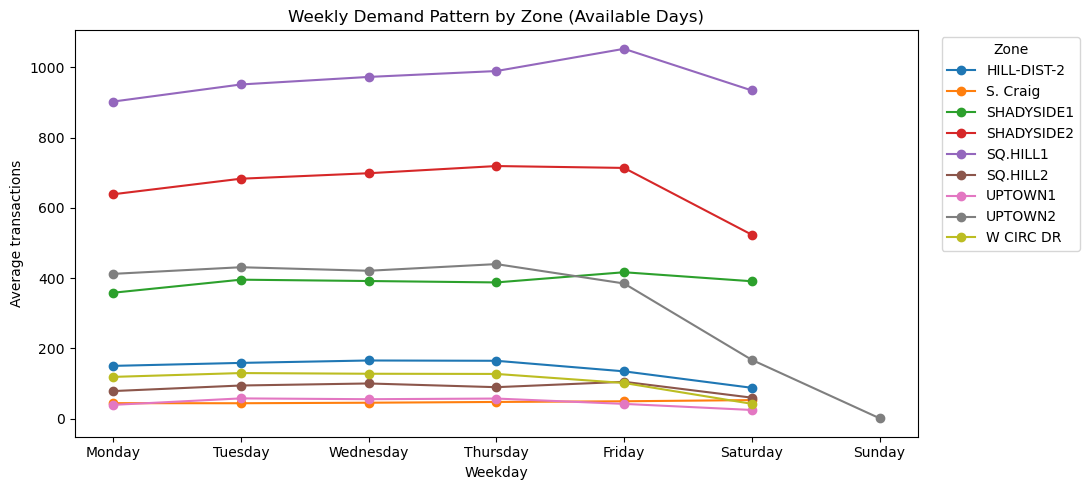

,usable_zone_days
weekday,
Monday,427
Tuesday,460
Wednesday,468
Thursday,459
Friday,444
Saturday,454
Sunday,2


In [ ]:
weekday_zone = daily_complete.pivot_table(index="weekday", columns="zone", values="total_transactions", aggfunc="mean").reindex(weekday_order)
display(weekday_zone.round(1))
weekday_zone.plot(figsize=(11, 5), marker="o")
plt.title("Weekly Demand Pattern by Zone (Available Days)")
plt.ylabel("Average transactions")
plt.xlabel("Weekday")
plt.legend(title="Zone", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
# Empty weekday cells mean unknown demand, not zero.
display(daily_complete.groupby("weekday")["total_transactions"].count().reindex(weekday_order).to_frame("usable_zone_days"))


**Finding** Most zones have lower average transactions on Saturdays than on weekdays, while Sunday demand cannot be reliably assessed because only two usable zone-days are available.


### 3.3 Demand Over Time


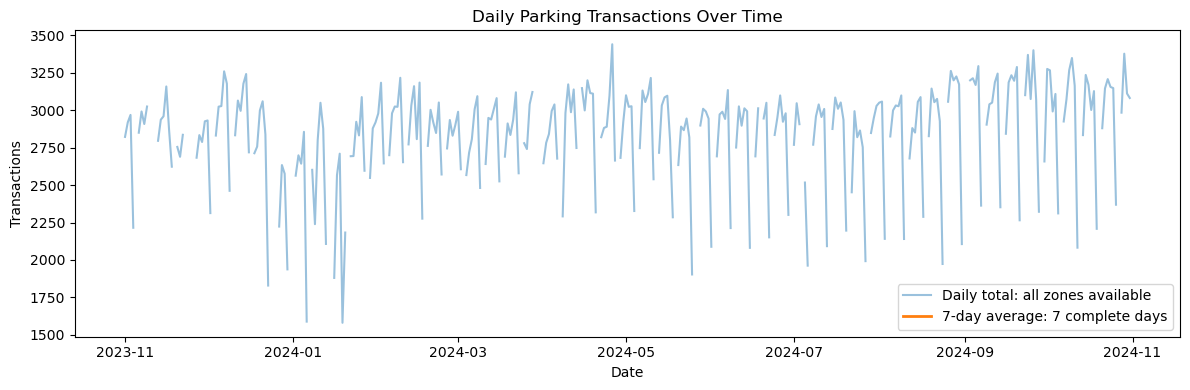

Dates with all nine zone totals: 300
Complete 7-day moving-average values: 0


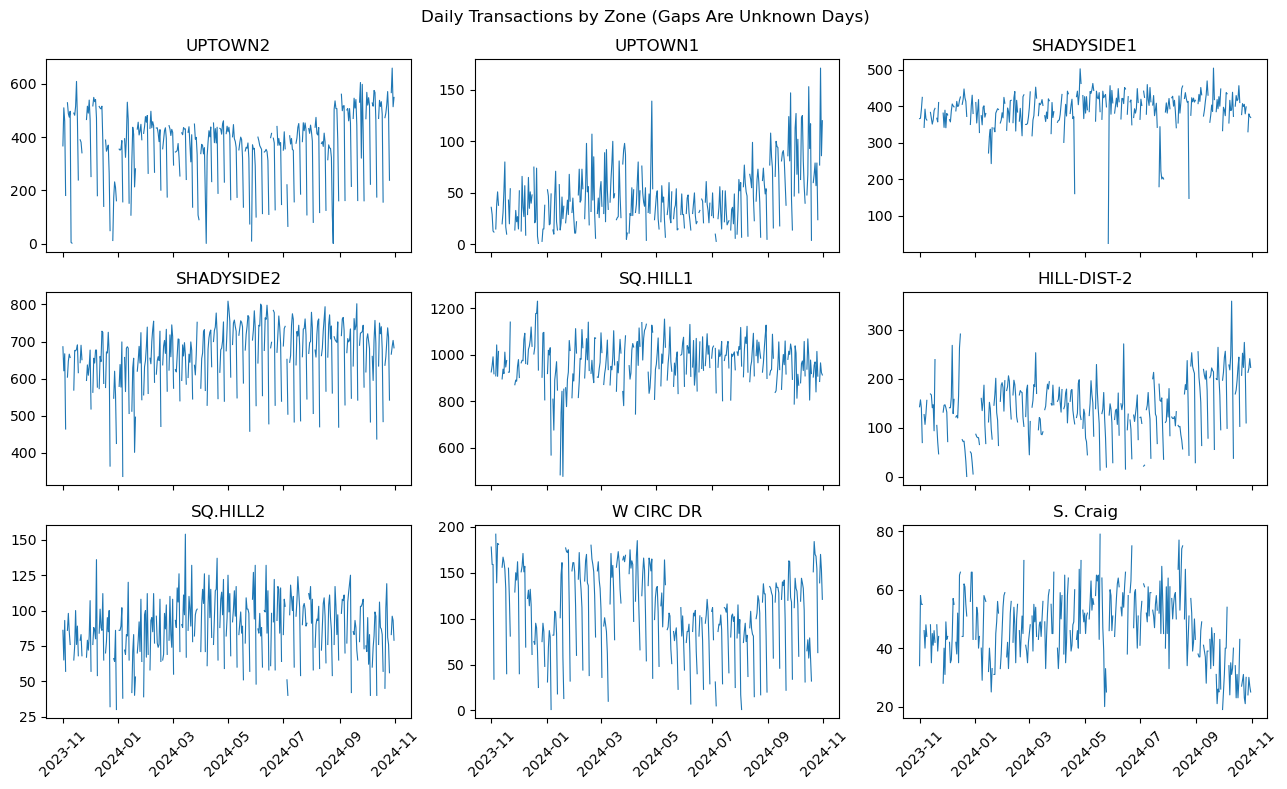

In [ ]:
# Only show a combined total when all nine zone totals are available.
overall_daily = daily_complete.groupby("date")["total_transactions"].sum(min_count=len(forecast_zones))
overall_ma7 = overall_daily.rolling(7, min_periods=7).mean()
plt.figure(figsize=(12, 4))
plt.plot(overall_daily.index, overall_daily, alpha=0.45, label="Daily total: all zones available")
plt.plot(overall_ma7.index, overall_ma7, linewidth=2, label="7-day average: 7 complete days")
plt.title("Daily Parking Transactions Over Time")
plt.xlabel("Date")
plt.ylabel("Transactions")
plt.legend()
plt.tight_layout()
plt.show()
print("Dates with all nine zone totals:", overall_daily.notna().sum())
print("Complete 7-day moving-average values:", overall_ma7.notna().sum())
# Zone plots remain useful even when the combined moving average has many gaps.
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
for ax, zone in zip(axes.flat, forecast_zones):
    part = daily_complete.loc[daily_complete["zone"] == zone]
    ax.plot(part["date"], part["total_transactions"], linewidth=0.8)
    ax.set_title(zone)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Daily Transactions by Zone (Gaps Are Unknown Days)")
fig.tight_layout()
plt.show()


**Finding** Total transactions fluctuate throughout the year and appear higher in September–October, but missing dates prevent calculation of a complete seven-day moving average.W CIRC DR shows lower transaction levels during May–August and a recovery in September–October, while S. Craig declines toward the end of the study period.


### 3.4 Monthly Demand


,count,mean
year_month,,
2023-11,194,307.1
2023-12,217,307.1
2024-01,227,283.2
2024-02,225,320.9
2024-03,227,310.1
2024-04,235,321.7
2024-05,236,314.5
2024-06,216,309.0
2024-07,234,307.2


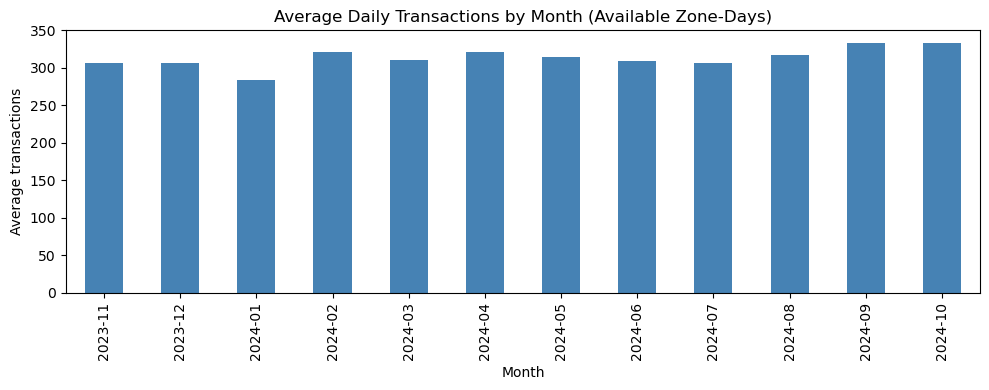

In [ ]:
daily_complete["year_month"] = daily_complete["date"].dt.to_period("M").astype(str)
monthly = daily_complete.groupby("year_month")["total_transactions"].agg(["count", "mean"]).round(1)
display(monthly)
monthly["mean"].plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Average Daily Transactions by Month (Available Zone-Days)")
plt.xlabel("Month")
plt.ylabel("Average transactions")
plt.tight_layout()
plt.show()


**Finding** Average transactions per available zone-day are lowest in January and highest in September–October, although one year of data is insufficient to confirm annual seasonality.


### 3.5 Meter vs Mobile Transactions


Channel share on paired valid days (%):


,share_percent
meter_transactions,33.4
mobile_transactions,66.6


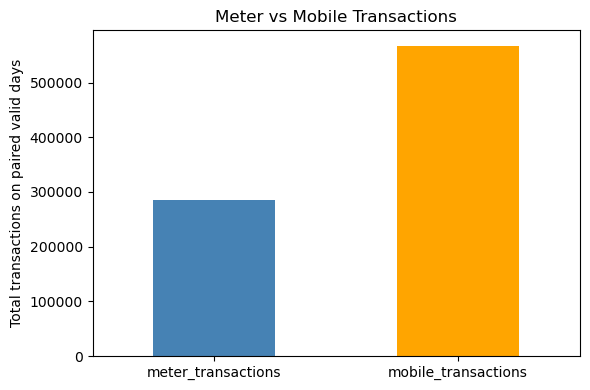

In [ ]:
# Compare both channels on the same days with valid counts.
paired_days = daily_complete.dropna(subset=count_cols)
channel_totals = paired_days[count_cols].sum()
channel_share = channel_totals / channel_totals.sum() * 100
print("Channel share on paired valid days (%):")
display(channel_share.round(1).to_frame("share_percent"))
channel_totals.plot(kind="bar", figsize=(6, 4), color=["steelblue", "orange"])
plt.title("Meter vs Mobile Transactions")
plt.ylabel("Total transactions on paired valid days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Finding** Mobile transactions account for 66.6% of transactions on days with valid data for both channels, approximately twice the meter share of 33.4%.

### 3.6 Review High and Low Days Within Each Zone


In [ ]:
valid_days = daily_complete.dropna(subset=["total_transactions"])
high_days = valid_days.sort_values("total_transactions", ascending=False).groupby("zone").head(3)
low_days = valid_days.sort_values("total_transactions").groupby("zone").head(3)
print("Three highest recorded days per zone:")
display(high_days[["zone", "date", "weekday", "total_transactions"]].sort_values(["zone", "date"]))
print("Three lowest recorded days per zone:")
display(low_days[["zone", "date", "weekday", "total_transactions"]].sort_values(["zone", "date"]))


Three highest recorded days per zone:


,zone,date,weekday,total_transactions
1875,HILL-DIST-2,2023-12-16,Saturday,291.0
2174,HILL-DIST-2,2024-10-10,Thursday,358.0
2188,HILL-DIST-2,2024-10-24,Thursday,274.0
3127,S. Craig,2024-05-18,Saturday,79.0
3162,S. Craig,2024-06-22,Saturday,75.0
3214,S. Craig,2024-08-13,Tuesday,77.0
909,SHADYSIDE1,2024-04-26,Friday,502.0
1049,SHADYSIDE1,2024-09-13,Friday,469.0
1056,SHADYSIDE1,2024-09-20,Friday,504.0
1280,SHADYSIDE2,2024-05-01,Wednesday,809.0


Three lowest recorded days per zone:


,zone,date,weekday,total_transactions
1882,HILL-DIST-2,2023-12-23,Saturday,1.0
1889,HILL-DIST-2,2023-12-30,Saturday,6.0
2029,HILL-DIST-2,2024-05-18,Saturday,14.0
3132,S. Craig,2024-05-23,Thursday,20.0
3262,S. Craig,2024-09-30,Monday,19.0
3287,S. Craig,2024-10-25,Friday,21.0
903,SHADYSIDE1,2024-04-20,Saturday,161.0
940,SHADYSIDE1,2024-05-27,Monday,25.0
1029,SHADYSIDE1,2024-08-24,Saturday,148.0
1150,SHADYSIDE2,2023-12-23,Saturday,364.0


**Finding** Many of the lowest recorded transaction days occur on Saturdays, with several zones sharing low-demand dates in late December and early January.

### 3.7 Temperature and Transaction Relations

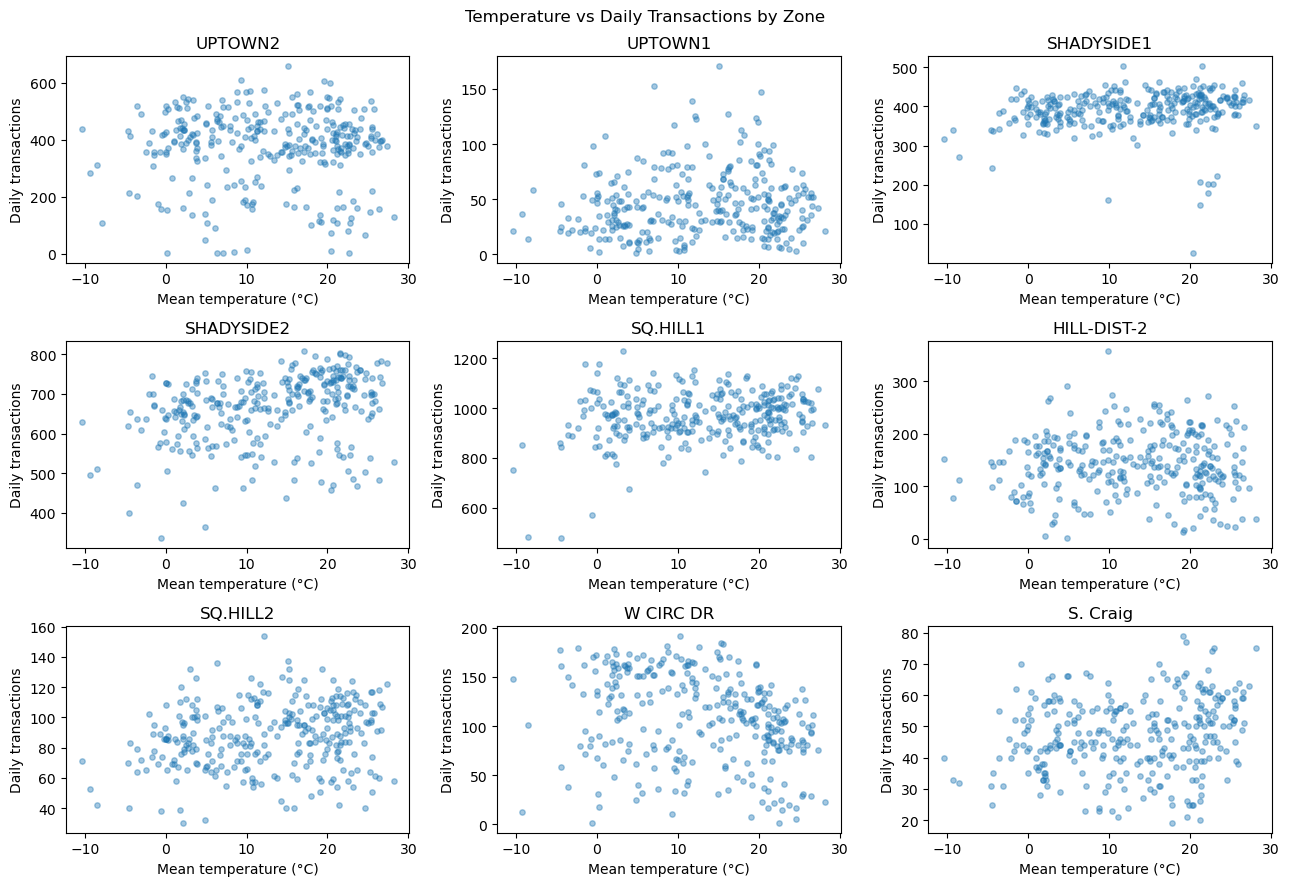

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# dropna for this analysis
temp_data = daily_weather.dropna(
    subset=["total_transactions", "temp_mean"]
).copy()

fig, axes = plt.subplots(3, 3, figsize=(13, 9))

for ax, zone in zip(axes.flat, forecast_zones):
    part = temp_data[temp_data["zone"] == zone]

    ax.scatter(
        part["temp_mean"],
        part["total_transactions"],
        alpha=0.4,
        s=15
    )

    ax.set_title(zone)
    ax.set_xlabel("Mean temperature (°C)")
    ax.set_ylabel("Daily transactions")

plt.suptitle("Temperature vs Daily Transactions by Zone")
plt.tight_layout()
plt.show()

### 3.8 Snow and Transaction Relations

count   mean
zone        snow_group              
HILL-DIST-2 No snow        54  144.0
            Snow           20  103.7
S. Craig    No snow        54   47.0
            Snow           20   44.5
SHADYSIDE1  No snow        54  382.4
            Snow           20  373.2
SHADYSIDE2  No snow        54  645.8
            Snow           20  571.2
SQ.HILL1    No snow        54  974.1
            Snow           20  884.6
SQ.HILL2    No snow        54   82.8
            Snow           20   73.0
UPTOWN1     No snow        54   38.7
            Snow           21   36.5
UPTOWN2     No snow        55  386.8
            Snow           21  324.1
W CIRC DR   No snow        54  120.9
            Snow           20   87.6

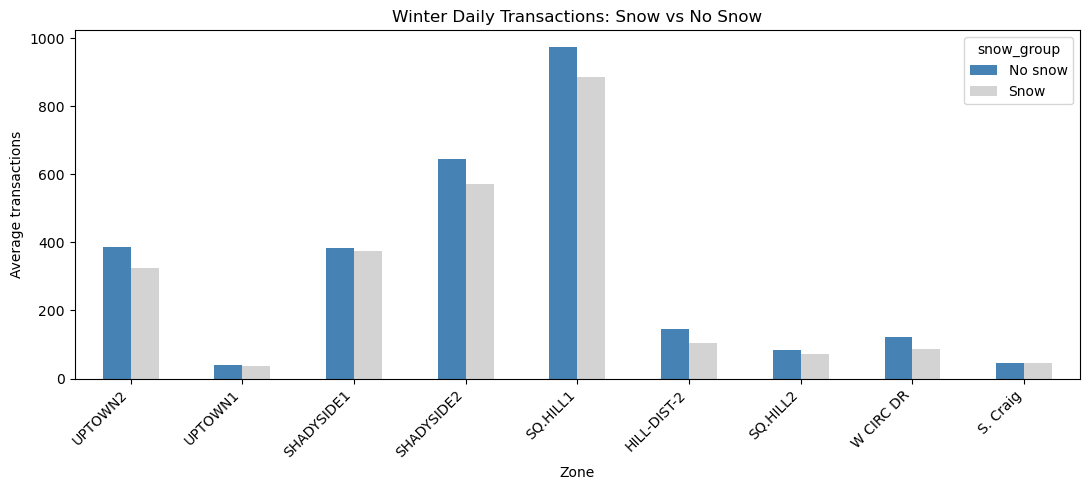

In [ ]:
snow_data = daily_weather.dropna(
    subset=["total_transactions", "snow_cm"]
).copy()

snow_data = snow_data[
    snow_data["date"].dt.month.isin([12, 1, 2])
].copy()

snow_data["snow_group"] = np.where(
    snow_data["snow_cm"] > 0,
    "Snow",
    "No snow"
)

snow_summary = (
    snow_data
    .groupby(["zone", "snow_group"])["total_transactions"]
    .agg(["count", "mean"])
    .round(1)
)

display(snow_summary)

snow_summary["mean"].unstack().reindex(forecast_zones).plot(
    kind="bar",
    figsize=(11, 5),
    color=["steelblue", "lightgray"]
)

plt.title("Winter Daily Transactions: Snow vs No Snow")
plt.xlabel("Zone")
plt.ylabel("Average transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3.9 Rain and Transaction Relations

count   mean
zone        rain_group                
HILL-DIST-2 Rain < 1 mm     148  1.022
            Rain >= 1 mm    109  0.970
S. Craig    Rain < 1 mm     148  1.005
            Rain >= 1 mm    109  0.993
SHADYSIDE1  Rain < 1 mm     148  1.001
            Rain >= 1 mm    110  0.999
SHADYSIDE2  Rain < 1 mm     148  1.005
            Rain >= 1 mm    109  0.993
SQ.HILL1    Rain < 1 mm     148  0.994
            Rain >= 1 mm    109  1.008
SQ.HILL2    Rain < 1 mm     148  1.004
            Rain >= 1 mm    109  0.995
UPTOWN1     Rain < 1 mm     149  1.028
            Rain >= 1 mm    109  0.961
UPTOWN2     Rain < 1 mm     150  1.005
            Rain >= 1 mm    111  0.994
W CIRC DR   Rain < 1 mm     148  1.024
            Rain >= 1 mm    109  0.968

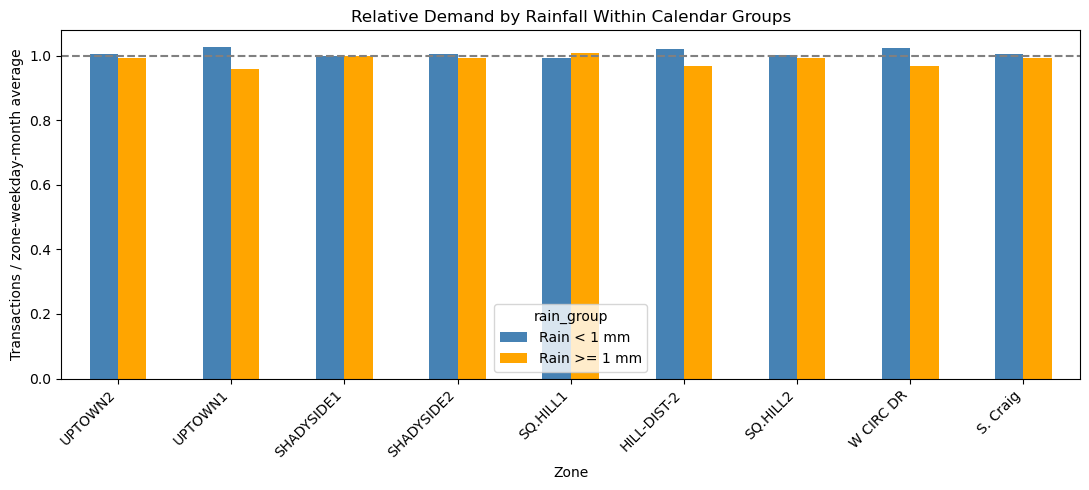

In [ ]:
rain_data = daily_weather.dropna(
    subset=["total_transactions", "rain_mm"]
).copy()

rain_data["rain_group"] = np.where(
    rain_data["rain_mm"] >= 1,
    "Rain >= 1 mm",
    "Rain < 1 mm"
)

adjusted_rain = rain_data.copy()

adjusted_rain["weekday_num"] = adjusted_rain["date"].dt.dayofweek
adjusted_rain["year_month"] = (
    adjusted_rain["date"].dt.to_period("M").astype(str)
)

comparison_groups = ["zone", "weekday_num", "year_month"]

adjusted_rain["group_mean"] = (
    adjusted_rain
    .groupby(comparison_groups)["total_transactions"]
    .transform("mean")
)

# except 0
adjusted_rain["relative_demand"] = (
    adjusted_rain["total_transactions"]
    / adjusted_rain["group_mean"].replace(0, np.nan)
)

has_both_groups = (
    adjusted_rain
    .groupby(comparison_groups)["rain_group"]
    .transform("nunique")
    .eq(2)
)

adjusted_rain = adjusted_rain[
    has_both_groups
].dropna(subset=["relative_demand"])

adjusted_summary = (
    adjusted_rain
    .groupby(["zone", "rain_group"])["relative_demand"]
    .agg(["count", "mean"])
    .round(3)
)

display(adjusted_summary)

if not adjusted_summary.empty:
    adjusted_summary["mean"].unstack().reindex(forecast_zones).plot(
        kind="bar",
        figsize=(11, 5),
        color=["steelblue", "orange"]
    )

    plt.axhline(1, color="gray", linestyle="--")
    plt.title("Relative Demand by Rainfall Within Calendar Groups")
    plt.xlabel("Zone")
    plt.ylabel("Transactions / zone-weekday-month average")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No comparable groups contain both rainfall categories.")

**Finding** From the graph, we can see that snow or rainy days have less transactions on parking. So we include those features in the data.

### 4. Simple Feature Preparation
Prepare calendar, historical demand, and weather inputs for the modeling teammate. This notebook does not fit forecasting models.

| Field | Use |
|---|---|
| total_transactions | Forecast target Y: daily paid transactions |
| zone | Different baseline demand by zone |
| day_of_week / is_weekend | Weekly calendar patterns |
| month | Monthly calendar patterns |
| lag_1 / lag_7 | Yesterday’s demand / demand on the same weekday last week |
| rolling_mean_7 / rolling_mean_28 | Average demand over the previous 7 / 28 days, excluding today |
| rain_mm | Daily rainfall in millimeters |
| snow_cm | Daily snowfall in centimeters |


Rainfall and snowfall are matched by zone and date. Missing values remain unknown, and lag and rolling features use only past transactions. Future forecasts require weather information available at the forecast date; historical normal and demand thresholds must be estimated from each training window only.

In [ ]:
# use combined data
model_data = daily_weather.copy()

model_data["date"] = pd.to_datetime(model_data["date"])
model_data = model_data.sort_values(
    ["zone", "date"]
).reset_index(drop=True)

# Calendar features
model_data["day_of_week"] = model_data["date"].dt.dayofweek
model_data["is_weekend"] = (
    model_data["day_of_week"].isin([5, 6]).astype(int)
)
model_data["month"] = model_data["date"].dt.month

# Weather features: rain & snow
for col in ["rain_mm", "snow_cm"]:
    model_data[col] = pd.to_numeric(
        model_data[col], errors="coerce"
    )

# Lag features
for lag in [1, 7]:
    model_data[f"lag_{lag}"] = (
        model_data.groupby("zone")["total_transactions"]
        .shift(lag)
    )

# Rolling features
for window in [7, 28]:
    model_data[f"rolling_mean_{window}"] = (
        model_data.groupby("zone")["total_transactions"]
        .transform(
            lambda x: x.shift(1).rolling(
                window, min_periods=window
            ).mean()
        )
    )

feature_cols = [
    "day_of_week",
    "is_weekend",
    "month",
    "lag_1",
    "lag_7",
    "rolling_mean_7",
    "rolling_mean_28",
    "rain_mm",
    "snow_cm"
]

display(
    model_data[
        ["zone", "date", "total_transactions"] + feature_cols
    ].head(35)
)

print("Feature missing values:")
display(model_data[feature_cols].isna().sum())


,zone,date,total_transactions,day_of_week,is_weekend,month,lag_1,lag_7,rolling_mean_7,rolling_mean_28,rain_mm,snow_cm
0,HILL-DIST-2,2023-11-01,143.0,2,0,11,NaN,NaN,NaN,NaN,0.0,0.07
1,HILL-DIST-2,2023-11-02,157.0,3,0,11,143.0,NaN,NaN,NaN,0.0,0.00
2,HILL-DIST-2,2023-11-03,140.0,4,0,11,157.0,NaN,NaN,NaN,0.0,0.00
3,HILL-DIST-2,2023-11-04,70.0,5,1,11,140.0,NaN,NaN,NaN,0.1,0.00
4,HILL-DIST-2,2023-11-05,NaN,6,1,11,70.0,NaN,NaN,NaN,0.0,0.00
5,HILL-DIST-2,2023-11-06,127.0,0,0,11,NaN,NaN,NaN,NaN,0.0,0.00
6,HILL-DIST-2,2023-11-07,107.0,1,0,11,127.0,NaN,NaN,NaN,0.1,0.00
7,HILL-DIST-2,2023-11-08,128.0,2,0,11,107.0,143.0,NaN,NaN,0.0,0.00
8,HILL-DIST-2,2023-11-09,156.0,3,0,11,128.0,157.0,NaN,NaN,2.4,0.00
9,HILL-DIST-2,2023-11-10,NaN,4,0,11,156.0,140.0,NaN,NaN,0.0,0.00


Feature missing values:


day_of_week           0
is_weekend            0
month                 0
lag_1               589
lag_7               634
rolling_mean_7     3280
rolling_mean_28    3294
rain_mm               0
snow_cm               0
dtype: int64

## 5. Summary
The dataset covers nine zones with 366 calendar days each and 580 missing zone-day targets, with the highest average transaction volumes in SQ.HILL1 and SHADYSIDE2 and mobile transactions contributing 66.6% of the paired-channel total.

**Limitations:** Paid transactions measure payment activity, not occupancy. Current payment points do not provide historical parking capacity. Exact price recommendations need stronger rate and causal evidence. This study window is historical; forecasts from its end would concern November 2024. Refresh the data before making a present-day forecast.


## 6. ETS and ARIMA Backtesting

### 6.1 Modeling Plan
Flow: visualize → ADF / differencing / ACF / PACF → four rolling 3-year training windows → calculate_metrics → run_models → compare forecasts → select and refit.

In [ ]:
# %pip install statsmodels pmdarima jinja2
import warnings
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
import pmdarima as pm

model_zones = list(forecast_zones)  # all nine selected zones
horizon = 7
seasonal_period = 7
training_lookback_days = 1095  # fixed 3-year training window for each forecast origin

# Rebuild daily transaction targets from the full historical CSV rather than the
# one-year `model_data` panel. Keep the original study end date and final holdout.
core_history_source = transactions.loc[
    transactions["zone"].isin(model_zones),
    ["_id", "zone", "start"] + count_cols
].copy()
core_history_cutoff = min(
    pd.Timestamp(end_date) - pd.Timedelta(days=1),
    core_history_source["start"].dt.normalize().max()
)
core_history_source = core_history_source.loc[
    core_history_source["start"].dt.normalize().le(core_history_cutoff)
].copy()

core_content_cols = [c for c in core_history_source.columns if c != "_id"]
core_duplicate_rows = core_history_source.duplicated(subset=core_content_cols)
print("Historical duplicate content rows removed:", int(core_duplicate_rows.sum()))
core_history_source = core_history_source.loc[~core_duplicate_rows].copy()
core_conflicts = core_history_source.duplicated(["zone", "start"], keep=False)
if core_conflicts.any():
    display(core_history_source.loc[core_conflicts].sort_values(["zone", "start"]).head(20))
    raise ValueError("Historical transaction records conflict at the same zone/time; review before modeling.")

for col in count_cols:
    core_history_source[col] = pd.to_numeric(core_history_source[col], errors="coerce")
    invalid_count = (
        (core_history_source[col] < 0)
        | (core_history_source[col].notna() & core_history_source[col].mod(1).ne(0))
    )
    print(col, "invalid historical counts set to NaN:", int(invalid_count.sum()))
    core_history_source.loc[invalid_count, col] = np.nan

core_history_source["date"] = core_history_source["start"].dt.normalize()
core_groups = core_history_source.groupby(["zone", "date"])
core_daily_counts = core_groups[count_cols].sum(min_count=1)
core_partial_days = core_groups[count_cols].count().lt(core_groups.size(), axis=0)
core_daily_counts = core_daily_counts.mask(core_partial_days)
core_daily_counts["total_transactions"] = core_daily_counts[count_cols].sum(axis=1, min_count=2)

core_history_start = core_history_source["date"].min()
core_calendar = pd.date_range(core_history_start, core_history_cutoff, freq="D")
core_historical_targets = (
    core_daily_counts["total_transactions"]
    .unstack("zone")
    .reindex(index=core_calendar, columns=model_zones)
)
print("Model target history:", core_calendar.min().date(), "to", core_calendar.max().date())
print("Training window per forecast origin:", training_lookback_days, "days")
display(core_historical_targets.notna().sum().rename("usable_historical_days").to_frame())

series_by_zone = {}
for zone in model_zones:
    y = core_historical_targets[zone].astype(float).asfreq("D")
    if np.isinf(y).any() or y.dropna().lt(0).any():
        raise ValueError(f"{zone}: invalid transaction targets.")
    series_by_zone[zone] = y

calendar_end = core_history_cutoff
holdout_start = calendar_end - pd.Timedelta(days=horizon - 1)
backtest_periods = {}
for k in range(4):
    test_start = holdout_start - pd.Timedelta(days=(4 - k) * horizon)
    test_end = test_start + pd.Timedelta(days=horizon - 1)
    backtest_periods[f'Week {k + 1}: {test_start:%m/%d}–{test_end:%m/%d}'] = (test_start, test_end)
print('Validation windows:', backtest_periods)
print('Untouched holdout:', holdout_start.date(), 'to', calendar_end.date())


def fixed_window_train(y, test_start):
    """Return only the 1,095 calendar days before this forecast origin."""
    window_start = test_start - pd.Timedelta(days=training_lookback_days)
    return y.loc[(y.index >= window_start) & (y.index < test_start)]


def prepare_train(raw_train):
    # count from this training
    train = raw_train.copy().astype(float)
    if train.notna().sum() < 2 * seasonal_period:
        raise ValueError('Fewer than two weeks of observed training targets.')
    weekday_means = train.groupby(train.index.dayofweek).mean()
    fill_values = pd.Series(train.index.dayofweek, index=train.index).map(weekday_means)
    train = train.fillna(fill_values).fillna(train.mean())
    return train

period_summary = []
for zone, y in series_by_zone.items():
    for period, (test_start, test_end) in backtest_periods.items():
        train = fixed_window_train(y, test_start)
        test = y.reindex(pd.date_range(test_start, test_end, freq='D'))
        period_summary.append({
            'Zone': zone, 'Backtest Period': period,
            'Train Start': train.index.min(), 'Train End': train.index.max(),
            'Test Start': test_start, 'Test End': test_end,
            'Training Days': len(train), 'Imputed Training Days': train.isna().sum(),
            'Test Days': len(test), 'Observed Test Days': test.notna().sum()
        })
period_summary_df = pd.DataFrame(period_summary)
display(period_summary_df)
if (period_summary_df['Observed Test Days'] == 0).any():
    raise ValueError('A validation window has no observed targets. Review missing dates.')

Historical duplicate content rows removed: 0
meter_transactions invalid historical counts set to NaN: 0
mobile_transactions invalid historical counts set to NaN: 0
Model target history: 2014-01-02 to 2024-10-31
Training window per forecast origin: 1095 days


,usable_historical_days
zone,
UPTOWN2,3292
UPTOWN1,3261
SHADYSIDE1,3254
SHADYSIDE2,3255
SQ.HILL1,3258
HILL-DIST-2,3211
SQ.HILL2,3254
W CIRC DR,2879
S. Craig,3249


Validation windows: {'Week 1: 09/27–10/03': (Timestamp('2024-09-27 00:00:00'), Timestamp('2024-10-03 00:00:00')), 'Week 2: 10/04–10/10': (Timestamp('2024-10-04 00:00:00'), Timestamp('2024-10-10 00:00:00')), 'Week 3: 10/11–10/17': (Timestamp('2024-10-11 00:00:00'), Timestamp('2024-10-17 00:00:00')), 'Week 4: 10/18–10/24': (Timestamp('2024-10-18 00:00:00'), Timestamp('2024-10-24 00:00:00'))}
Untouched holdout: 2024-10-25 to 2024-10-31


,Zone,Backtest Period,Train Start,Train End,Test Start,Test End,Training Days,Imputed Training Days,Test Days,Observed Test Days
0,UPTOWN2,Week 1: 09/27–10/03,2021-09-28,2024-09-26,2024-09-27,2024-10-03,1095,180,7,6
1,UPTOWN2,Week 2: 10/04–10/10,2021-10-05,2024-10-03,2024-10-04,2024-10-10,1095,180,7,6
2,UPTOWN2,Week 3: 10/11–10/17,2021-10-12,2024-10-10,2024-10-11,2024-10-17,1095,180,7,6
3,UPTOWN2,Week 4: 10/18–10/24,2021-10-19,2024-10-17,2024-10-18,2024-10-24,1095,180,7,6
4,UPTOWN1,Week 1: 09/27–10/03,2021-09-28,2024-09-26,2024-09-27,2024-10-03,1095,187,7,6
5,UPTOWN1,Week 2: 10/04–10/10,2021-10-05,2024-10-03,2024-10-04,2024-10-10,1095,187,7,6
6,UPTOWN1,Week 3: 10/11–10/17,2021-10-12,2024-10-10,2024-10-11,2024-10-17,1095,187,7,6
7,UPTOWN1,Week 4: 10/18–10/24,2021-10-19,2024-10-17,2024-10-18,2024-10-24,1095,187,7,6
8,SHADYSIDE1,Week 1: 09/27–10/03,2021-09-28,2024-09-26,2024-09-27,2024-10-03,1095,203,7,6
9,SHADYSIDE1,Week 2: 10/04–10/10,2021-10-05,2024-10-03,2024-10-04,2024-10-10,1095,203,7,6


### 6.2 Stationarity and Weekly Seasonality
Automatically inspect all nine forecast_zones, even when model_zones is reduced for a quick model trial. Each zone has a 3 × 3 figure: the time series, ACF, and PACF for the original 3-year training series, first difference, and first + weekly difference. The combined ADF table has three rows per zone.

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

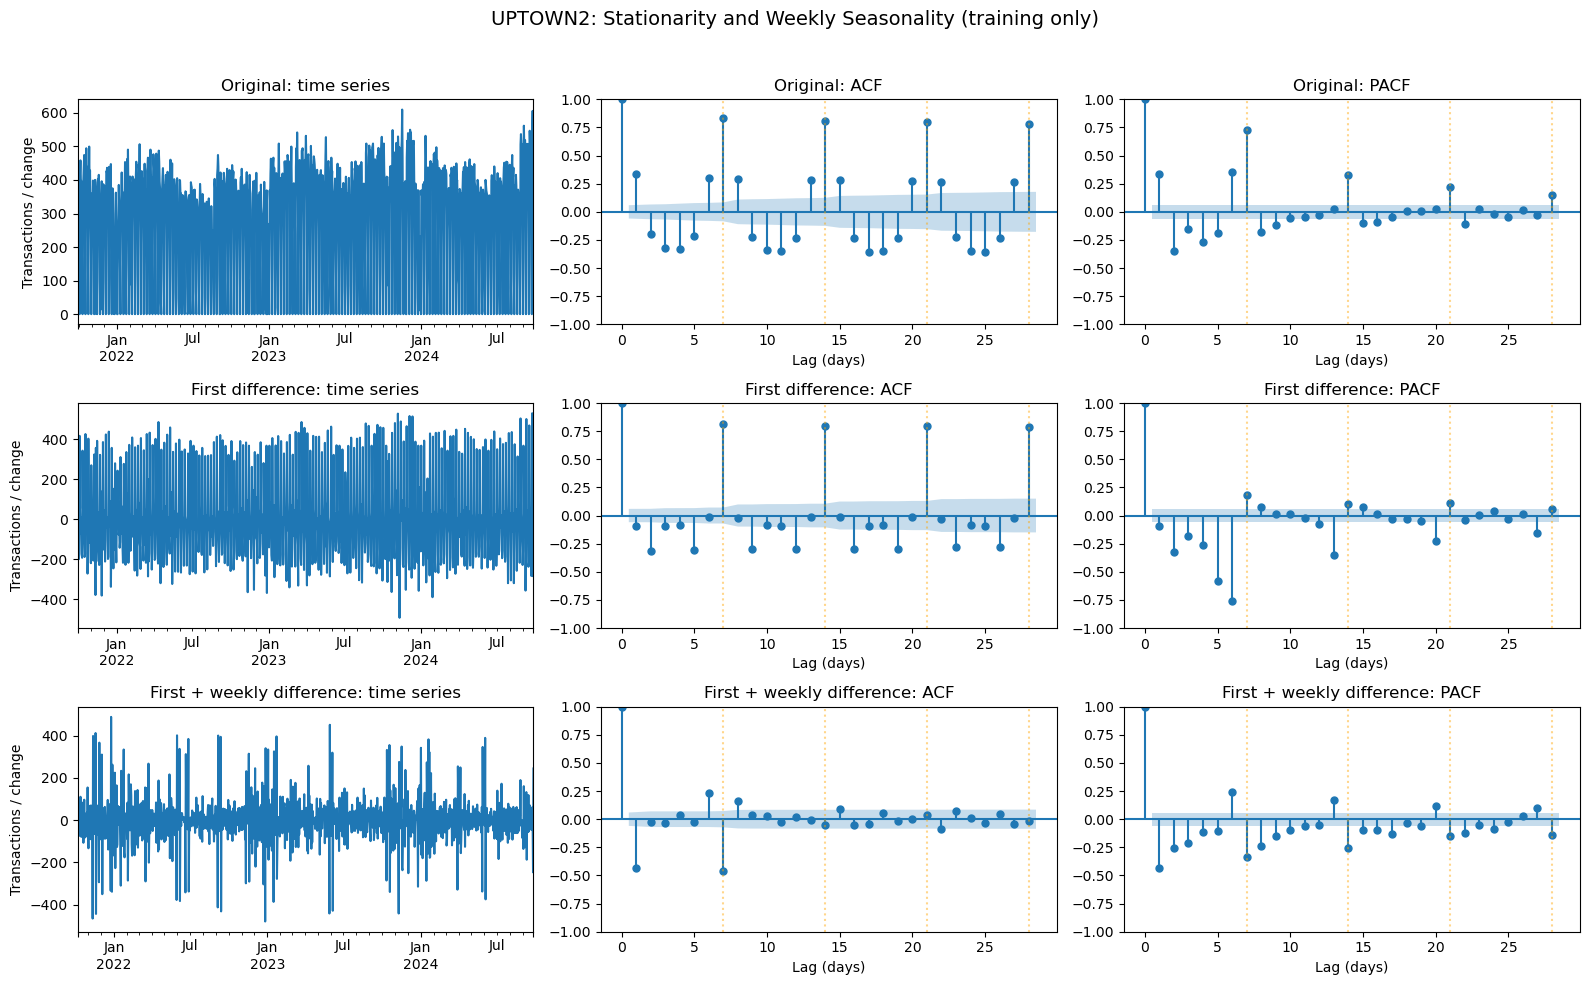

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

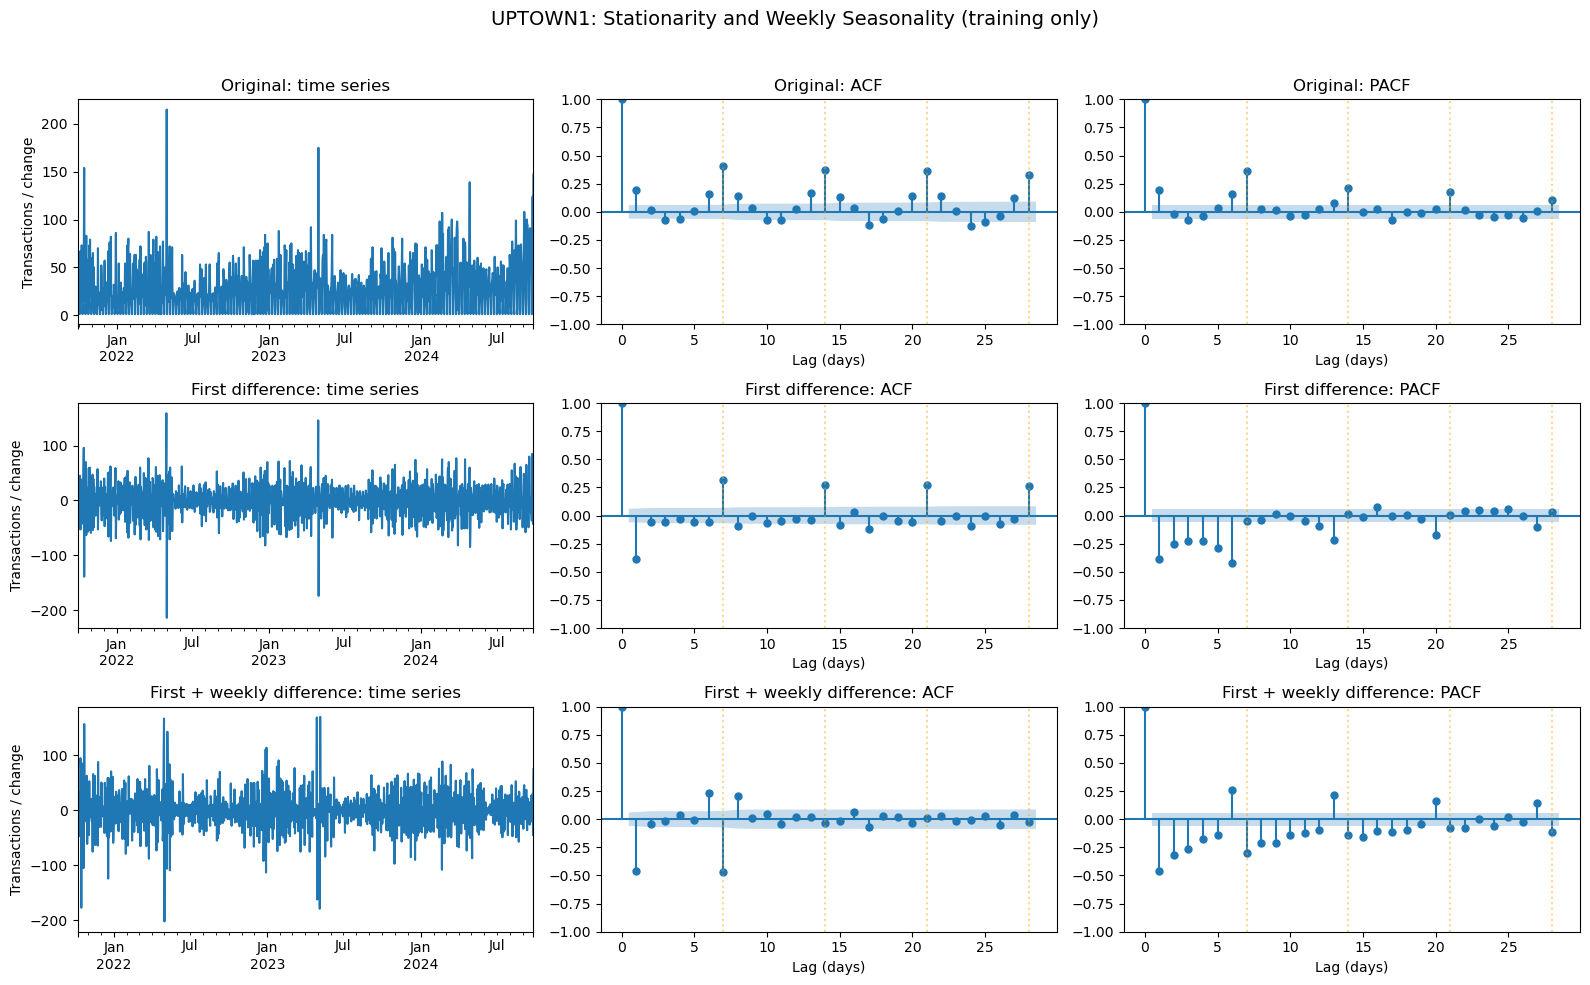

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

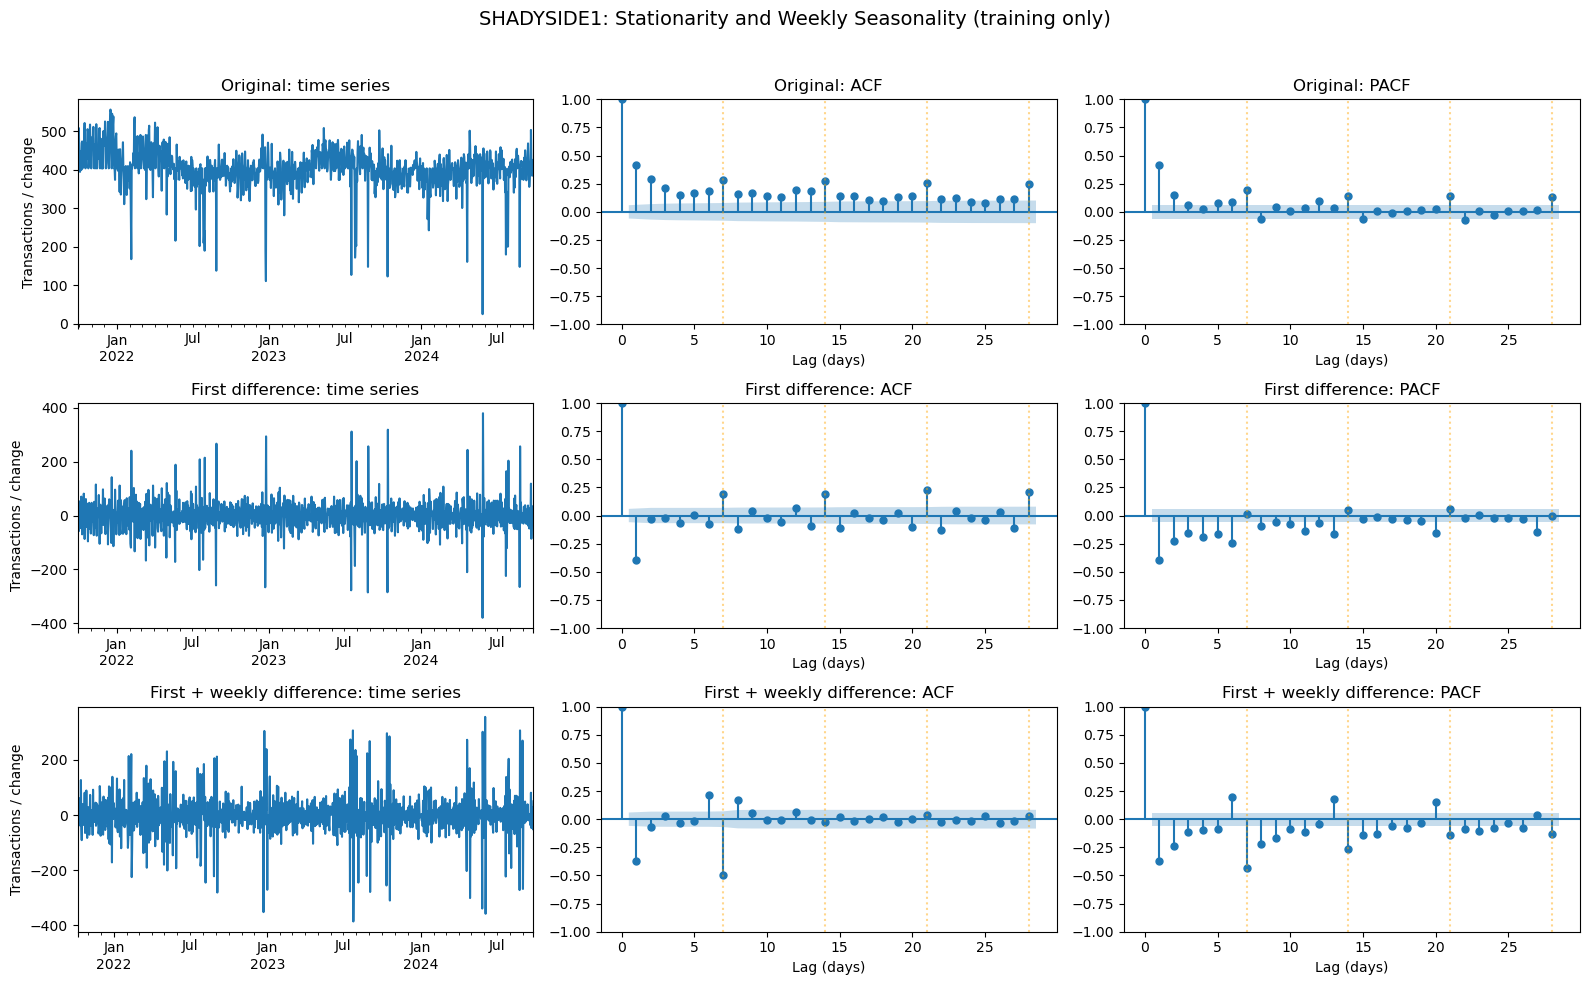

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

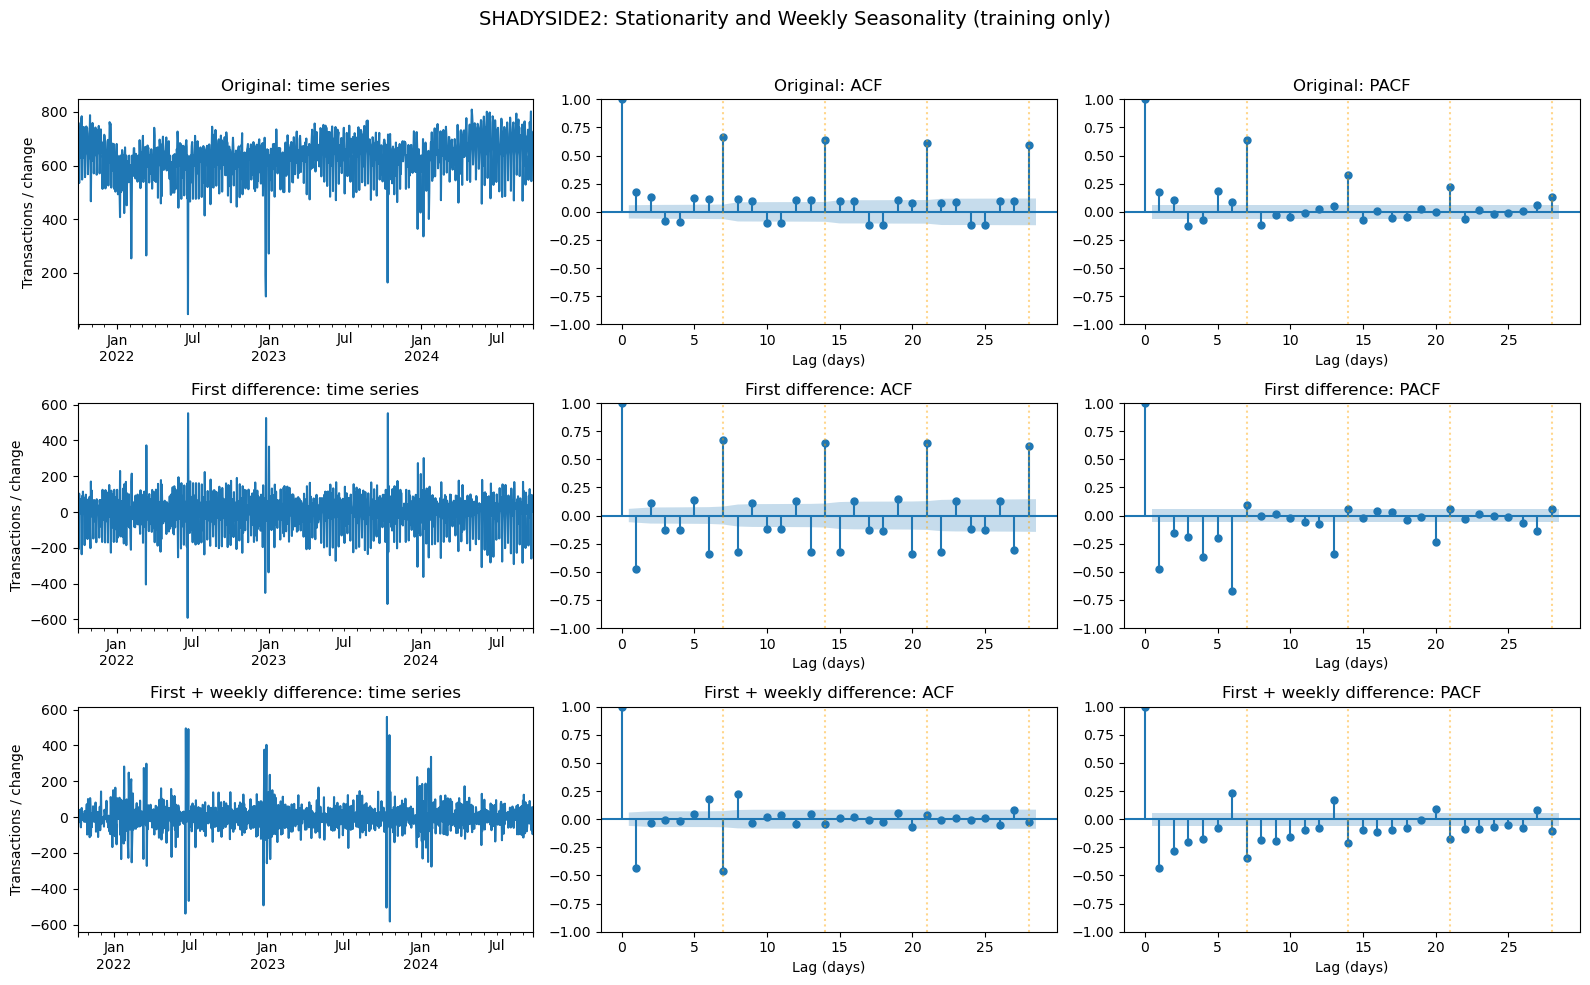

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

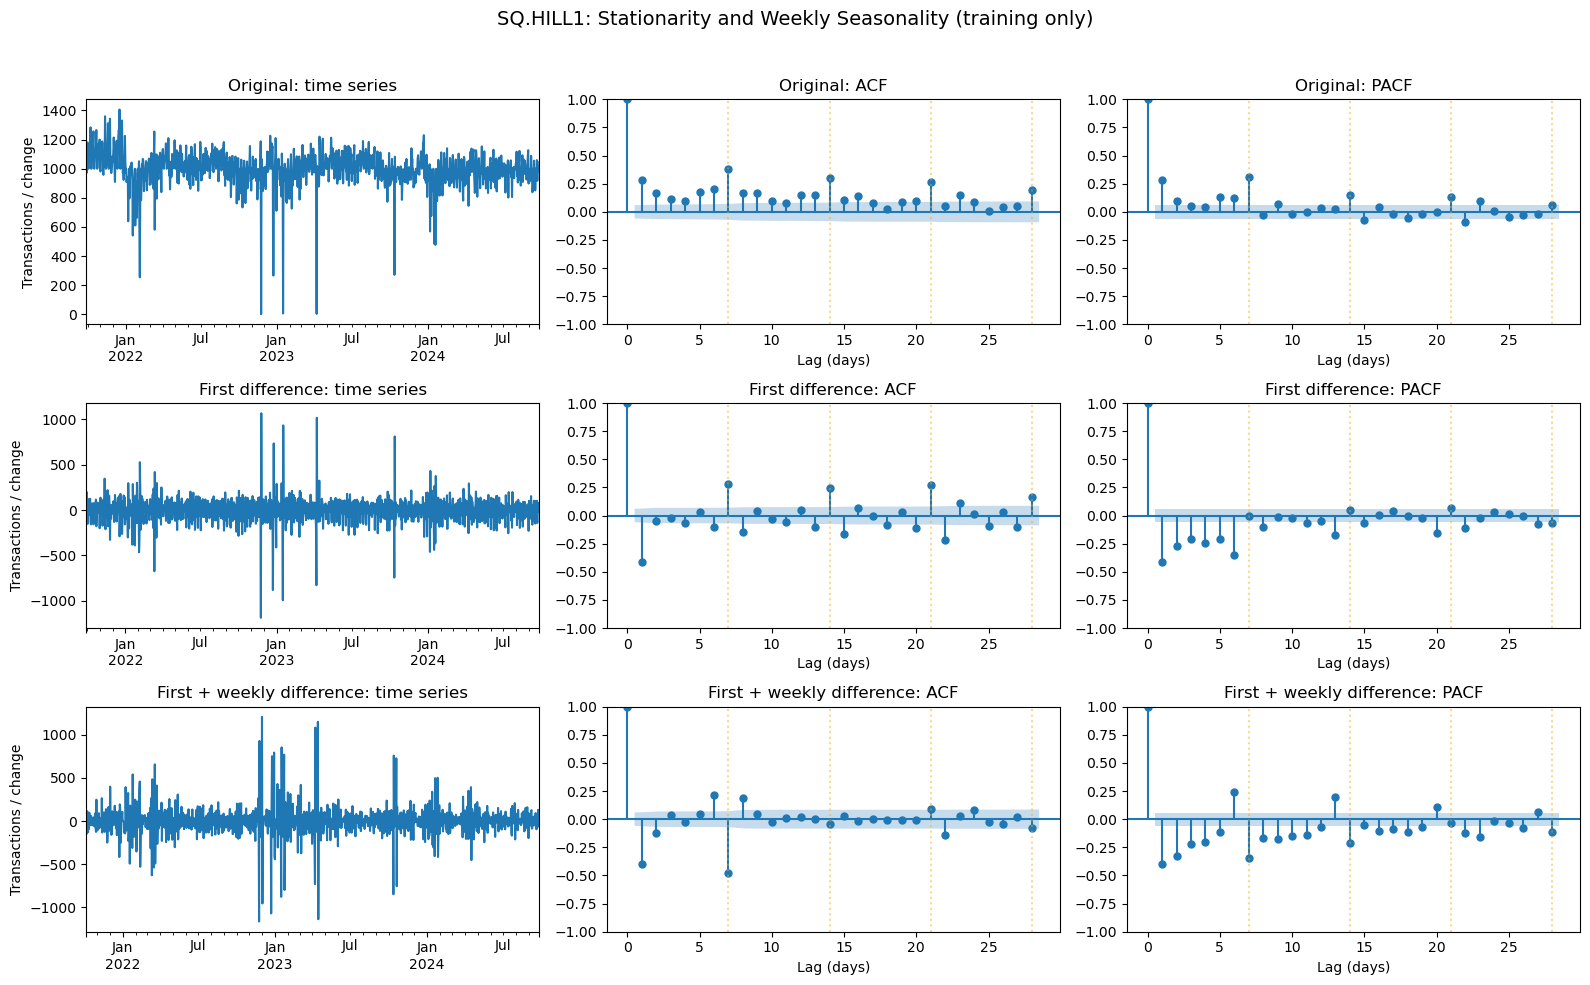

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

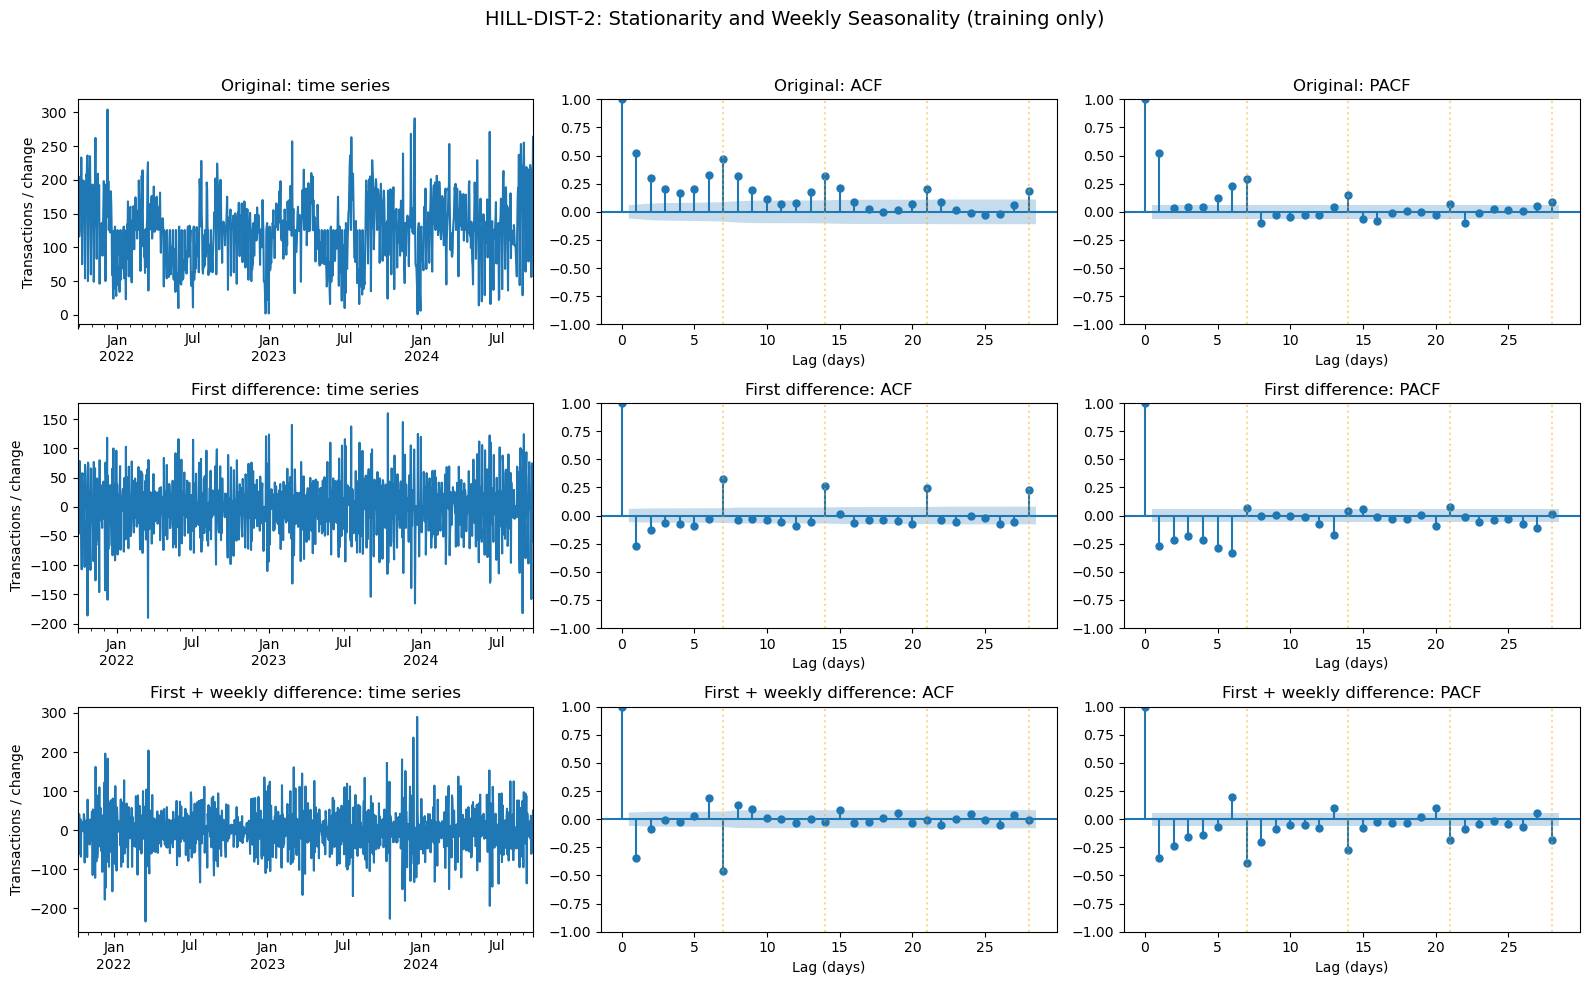

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

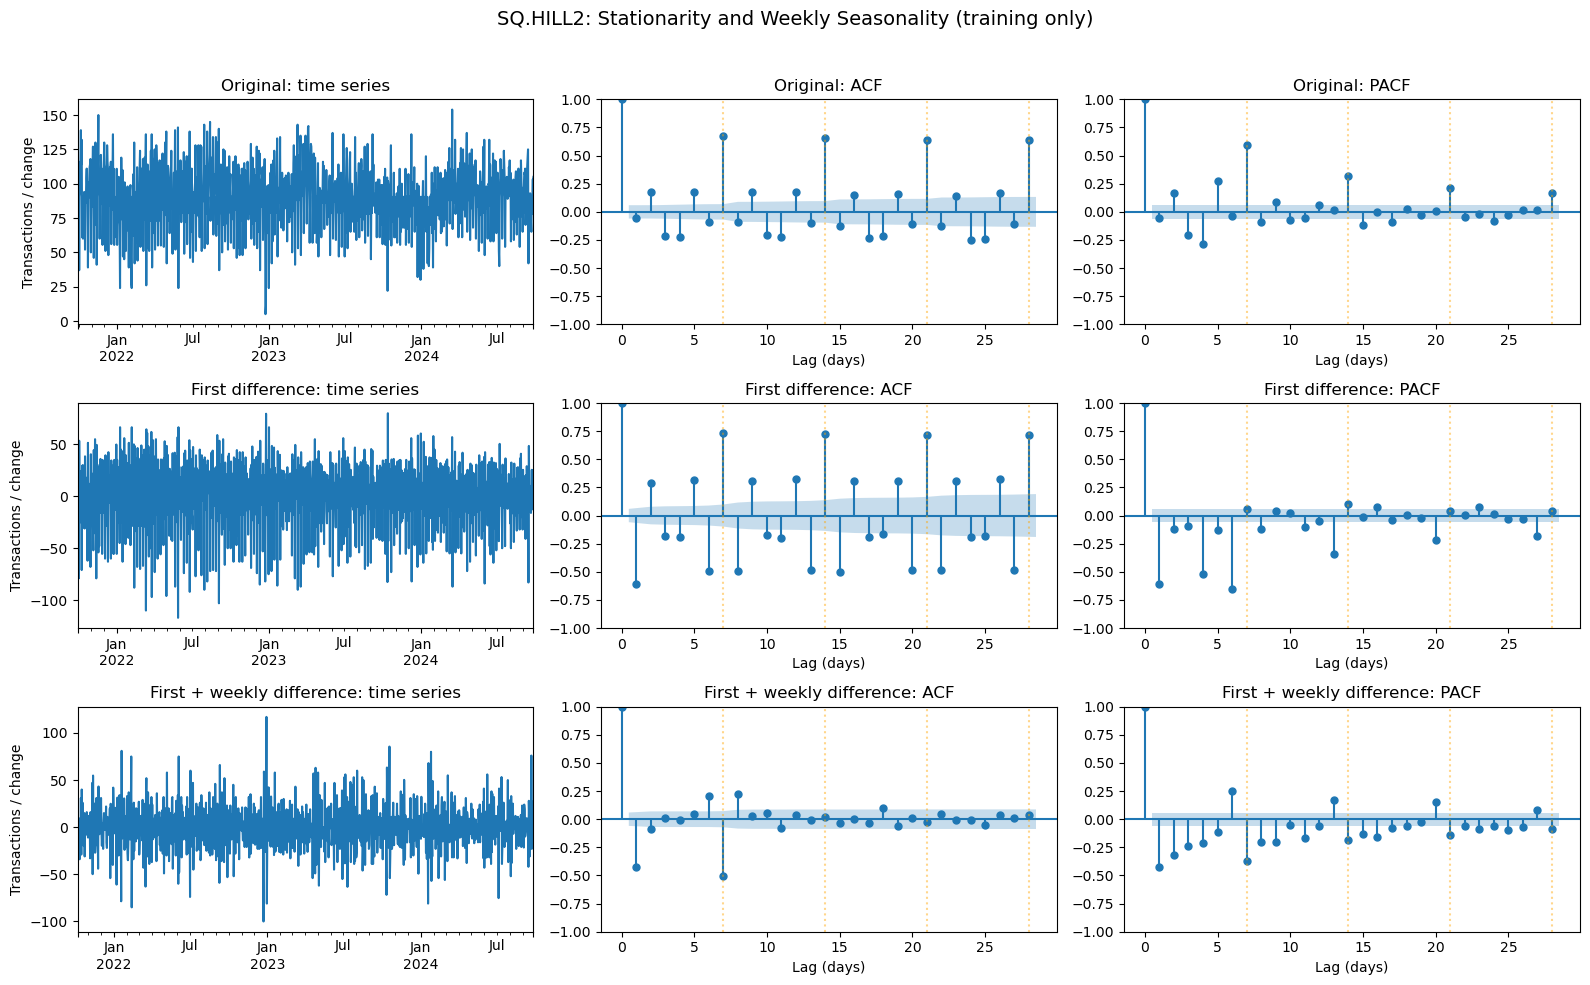

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

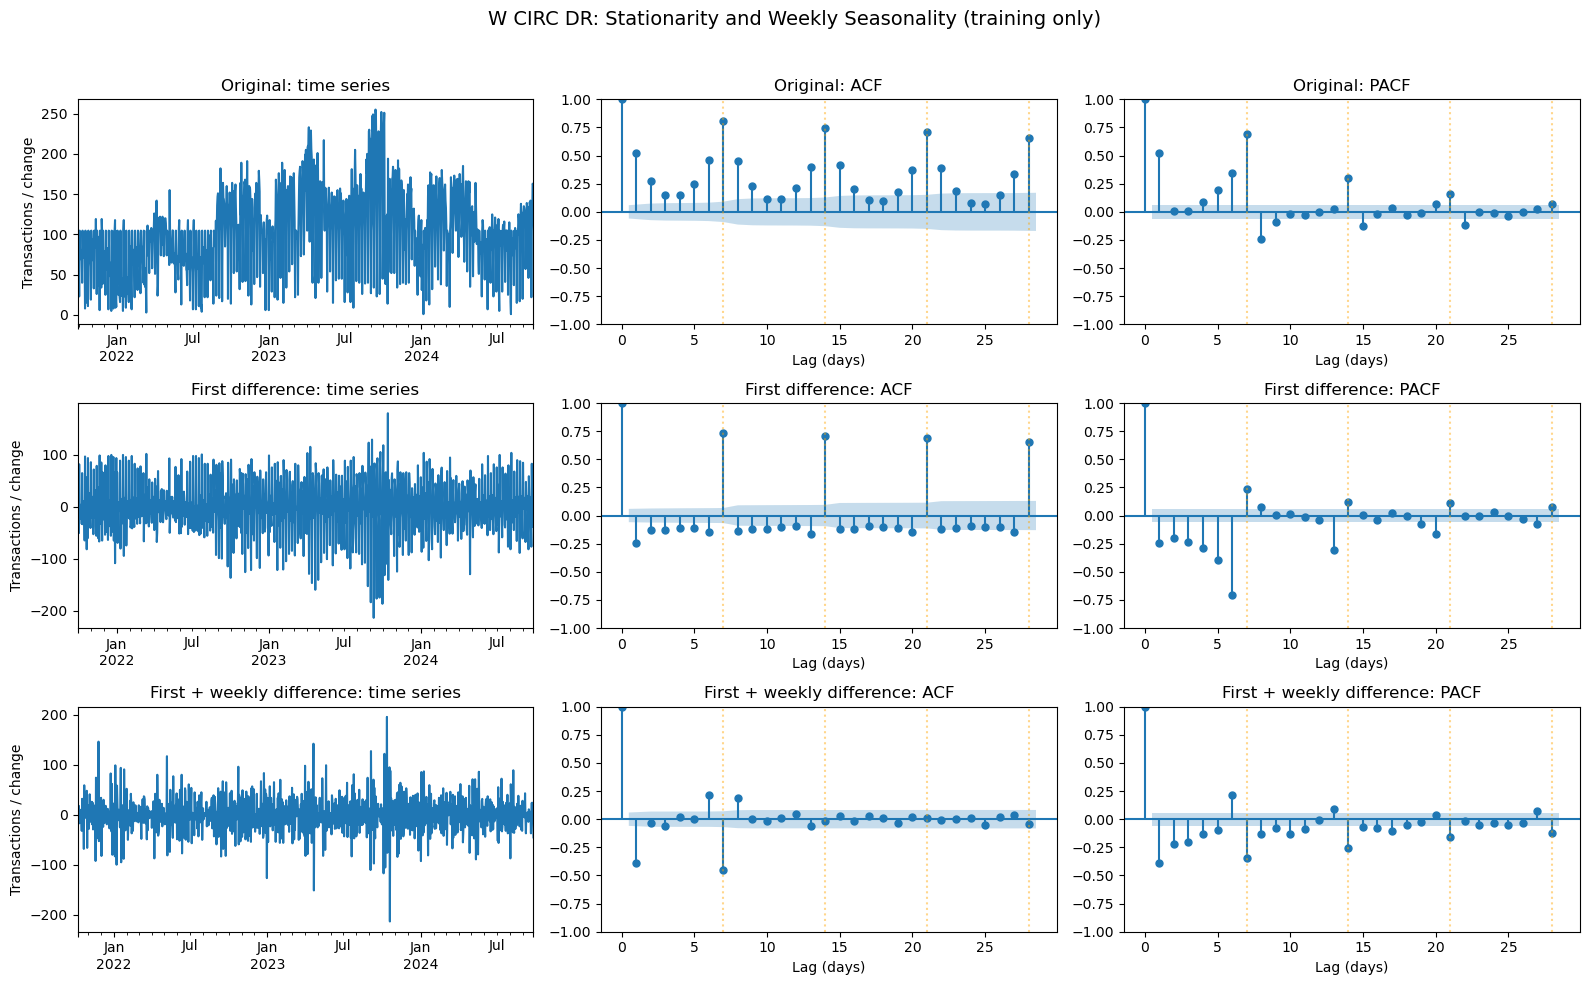

/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jcp6000000gn/T/ipykernel_7156/1483367393.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, autolag='AIC')
/var/folders/k9/z8r59nnj0nq7fw3p00jc

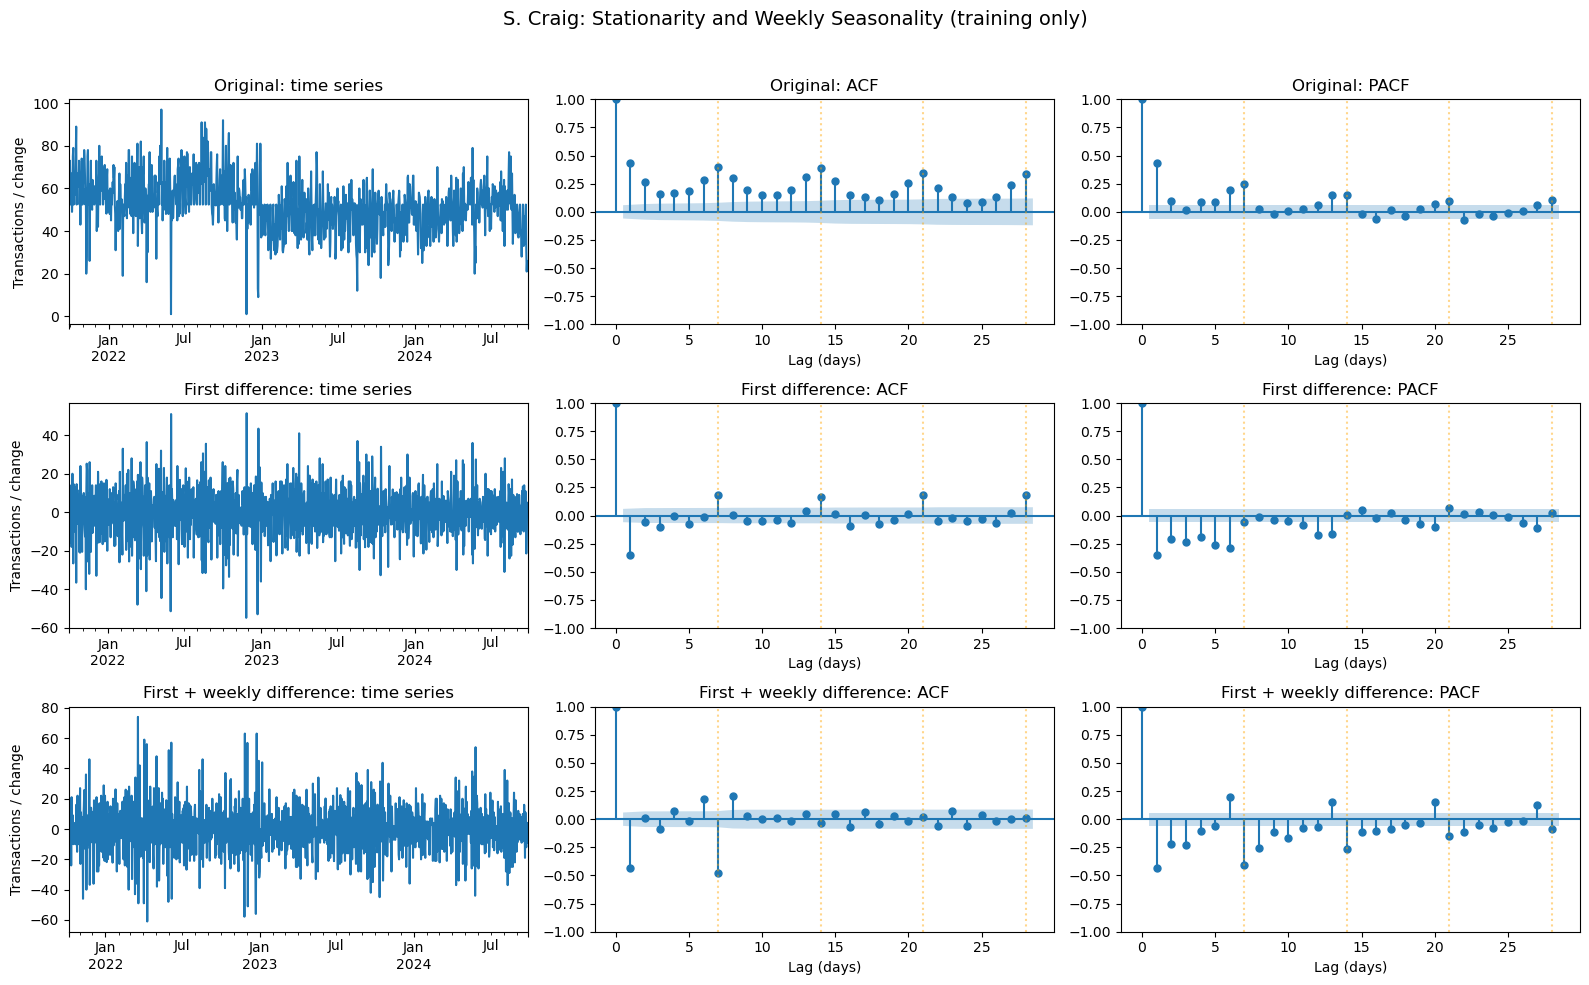

ADF results for all zones: three series per zone


,Zone,Series,Training Start,Training End,Imputed Training Days,N Values,ADF Statistic,p-value,ADF Lags,ADF Observations,Critical Value 5%,Conclusion (5%),Status
0,UPTOWN2,Original,2021-09-28,2024-09-26,180,1095,-4.093607,9.923603e-04,21,1073,-2.864237,Reject unit root,ok
1,UPTOWN2,First difference,2021-09-28,2024-09-26,180,1094,-11.309801,1.247130e-20,20,1073,-2.864237,Reject unit root,ok
2,UPTOWN2,First + weekly difference,2021-09-28,2024-09-26,180,1087,-12.848134,5.424768e-24,22,1064,-2.864260,Reject unit root,ok
3,UPTOWN1,Original,2021-09-28,2024-09-26,187,1095,-1.763140,3.989093e-01,20,1074,-2.864235,Do not reject unit root,ok
4,UPTOWN1,First difference,2021-09-28,2024-09-26,187,1094,-13.553219,2.387149e-25,19,1074,-2.864235,Reject unit root,ok
5,UPTOWN1,First + weekly difference,2021-09-28,2024-09-26,187,1087,-13.802132,8.532747e-26,21,1065,-2.864258,Reject unit root,ok
6,SHADYSIDE1,Original,2021-09-28,2024-09-26,203,1095,-4.123108,8.867643e-04,21,1073,-2.864237,Reject unit root,ok
7,SHADYSIDE1,First difference,2021-09-28,2024-09-26,203,1094,-11.169191,2.666796e-20,20,1073,-2.864237,Reject unit root,ok
8,SHADYSIDE1,First + weekly difference,2021-09-28,2024-09-26,203,1087,-12.921176,3.871709e-24,22,1064,-2.864260,Reject unit root,ok
9,SHADYSIDE2,Original,2021-09-28,2024-09-26,203,1095,-3.177177,2.134434e-02,21,1073,-2.864237,Reject unit root,ok


ADF p-values: p < 0.05 rejects the unit-root null


Series,Original,First difference,First + weekly difference
Zone,,,
UPTOWN2,0.000992,1.247130e-20,5.424768e-24
UPTOWN1,0.398909,2.387149e-25,8.532747e-26
SHADYSIDE1,0.000887,2.666796e-20,3.871709e-24
SHADYSIDE2,0.021344,7.361186e-21,1.239307e-24
SQ.HILL1,0.000772,3.160355e-19,1.371651e-25
HILL-DIST-2,0.000004,2.993493e-15,2.781236e-21
SQ.HILL2,0.001276,5.859323e-16,5.029722e-23
W CIRC DR,0.076052,1.005117e-16,2.012132e-24
S. Craig,0.032144,1.510472e-19,2.098038e-24


In [ ]:
# check zones
diagnostic_zones = list(forecast_zones)
first_test_start = min(start for start, end in backtest_periods.values())
adf_rows = []
diagnostic_series_by_zone = {}

for zone in diagnostic_zones:
    raw = series_by_zone[zone].astype(float).asfreq('D')
    train_raw = fixed_window_train(raw, first_test_start)
    if np.isinf(train_raw).any() or train_raw.dropna().lt(0).any():
        raise ValueError(f'{zone}: invalid training targets.')

    try:
        train_diag = prepare_train(train_raw)
    except ValueError as exc:
        print(f'{zone}: diagnostics skipped — {exc}')
        for label in ['Original', 'First difference', 'First + weekly difference']:
            adf_rows.append({'Zone': zone, 'Series': label,
                             'ADF Statistic': np.nan, 'p-value': np.nan,
                             'Conclusion (5%)': 'Not assessed', 'Status': str(exc)})
        continue

    first_diff = train_diag.diff().dropna()
    seasonal_diff = first_diff.diff(seasonal_period).dropna()
    versions = [('Original', train_diag),
                ('First difference', first_diff),
                ('First + weekly difference', seasonal_diff)]
    diagnostic_series_by_zone[zone] = dict(versions)
    fig, axes = plt.subplots(3, 3, figsize=(16, 10))

    for row, (label, values) in enumerate(versions):
        values.plot(ax=axes[row, 0], title=f'{label}: time series')
        axes[row, 0].set_ylabel('Transactions / change')
        record = {
            'Zone': zone, 'Series': label,
            'Training Start': train_diag.index.min(),
            'Training End': train_diag.index.max(),
            'Imputed Training Days': int(train_raw.isna().sum()),
            'N Values': len(values), 'ADF Statistic': np.nan,
            'p-value': np.nan, 'ADF Lags': np.nan, 'ADF Observations': np.nan,
            'Critical Value 5%': np.nan,
            'Conclusion (5%)': 'Not assessed', 'Status': 'ok'
        }
        if len(values) < 12 or values.nunique() <= 1:
            record['Status'] = 'Too few values or constant series'
        else:
            try:
                result = adfuller(values, autolag='AIC')
                record.update({
                    'ADF Statistic': result[0], 'p-value': result[1],
                    'ADF Lags': result[2], 'ADF Observations': result[3],
                    'Critical Value 5%': result[4]['5%'],
                    'Conclusion (5%)': ('Reject unit root' if result[1] < 0.05
                                        else 'Do not reject unit root')
                })
            except ValueError as exc:
                record['Status'] = str(exc)
        adf_rows.append(record)

        if len(values) > 10 and values.nunique() > 1:
            lags = min(28, len(values) // 2 - 1)
            plot_acf(values, lags=lags, ax=axes[row, 1],
                     title=f'{label}: ACF')
            plot_pacf(values, lags=lags, method='ywm', ax=axes[row, 2],
                      title=f'{label}: PACF')
            for ax in axes[row, 1:]:
                ax.set_xlabel('Lag (days)')
                for weekly_lag in range(seasonal_period, lags + 1, seasonal_period):
                    ax.axvline(weekly_lag, color='orange', linestyle=':', alpha=0.45)
        else:
            for ax, name in zip(axes[row, 1:], ['ACF', 'PACF']):
                ax.set_title(f'{label}: {name}')
                ax.text(0.5, 0.5, 'Too few values or constant series',
                        ha='center', va='center', transform=ax.transAxes)

    fig.suptitle(f'{zone}: Stationarity and Weekly Seasonality (training only)',
                 fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

adf_results_df = pd.DataFrame(adf_rows)
print('ADF results for all zones: three series per zone')
display(adf_results_df)
print('ADF p-values: p < 0.05 rejects the unit-root null')
adf_pvalues_df = (adf_results_df.pivot(index='Zone', columns='Series', values='p-value')
                 .reindex(diagnostic_zones)
                 .reindex(columns=['Original', 'First difference',
                                   'First + weekly difference']))
display(adf_pvalues_df)


### 6.3 Define Metrics and Model Function
RMSE is the selection metric, MAE provides a second error measure, and MAPE excludes zero actuals and can be unstable for low counts.

In [ ]:
def calculate_metrics(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    valid = np.isfinite(actual) & np.isfinite(predicted)
    a, p = actual[valid], predicted[valid]
    positive = a > 0
    return {
        'RMSE': np.sqrt(np.mean((a - p) ** 2)) if len(a) else np.nan,
        'MAE': np.mean(np.abs(a - p)) if len(a) else np.nan,
        'MAPE': np.mean(np.abs((a[positive] - p[positive]) / a[positive])) * 100 if positive.any() else np.nan,
        'N scored': len(a), 'N MAPE': int(positive.sum())
    }


def run_models(train, forecast_index, only_models=None):
    horizon = len(forecast_index)
    factories = {
        'SES': lambda: SimpleExpSmoothing(train, initialization_method='estimated').fit(),
        'Holt Additive': lambda: Holt(train, initialization_method='estimated').fit(),
        'Holt Damped': lambda: Holt(train, damped_trend=True, initialization_method='estimated').fit(),
        'ETS Add/Add': lambda: ExponentialSmoothing(train, trend='add', seasonal='add',
            seasonal_periods=seasonal_period, initialization_method='estimated').fit(),
        'ETS Add/Mul': lambda: ExponentialSmoothing(train, trend='add', seasonal='mul',
            seasonal_periods=seasonal_period, initialization_method='estimated').fit(),
        'Manual ARIMA(2,1,1)': lambda: ARIMA(train, order=(2, 1, 1)).fit(),
        'Auto ARIMA Non-seasonal': lambda: pm.auto_arima(train, start_p=0, start_q=0,
            max_p=3, max_q=3, d=None, test='adf', seasonal=False, stepwise=True,
            suppress_warnings=False, error_action='warn', trace=False),
        'Auto ARIMA Seasonal': lambda: pm.auto_arima(train, start_p=0, start_q=0,
            max_p=3, max_q=3, d=None, test='adf', seasonal=True, m=seasonal_period,
            start_P=0, start_Q=0, max_P=2, max_Q=2, D=1, stepwise=True,
            suppress_warnings=False, error_action='warn', trace=False)
    }
    names = list(factories) + ['Seasonal Naive'] if only_models is None else list(only_models)
    forecasts, information = {}, []
    for name in names:
        info = {'Model': name, 'Status': 'ok', 'Order': None, 'Seasonal Order': None, 'Warnings': ''}
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                if name == 'Seasonal Naive':
                    pred = np.resize(train.iloc[-seasonal_period:].to_numpy(), horizon)
                else:
                    if name == 'ETS Add/Mul' and (train <= 0).any():
                        raise ValueError('Multiplicative seasonality requires strictly positive training targets.')
                    fitted = factories[name]()
                    if name.startswith('Auto ARIMA'):
                        pred = fitted.predict(n_periods=horizon)
                        info.update({'Order': fitted.order, 'Seasonal Order': fitted.seasonal_order})
                    else:
                        pred = fitted.forecast(horizon)
                        if name.startswith('Manual ARIMA'):
                            info['Order'] = (2, 1, 1)
                pred = np.asarray(pred, dtype=float)
                if len(pred) != horizon or not np.isfinite(pred).all():
                    raise ValueError('Incomplete/nonfinite model forecast.')
                forecasts[name] = np.maximum(pred, 0)
            info['Warnings'] = ' | '.join(dict.fromkeys(str(w.message) for w in caught))
        except Exception as exc:
            info['Status'] = f'failed: {type(exc).__name__}: {exc}'
        information.append(info)
    return forecasts, information

### 6.4 Run Four Rolling 3-Year Backtests
Each fit uses only the 1,095 calendar days before its test week. Forecast all seven calendar days without updating the model with actual values from inside that week. Refit at the start of the next validation week.

In [ ]:
all_forecasts, all_metrics, selected_arima_orders = [], [], []
for zone, y in series_by_zone.items():
    for period, (test_start, test_end) in backtest_periods.items():
        train = prepare_train(fixed_window_train(y, test_start))
        test = y.reindex(pd.date_range(test_start, test_end, freq='D'))
        print(f'Running {zone} / {period}: {len(train)} training days', flush=True)
        model_forecasts, arima_info = run_models(train, test.index)
        selected_arima_orders.extend({'Zone': zone, 'Backtest Period': period, **info} for info in arima_info)
        for model_name, prediction in model_forecasts.items():
            all_forecasts.append(pd.DataFrame({
                'Zone': zone, 'Date': test.index, 'Backtest Period': period,
                'Model': model_name, 'Actual': test.to_numpy(), 'Forecast': prediction
            }))
            all_metrics.append({'Zone': zone, 'Backtest Period': period, 'Model': model_name,
                                **calculate_metrics(test, prediction)})
forecast_results_df = pd.concat(all_forecasts, ignore_index=True)
period_metrics_df = pd.DataFrame(all_metrics)
arima_orders_df = pd.DataFrame(selected_arima_orders)
display(arima_orders_df[['Zone', 'Backtest Period', 'Model', 'Status', 'Order', 'Seasonal Order']])
display(arima_orders_df.loc[arima_orders_df['Status'].ne('ok') | arima_orders_df['Warnings'].ne('')])

Running UPTOWN2 / Week 1: 09/27–10/03: 1095 training days


Running UPTOWN2 / Week 2: 10/04–10/10: 1095 training days
Running UPTOWN2 / Week 3: 10/11–10/17: 1095 training days
Running UPTOWN2 / Week 4: 10/18–10/24: 1095 training days
Running UPTOWN1 / Week 1: 09/27–10/03: 1095 training days
Running UPTOWN1 / Week 2: 10/04–10/10: 1095 training days
Running UPTOWN1 / Week 3: 10/11–10/17: 1095 training days
Running UPTOWN1 / Week 4: 10/18–10/24: 1095 training days
Running SHADYSIDE1 / Week 1: 09/27–10/03: 1095 training days
Running SHADYSIDE1 / Week 2: 10/04–10/10: 1095 training days
Running SHADYSIDE1 / Week 3: 10/11–10/17: 1095 training days
Running SHADYSIDE1 / Week 4: 10/18–10/24: 1095 training days
Running SHADYSIDE2 / Week 1: 09/27–10/03: 1095 training days
Running SHADYSIDE2 / Week 2: 10/04–10/10: 1095 training days
Running SHADYSIDE2 / Week 3: 10/11–10/17: 1095 training days
Running SHADYSIDE2 / Week 4: 10/18–10/24: 1095 training days
Running SQ.HILL1 / Week 1: 09/27–10/03: 1095 training days
Running SQ.HILL1 / Week 2: 10/04–10/10: 1095 tr

,Zone,Backtest Period,Model,Status,Order,Seasonal Order
0,UPTOWN2,Week 1: 09/27–10/03,SES,ok,None,None
1,UPTOWN2,Week 1: 09/27–10/03,Holt Additive,ok,None,None
2,UPTOWN2,Week 1: 09/27–10/03,Holt Damped,ok,None,None
3,UPTOWN2,Week 1: 09/27–10/03,ETS Add/Add,ok,None,None
4,UPTOWN2,Week 1: 09/27–10/03,ETS Add/Mul,ok,None,None
...,...,...,...,...,...,...
319,S. Craig,Week 4: 10/18–10/24,ETS Add/Mul,ok,None,None
320,S. Craig,Week 4: 10/18–10/24,"Manual ARIMA(2,1,1)",ok,"(2, 1, 1)",None
321,S. Craig,Week 4: 10/18–10/24,Auto ARIMA Non-seasonal,ok,"(2, 0, 1)","(0, 0, 0, 0)"
322,S. Craig,Week 4: 10/18–10/24,Auto ARIMA Seasonal,ok,"(3, 0, 2)","(0, 1, 1, 7)"


,Zone,Backtest Period,Model,Status,Order,Seasonal Order,Warnings
4,UPTOWN2,Week 1: 09/27–10/03,ETS Add/Mul,ok,None,None,Optimization failed to converge. Check mle_ret...
6,UPTOWN2,Week 1: 09/27–10/03,Auto ARIMA Non-seasonal,ok,"(2, 0, 3)","(0, 0, 0, 0)",Non-stationary starting autoregressive paramet...
7,UPTOWN2,Week 1: 09/27–10/03,Auto ARIMA Seasonal,ok,"(2, 0, 0)","(0, 1, 1, 7)",Maximum Likelihood optimization failed to conv...
15,UPTOWN2,Week 2: 10/04–10/10,Auto ARIMA Non-seasonal,ok,"(3, 0, 2)","(0, 0, 0, 0)",Non-stationary starting autoregressive paramet...
16,UPTOWN2,Week 2: 10/04–10/10,Auto ARIMA Seasonal,ok,"(0, 0, 3)","(0, 1, 1, 7)",Maximum Likelihood optimization failed to conv...
...,...,...,...,...,...,...,...
312,S. Craig,Week 3: 10/11–10/17,Auto ARIMA Non-seasonal,ok,"(2, 0, 1)","(0, 0, 0, 0)",Non-stationary starting autoregressive paramet...
313,S. Craig,Week 3: 10/11–10/17,Auto ARIMA Seasonal,ok,"(3, 0, 2)","(0, 1, 1, 7)",Maximum Likelihood optimization failed to conv...
320,S. Craig,Week 4: 10/18–10/24,"Manual ARIMA(2,1,1)",ok,"(2, 1, 1)",None,Non-invertible starting MA parameters found. U...
321,S. Craig,Week 4: 10/18–10/24,Auto ARIMA Non-seasonal,ok,"(2, 0, 1)","(0, 0, 0, 0)",Non-stationary starting autoregressive paramet...


### 6.5 Check Performance and Select a Model per Zone
Compare models within each zone. A model is eligible only if it successfully forecasts all four weeks and scores every observed validation target.

In [ ]:
rmse_pivot = period_metrics_df.pivot(index=['Zone', 'Model'], columns='Backtest Period', values='RMSE')
display(rmse_pivot.style.format('{:.2f}').background_gradient(cmap='YlGn_r'))
overall_results = []
for (zone, model_name), part in forecast_results_df.groupby(['Zone', 'Model']):
    metrics = calculate_metrics(part['Actual'], part['Forecast'])
    y = series_by_zone[zone]
    expected = sum(y.reindex(pd.date_range(a, b)).notna().sum() for a, b in backtest_periods.values())
    overall_results.append({'Zone': zone, 'Model': model_name, **metrics,
        'Windows': part['Backtest Period'].nunique(),
        'Eligible': part['Backtest Period'].nunique() == 4 and metrics['N scored'] == expected})
overall_metrics_df = pd.DataFrame(overall_results).sort_values(['Zone', 'RMSE'])
display(overall_metrics_df)
best_models_df = (overall_metrics_df.loc[overall_metrics_df['Eligible']]
                  .sort_values(['Zone', 'RMSE', 'MAE', 'Model'])
                  .groupby('Zone', sort=False).head(1).reset_index(drop=True))
if set(best_models_df['Zone']) != set(model_zones):
    raise ValueError('At least one zone has no model successful in every validation window.')
display(best_models_df)
for row in best_models_df.to_dict('records'):
    print(f"{row['Zone']}: {row['Model']}; validation RMSE={row['RMSE']:.2f}, MAE={row['MAE']:.2f}")

,Zone,Model,RMSE,MAE,MAPE,N scored,N MAPE,Windows,Eligible
8,HILL-DIST-2,Seasonal Naive,52.563057,41.875000,26.619040,24,24,4,True
1,HILL-DIST-2,Auto ARIMA Seasonal,54.114472,43.012079,28.172496,24,24,4,True
2,HILL-DIST-2,ETS Add/Add,54.357154,40.382892,28.960265,24,24,4,True
3,HILL-DIST-2,ETS Add/Mul,57.048329,44.192273,34.433810,24,24,4,True
6,HILL-DIST-2,"Manual ARIMA(2,1,1)",71.740333,56.095568,47.085271,24,24,4,True
...,...,...,...,...,...,...,...,...,...
78,W CIRC DR,"Manual ARIMA(2,1,1)",47.767258,39.756061,60.353037,24,24,4,True
79,W CIRC DR,SES,48.765743,39.734085,60.705815,24,24,4,True
77,W CIRC DR,Holt Damped,48.826910,39.793545,60.798758,24,24,4,True
76,W CIRC DR,Holt Additive,48.835440,39.723700,60.946471,24,24,4,True


,Zone,Model,RMSE,MAE,MAPE,N scored,N MAPE,Windows,Eligible
0,HILL-DIST-2,Seasonal Naive,52.563057,41.875000,26.619040,24,24,4,True
1,S. Craig,ETS Add/Mul,7.647126,6.045971,21.400917,24,24,4,True
2,SHADYSIDE1,ETS Add/Add,24.293057,20.650774,5.159636,24,24,4,True
3,SHADYSIDE2,ETS Add/Add,40.985490,31.410829,5.196095,24,24,4,True
4,SQ.HILL1,Auto ARIMA Seasonal,73.301727,53.415395,6.014295,24,24,4,True
5,SQ.HILL2,ETS Add/Add,15.480463,13.307787,19.118856,24,24,4,True
6,UPTOWN1,ETS Add/Mul,28.815118,25.808896,85.461990,24,24,4,True
7,UPTOWN2,ETS Add/Add,47.659202,38.270100,12.059624,24,24,4,True
8,W CIRC DR,Auto ARIMA Seasonal,40.927436,28.740175,32.520759,24,24,4,True


HILL-DIST-2: Seasonal Naive; validation RMSE=52.56, MAE=41.88
S. Craig: ETS Add/Mul; validation RMSE=7.65, MAE=6.05
SHADYSIDE1: ETS Add/Add; validation RMSE=24.29, MAE=20.65
SHADYSIDE2: ETS Add/Add; validation RMSE=40.99, MAE=31.41
SQ.HILL1: Auto ARIMA Seasonal; validation RMSE=73.30, MAE=53.42
SQ.HILL2: ETS Add/Add; validation RMSE=15.48, MAE=13.31
UPTOWN1: ETS Add/Mul; validation RMSE=28.82, MAE=25.81
UPTOWN2: ETS Add/Add; validation RMSE=47.66, MAE=38.27
W CIRC DR: Auto ARIMA Seasonal; validation RMSE=40.93, MAE=28.74


### Findings:
Seasonal models generally produced lower backtest RMSE than non-seasonal models, especially in UPTOWN2 and SHADYSIDE2, suggesting that weekly patterns are useful for forecasting. Based on the pooled four-week RMSE, seasonal ETS models were selected for six zones, while seasonal Auto ARIMA was selected for SQ.HILL1, UPTOWN1, and W CIRC DR. Model rankings varied across weeks, so no single model performed best in every validation period. In W CIRC DR, errors increased substantially during Weeks 3 and 4 across most models, indicating that these periods were harder to predict. Although the selected models outperformed the seasonal-naive baseline over the combined validation period, they did not beat it every week, and their performance still needs to be checked on the final holdout.

### 6.6 Actual vs Forecast Plots
Actual lines have gaps where observations are unknown. A model is eligible only if it successfully forecasts all four weeks and scores every observed validation target.

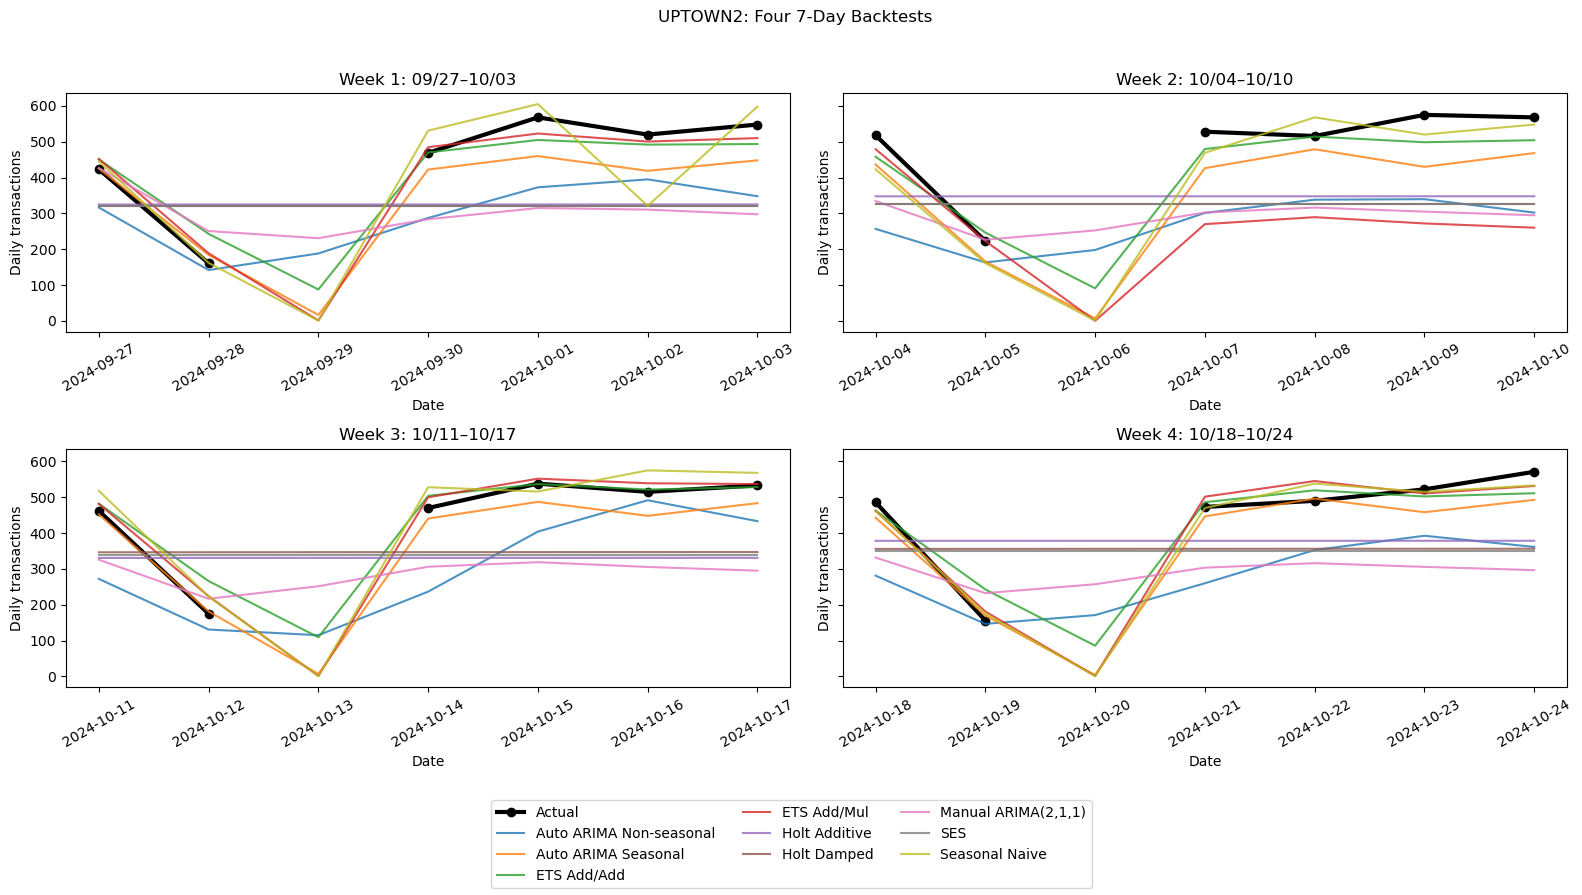

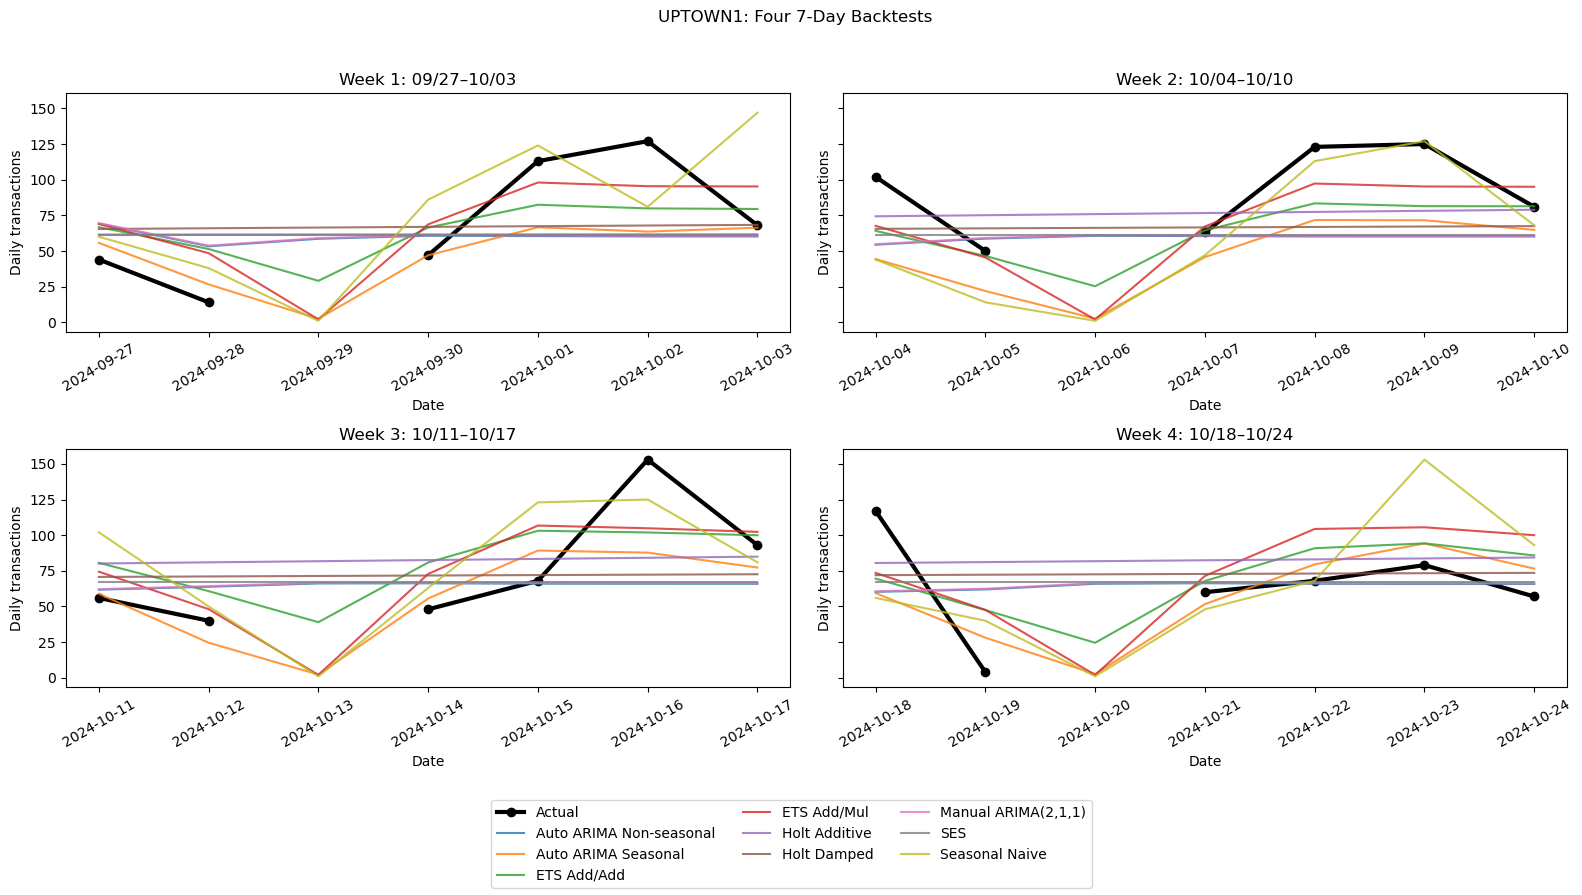

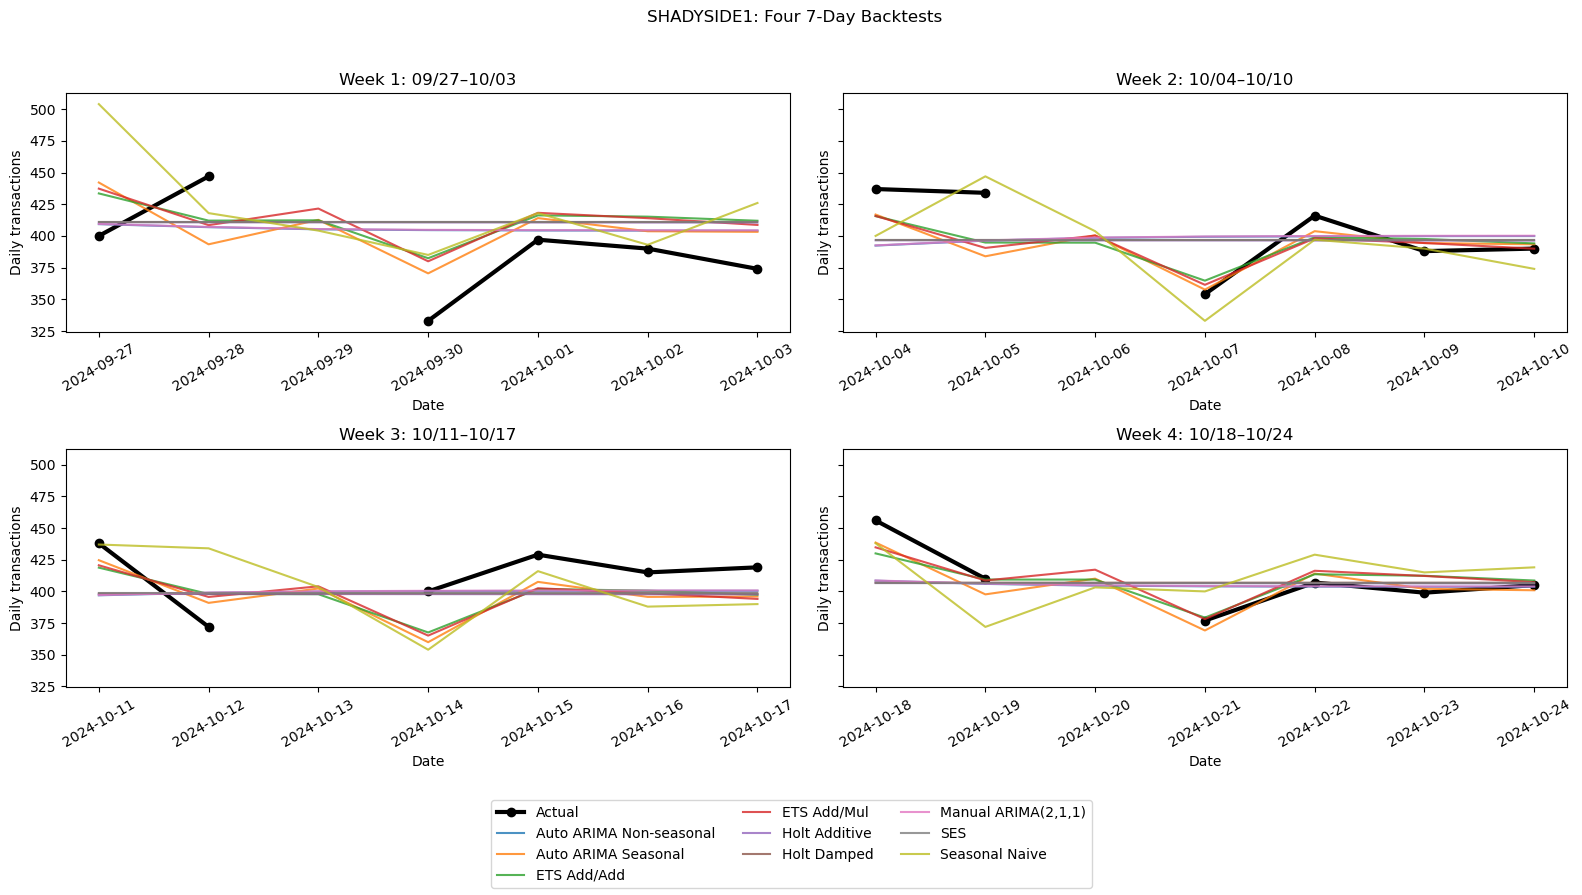

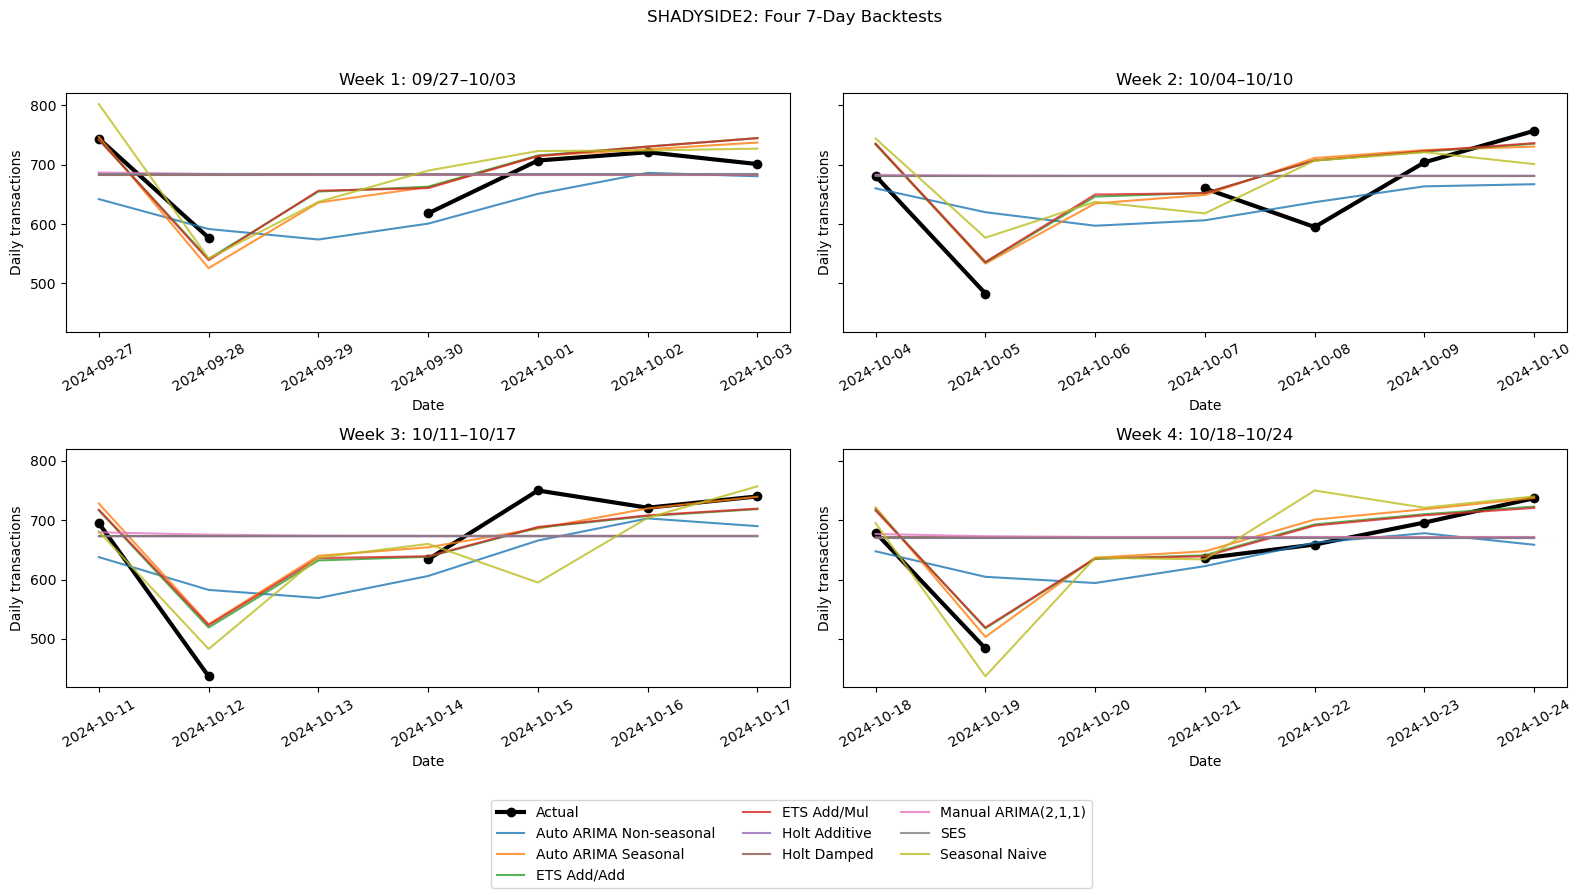

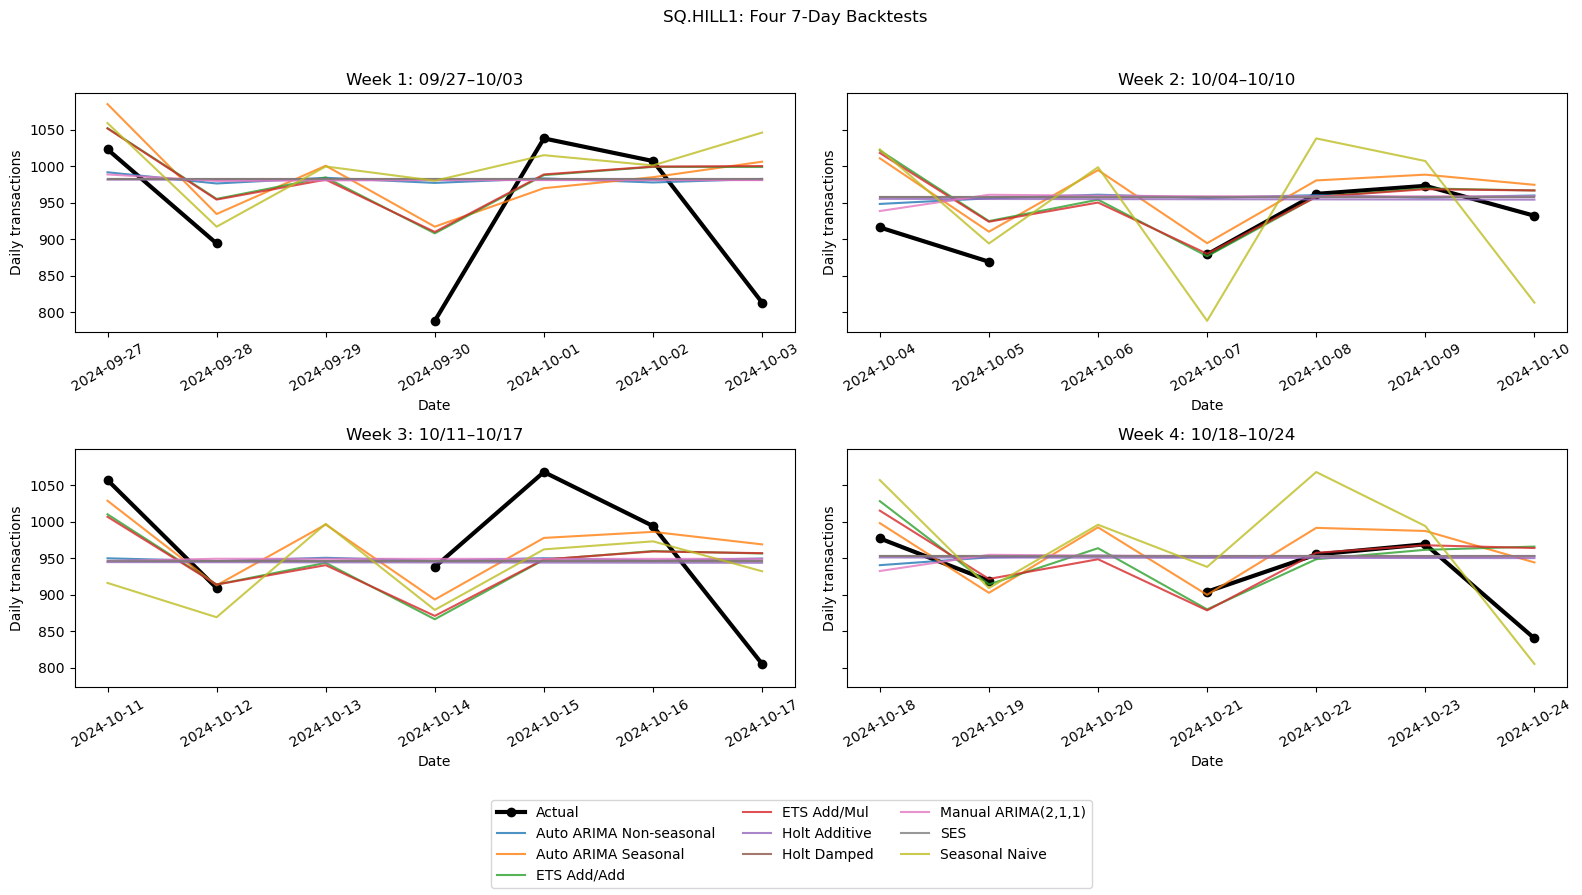

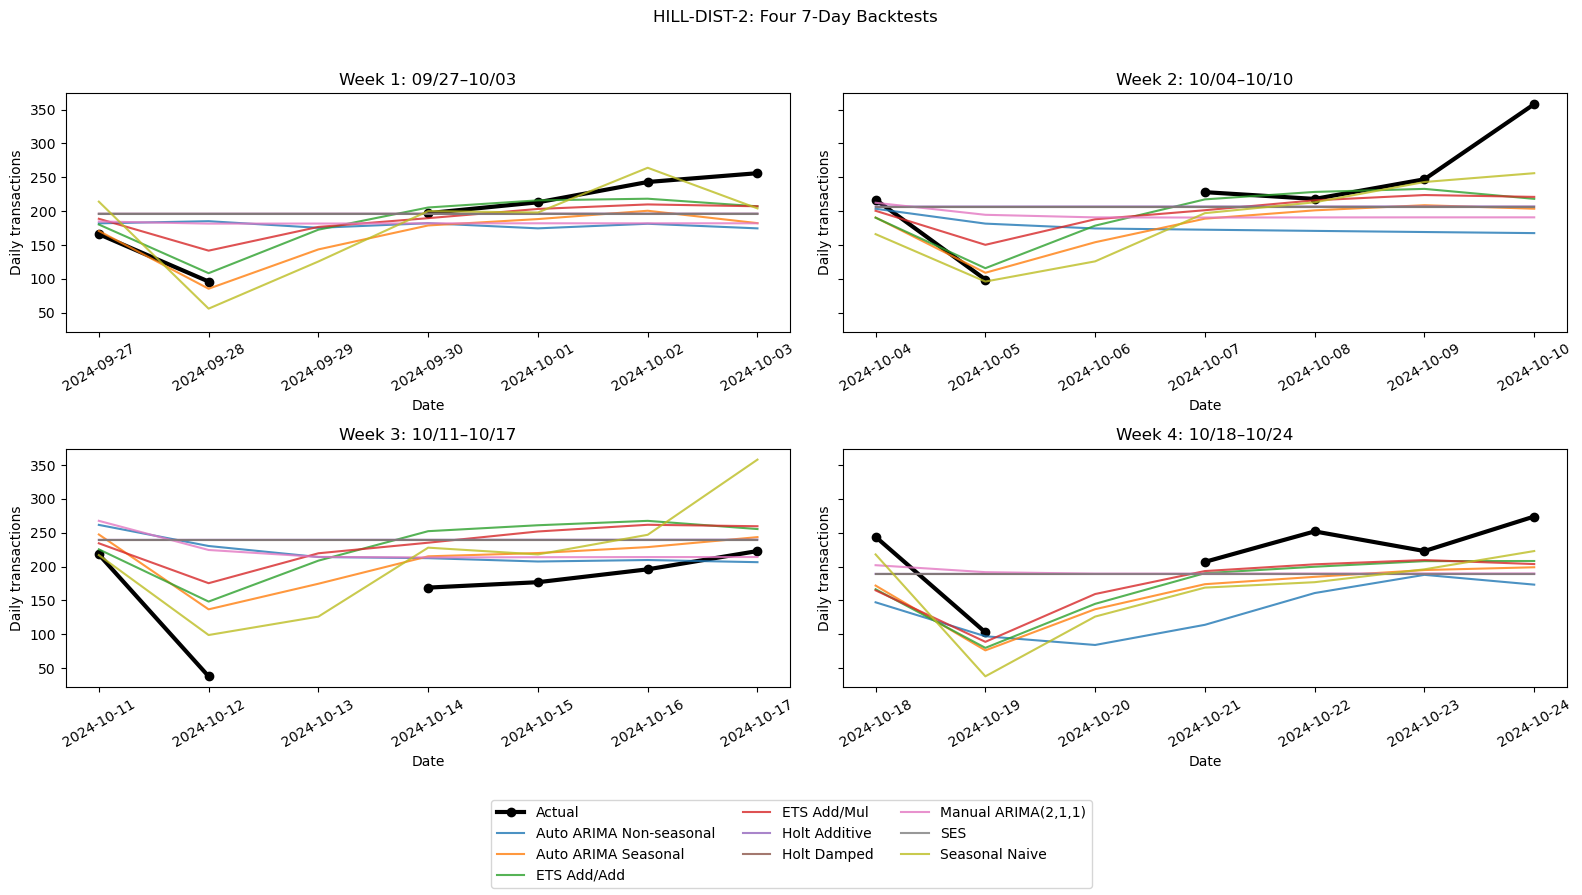

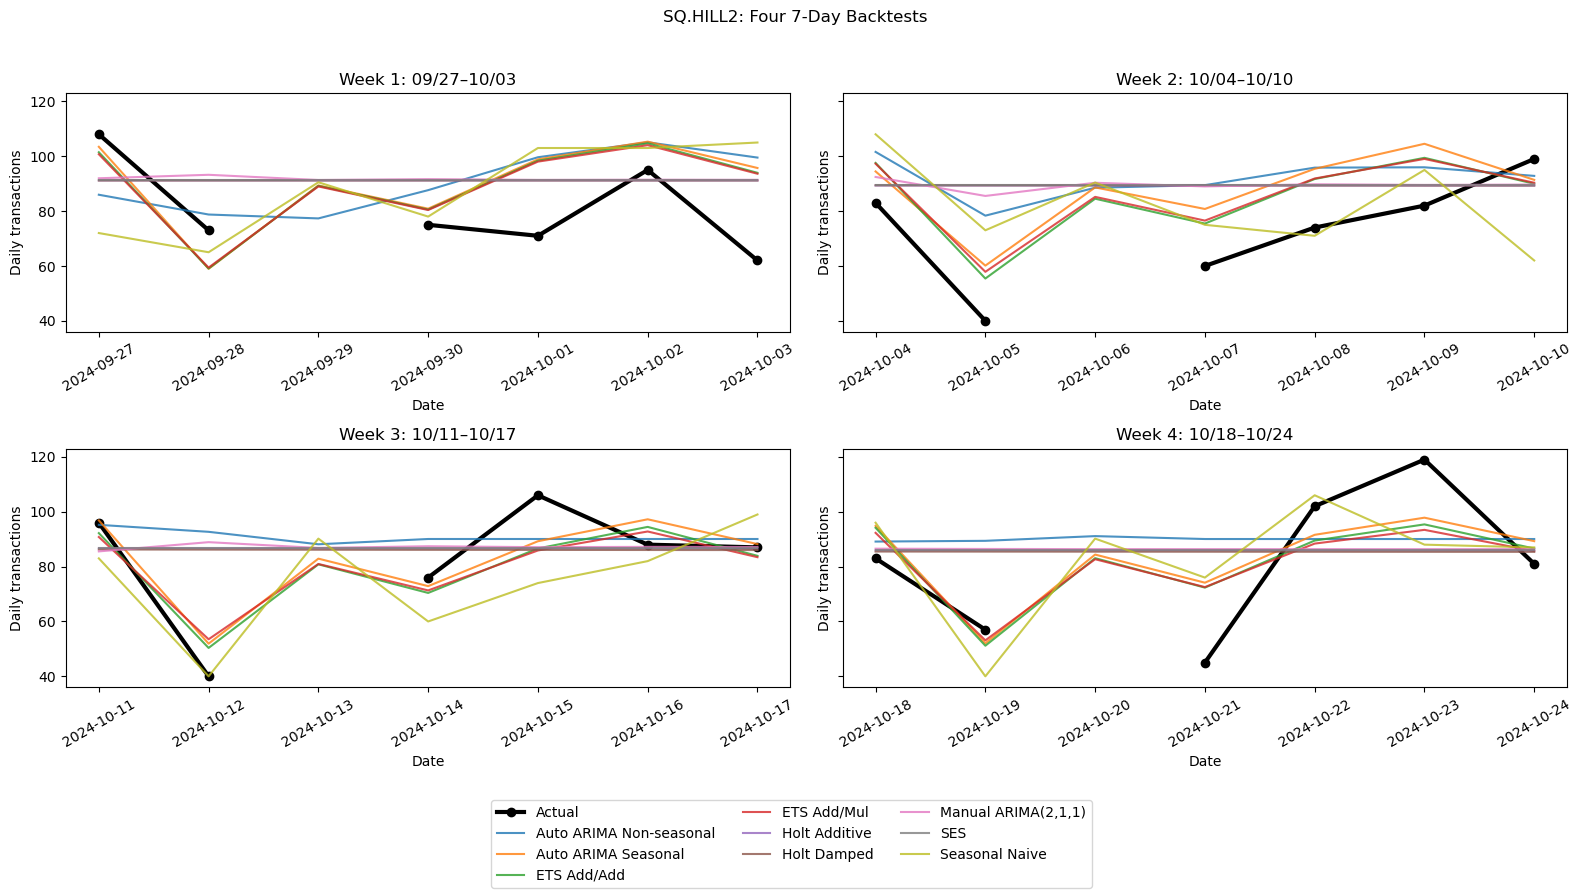

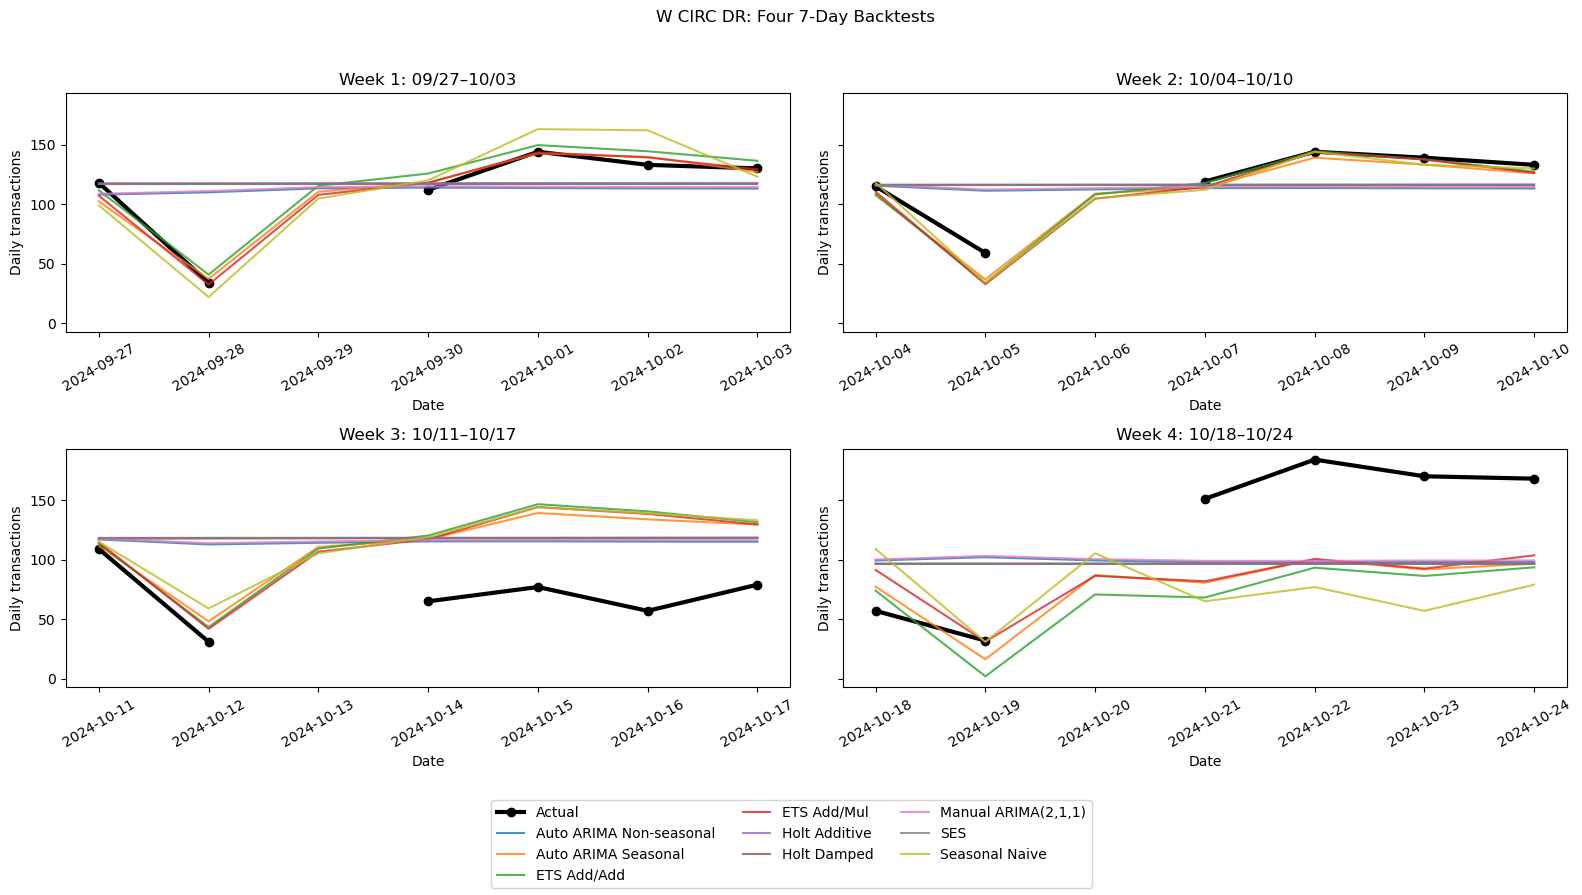

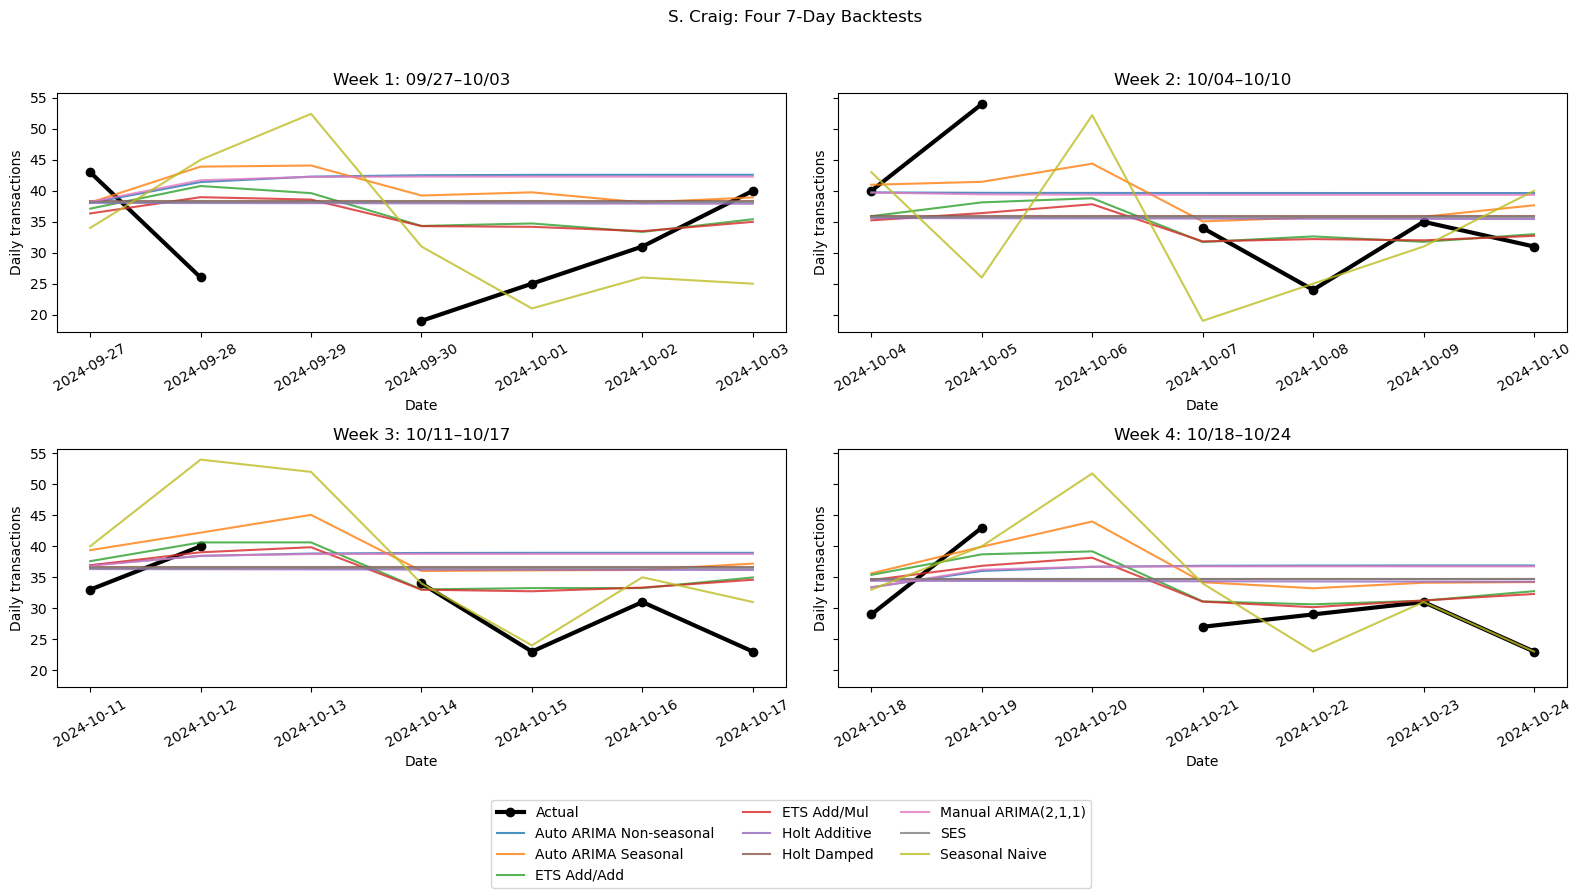

In [ ]:
for plot_zone in model_zones:
    fig, axes = plt.subplots(
        2, 2, figsize=(16, 9), sharey=True
    )

    # collect model with four set
    legend_items = {}

    for ax, period in zip(axes.flat, backtest_periods):
        part = forecast_results_df.loc[
            forecast_results_df['Zone'].eq(plot_zone)
            & forecast_results_df['Backtest Period'].eq(period)
        ]

        actual = (
            part[['Date', 'Actual']]
            .drop_duplicates()
            .sort_values('Date')
        )

        ax.plot(
            actual['Date'], actual['Actual'],
            color='black', linewidth=3,
            marker='o', label='Actual'
        )

        for name, values in part.groupby('Model'):
            values = values.sort_values('Date')
            ax.plot(
                values['Date'], values['Forecast'],
                label=name, alpha=0.8
            )

        ax.set(
            title=period,
            xlabel='Date',
            ylabel='Daily transactions'
        )
        ax.tick_params(axis='x', rotation=30)

        handles, labels = ax.get_legend_handles_labels()
        legend_items.update(zip(labels, handles))

    fig.legend(
        list(legend_items.values()),
        list(legend_items.keys()),
        loc='lower center',
        ncol=3
    )
    fig.suptitle(f'{plot_zone}: Four 7-Day Backtests')
    fig.tight_layout(rect=[0, 0.12, 1, 0.96])
    plt.show()

### 6.7 Weather Feature Backtest

This is a fast feature-screening experiment that reuses the four 7-day validation windows and leaves the final 7-day holdout untouched. A ridge autoregression uses weekday, annual calendar terms, and the transaction count from the same weekday one week earlier; the weather variants add rain, snow, temperature, or all three. Each variant uses the same model form and is scored on the same observed validation targets.

To run this experiment without running the slower 6.4–6.6 model comparison or the historical-window experiment in 6.8, first run the data preparation cells through Section 4, then run 6.1 and 6.3, and execute only the 6.7 code cell. It uses `backtest_periods`, `series_by_zone`, `prepare_train`, and `calculate_metrics` from those earlier cells.

**Interpretation limit:** the joined archive contains observed weather on the validation dates. This experiment tests whether weather is associated with forecast improvement when those values are known; it is an optimistic, retrospective screen, not a deployable forecast using weather known at issue time. A live 7-day product would need weather forecasts available on the forecast date. If weather helps here, the next step is to test it in an exogenous time-series model such as SARIMAX using forecast-available weather inputs.


In [ ]:
# Fast weather feature screen using the full archive and the fixed 3-year training window.
weather_feature_specs = {
    "No weather": [],
    "Rain only": ["rain_mm"],
    "Snow only": ["snow_cm"],
    "Temperature only": ["temp_mean"],
    "All weather": ["rain_mm", "snow_cm", "temp_mean"],
}
weather_value_cols = ["rain_mm", "snow_cm", "temp_mean"]

# Use the full multi-year archive downloaded in Section 2.9.
weather_panel = zone_weather.copy()
weather_panel["date"] = pd.to_datetime(weather_panel["date"])
weather_panel = weather_panel.set_index(["zone", "date"]).sort_index()
if weather_panel.index.has_duplicates:
    raise ValueError("Weather panel has duplicate zone/date rows.")


def make_weather_design(date_index, lag_7_values, weather_for_dates, weather_features):
    date_index = pd.DatetimeIndex(date_index)
    design = pd.DataFrame({
        "lag_7": np.asarray(lag_7_values, dtype=float),
        "annual_sin": np.sin(2 * np.pi * (date_index.dayofyear - 1) / 365.25),
        "annual_cos": np.cos(2 * np.pi * (date_index.dayofyear - 1) / 365.25),
    }, index=date_index)

    weekday = pd.Series(date_index.dayofweek, index=date_index)
    weekday_dummies = pd.get_dummies(weekday, prefix="dow", dtype=float)
    weekday_dummies = weekday_dummies.reindex(
        columns=[f"dow_{day}" for day in range(1, 7)], fill_value=0.0
    )
    design = pd.concat([design, weekday_dummies], axis=1)

    if weather_features:
        weather_part = weather_for_dates.reindex(date_index)[weather_features].copy()
        for col in weather_features:
            weather_part[col] = pd.to_numeric(weather_part[col], errors="coerce")
        design = pd.concat([design, weather_part], axis=1)
    return design.replace([np.inf, -np.inf], np.nan)


def ridge_forecast(train_x, train_y, future_x, alpha=1.0):
    # Standardize predictors using the training window only; do not penalize the intercept.
    train_x = train_x.astype(float).copy()
    future_x = future_x.reindex(columns=train_x.columns).astype(float).copy()
    fill_values = train_x.median().fillna(0.0)
    train_x = train_x.fillna(fill_values)
    future_x = future_x.fillna(fill_values)
    means = train_x.mean()
    scales = train_x.std(ddof=0).replace(0, 1.0).fillna(1.0)
    x_train = ((train_x - means) / scales).to_numpy()
    x_future = ((future_x - means) / scales).to_numpy()
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_future = np.column_stack([np.ones(len(x_future)), x_future])
    penalty = np.eye(x_train.shape[1])
    penalty[0, 0] = 0.0
    coefficients = np.linalg.solve(
        x_train.T @ x_train + alpha * penalty,
        x_train.T @ np.asarray(train_y, dtype=float)
    )
    return np.maximum(x_future @ coefficients, 0.0)


weather_forecasts = []
weather_fit_status = []
for zone in model_zones:
    print(f"Weather feature backtest: {zone}", flush=True)
    zone_panel = weather_panel.xs(zone, level="zone")
    y = series_by_zone[zone]

    for period, (test_start, test_end) in backtest_periods.items():
        test_index = pd.date_range(test_start, test_end, freq="D")
        raw_train = fixed_window_train(y, test_start)
        prepared_train = prepare_train(raw_train)
        train_lag_7 = prepared_train.shift(7)
        test_lag_7 = prepared_train.reindex(test_index - pd.Timedelta(days=7)).to_numpy()
        actual = y.reindex(test_index)

        train_actual = raw_train.rename("target")
        for variant, features in weather_feature_specs.items():
            train_design = make_weather_design(
                raw_train.index, train_lag_7.to_numpy(), zone_panel, features
            )
            training_frame = train_design.join(train_actual)
            training_frame = training_frame.loc[
                training_frame["target"].notna() & training_frame["lag_7"].notna()
            ]
            future_design = make_weather_design(
                test_index, test_lag_7, zone_panel, features
            )

            try:
                if len(training_frame) < 30:
                    raise ValueError("Fewer than 30 observed training rows with a usable weekly lag.")
                prediction = ridge_forecast(
                    training_frame.drop(columns="target"),
                    training_frame["target"],
                    future_design,
                    alpha=1.0
                )
                status = "ok"
                weather_forecasts.append(pd.DataFrame({
                    "Zone": zone,
                    "Weather Variant": variant,
                    "Backtest Period": period,
                    "Date": test_index,
                    "Actual": actual.to_numpy(),
                    "Forecast": prediction
                }))
            except Exception as exc:
                status = f"failed: {type(exc).__name__}: {exc}"

            weather_fit_status.append({
                "Zone": zone,
                "Weather Variant": variant,
                "Backtest Period": period,
                "Training Rows": len(training_frame),
                "Status": status
            })

weather_fit_status_df = pd.DataFrame(weather_fit_status)
weather_forecasts_df = pd.concat(weather_forecasts, ignore_index=True) if weather_forecasts else pd.DataFrame()

weather_metric_rows = []
for (zone, variant), fit_part in weather_fit_status_df.groupby(["Zone", "Weather Variant"]):
    forecast_part = weather_forecasts_df.loc[
        weather_forecasts_df["Zone"].eq(zone)
        & weather_forecasts_df["Weather Variant"].eq(variant)
    ] if not weather_forecasts_df.empty else pd.DataFrame()

    if forecast_part.empty:
        metrics = {"RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "N scored": 0, "N MAPE": 0}
        wape = np.nan
    else:
        metrics = calculate_metrics(forecast_part["Actual"], forecast_part["Forecast"])
        valid = np.isfinite(forecast_part["Actual"]) & np.isfinite(forecast_part["Forecast"])
        actual_valid = forecast_part.loc[valid, "Actual"].to_numpy(dtype=float)
        forecast_valid = forecast_part.loc[valid, "Forecast"].to_numpy(dtype=float)
        denominator = np.abs(actual_valid).sum()
        wape = 100 * np.abs(actual_valid - forecast_valid).sum() / denominator if denominator > 0 else np.nan

    zone_series = series_by_zone[zone]
    expected_scored = sum(
        zone_series.reindex(pd.date_range(a, b, freq="D")).notna().sum()
        for a, b in backtest_periods.values()
    )
    successful_windows = fit_part.loc[fit_part["Status"].eq("ok"), "Backtest Period"].nunique()
    weather_metric_rows.append({
        "Zone": zone,
        "Weather Variant": variant,
        **metrics,
        "WAPE": wape,
        "Successful Windows": successful_windows,
        "Eligible": successful_windows == len(backtest_periods) and metrics["N scored"] == expected_scored
    })

weather_results_df = pd.DataFrame(weather_metric_rows)
no_weather_rmse = (
    weather_results_df.loc[weather_results_df["Weather Variant"].eq("No weather")]
    .set_index("Zone")["RMSE"]
)
def rmse_change_vs_baseline(row):
    baseline_rmse = no_weather_rmse.get(row["Zone"], np.nan)
    if pd.notna(row["RMSE"]) and pd.notna(baseline_rmse) and baseline_rmse != 0:
        return 100 * (row["RMSE"] - baseline_rmse) / baseline_rmse
    return np.nan


weather_results_df["RMSE change vs no weather (%)"] = weather_results_df.apply(
    rmse_change_vs_baseline, axis=1
)

print("Pooled results across the same four validation weeks; negative RMSE change means improvement vs the no-weather model:")
display(
    weather_results_df.sort_values(["Zone", "RMSE"])
    .style.format({
        "RMSE": "{:.2f}", "MAE": "{:.2f}", "MAPE": "{:.1f}%",
        "WAPE": "{:.1f}%", "RMSE change vs no weather (%)": "{:+.1f}%"
    }, na_rep="—")
)

eligible_weather_results = weather_results_df.loc[
    weather_results_df["Eligible"] & weather_results_df["Weather Variant"].ne("No weather")
].copy()
best_weather_by_zone_df = (
    eligible_weather_results
    .sort_values(["Zone", "RMSE", "MAE", "Weather Variant"])
    .groupby("Zone", sort=False)
    .head(1)
    .reset_index(drop=True)
)
print("Lowest-RMSE eligible weather variant by zone (screening result; compare with No weather above):")
display(
    best_weather_by_zone_df[
        ["Zone", "Weather Variant", "RMSE", "MAE", "MAPE", "WAPE", "RMSE change vs no weather (%)"]
    ].style.format({
        "RMSE": "{:.2f}", "MAE": "{:.2f}", "MAPE": "{:.1f}%",
        "WAPE": "{:.1f}%", "RMSE change vs no weather (%)": "{:+.1f}%"
    }, na_rep="—")
)
print("Weather fits needing review:")
display(weather_fit_status_df.loc[weather_fit_status_df["Status"].ne("ok")])


Weather feature backtest: UPTOWN2
Weather feature backtest: UPTOWN1
Weather feature backtest: SHADYSIDE1
Weather feature backtest: SHADYSIDE2
Weather feature backtest: SQ.HILL1
Weather feature backtest: HILL-DIST-2
Weather feature backtest: SQ.HILL2
Weather feature backtest: W CIRC DR
Weather feature backtest: S. Craig
Pooled results across the same four validation weeks; negative RMSE change means improvement vs the no-weather model:


,Zone,Weather Variant,RMSE,MAE,MAPE,N scored,N MAPE,WAPE,Successful Windows,Eligible,RMSE change vs no weather (%)
2,HILL-DIST-2,Rain only,60.04,47.69,26.4%,24,24,23.5%,4,True,-0.2%
3,HILL-DIST-2,Snow only,60.16,47.71,26.4%,24,24,23.6%,4,True,-0.0%
1,HILL-DIST-2,No weather,60.17,47.77,26.4%,24,24,23.6%,4,True,+0.0%
0,HILL-DIST-2,All weather,60.33,47.55,26.5%,24,24,23.5%,4,True,+0.3%
4,HILL-DIST-2,Temperature only,60.66,47.74,26.4%,24,24,23.6%,4,True,+0.8%
6,S. Craig,No weather,15.04,13.73,49.0%,24,24,42.9%,4,True,+0.0%
7,S. Craig,Rain only,15.06,13.76,49.1%,24,24,43.0%,4,True,+0.1%
9,S. Craig,Temperature only,15.07,13.75,49.1%,24,24,43.0%,4,True,+0.2%
8,S. Craig,Snow only,15.15,13.83,49.4%,24,24,43.2%,4,True,+0.7%
5,S. Craig,All weather,15.20,13.89,49.6%,24,24,43.4%,4,True,+1.0%


Lowest-RMSE eligible weather variant by zone (screening result; compare with No weather above):


,Zone,Weather Variant,RMSE,MAE,MAPE,WAPE,RMSE change vs no weather (%)
0,HILL-DIST-2,Rain only,60.04,47.69,26.4%,23.5%,-0.2%
1,S. Craig,Rain only,15.06,13.76,49.1%,43.0%,+0.1%
2,SHADYSIDE1,Snow only,23.31,19.15,4.8%,4.7%,-1.9%
3,SHADYSIDE2,Snow only,43.59,34.39,5.4%,5.2%,+0.0%
4,SQ.HILL1,Rain only,83.30,61.97,7.0%,6.6%,+0.2%
5,SQ.HILL2,Rain only,16.61,14.31,20.6%,18.1%,-0.0%
6,UPTOWN1,Rain only,43.06,32.53,66.2%,43.4%,-1.3%
7,UPTOWN2,Rain only,87.29,77.37,16.0%,16.9%,-1.7%
8,W CIRC DR,All weather,45.39,32.73,37.1%,30.7%,-2.3%


Weather fits needing review:


,Zone,Weather Variant,Backtest Period,Training Rows,Status


## 6.8 Multi-year Winter Snow and Rain Backtest

This adds non-overlapping 7-day validation windows for complete December–February weeks across every winter with enough prior transaction history for a fixed 3-year training window. It compares the same ridge autoregression with no weather, snow only, rain only, snow plus rain, and all three weather variables. Results are pooled separately for snowy and no-snow validation weeks. The existing four fall windows and the final 7-day holdout are unchanged and are not used here.

To run it, first rerun Section 2.9 to download the extended archive. Then run Sections 6.1 and 6.3, run the 6.7 code cell to define the weather-model helpers, and execute only the 6.8 code cell. Sections 6.4–6.6 and 6.9–6.10 are not required for this experiment.

The weather archive must be downloaded by the notebook from Open-Meteo. This is a retrospective feature test with observed future weather; it estimates whether weather could help when known, not the final deployment accuracy from weather forecasts. Model inputs and evaluation are limited by available historical days and missing daily transaction targets.


In [ ]:
# Rebuild complete daily historical targets, then evaluate the same 3-year Ridge variants on winter weeks.
winter_cutoff = pd.Timestamp(end_date) - pd.Timedelta(days=1)
winter_source = transactions.loc[
    transactions["zone"].isin(model_zones),
    ["_id", "zone", "start"] + count_cols
].copy()
winter_source = winter_source.loc[
    winter_source["start"].dt.normalize().le(winter_cutoff)
].copy()

winter_content_cols = [c for c in winter_source.columns if c != "_id"]
winter_dupes = winter_source.duplicated(subset=winter_content_cols)
print("Historical duplicate content rows removed:", int(winter_dupes.sum()))
winter_source = winter_source.loc[~winter_dupes].copy()
winter_conflicts = winter_source.duplicated(["zone", "start"], keep=False)
if winter_conflicts.any():
    display(winter_source.loc[winter_conflicts].sort_values(["zone", "start"]).head(20))
    raise ValueError("Historical data has conflicting zone/time records; review before the winter backtest.")

for col in count_cols:
    winter_source[col] = pd.to_numeric(winter_source[col], errors="coerce")
    winter_source.loc[~np.isfinite(winter_source[col]), col] = np.nan
    invalid = (
        (winter_source[col] < 0)
        | (winter_source[col].notna() & winter_source[col].mod(1).ne(0))
    )
    print(col, "invalid historical counts set to NaN:", int(invalid.sum()))
    winter_source.loc[invalid, col] = np.nan

winter_source["date"] = winter_source["start"].dt.normalize()
winter_groups = winter_source.groupby(["zone", "date"])
winter_daily = winter_groups[count_cols].sum(min_count=1)
winter_partial_days = winter_groups[count_cols].count().lt(winter_groups.size(), axis=0)
winter_daily = winter_daily.mask(winter_partial_days)
winter_daily["total_transactions"] = winter_daily[count_cols].sum(axis=1, min_count=2)

winter_history_start = winter_source["date"].min()
winter_calendar = pd.date_range(winter_history_start, winter_cutoff, freq="D")
winter_targets = (
    winter_daily["total_transactions"]
    .unstack("zone")
    .reindex(index=winter_calendar, columns=model_zones)
)
print("Transaction target history:", winter_calendar.min().date(), "to", winter_calendar.max().date())
display(winter_targets.notna().sum().rename("usable_historical_days").to_frame())

# Confirm that Section 2.9 downloaded the full weather archive.
long_weather = zone_weather.copy()
long_weather["date"] = pd.to_datetime(long_weather["date"])
long_weather_panel = long_weather.set_index(["zone", "date"]).sort_index()
if long_weather_panel.index.has_duplicates:
    raise ValueError("Multi-year weather archive has duplicate zone/date rows.")
weather_first_date = long_weather["date"].min()
weather_last_date = long_weather["date"].max()
print("Historical weather archive:", weather_first_date.date(), "to", weather_last_date.date())

winter_lookback_days = 1095
winter_periods = []
first_winter_year = max(winter_calendar.min().year, weather_first_date.year) + 3
last_winter_year = min(winter_cutoff.year - 1, weather_last_date.year - 1)
for winter_start_year in range(first_winter_year, last_winter_year + 1):
    winter_start = pd.Timestamp(winter_start_year, 12, 1)
    winter_end = pd.Timestamp(winter_start_year + 1, 3, 1) - pd.Timedelta(days=1)
    cursor = winter_start
    week_number = 1
    while cursor + pd.Timedelta(days=6) <= winter_end:
        test_end = cursor + pd.Timedelta(days=6)
        train_start = cursor - pd.Timedelta(days=winter_lookback_days)
        if train_start >= winter_calendar.min() and cursor >= weather_first_date and test_end <= weather_last_date:
            winter_periods.append({
                "Winter": f"{winter_start_year}-{str(winter_start_year + 1)[-2:]}",
                "Period": f"Winter {winter_start_year}-{str(winter_start_year + 1)[-2:]} / Week {week_number:02d}",
                "Start": cursor,
                "End": test_end
            })
        cursor += pd.Timedelta(days=7)
        week_number += 1

if not winter_periods:
    raise ValueError("No complete winter validation weeks found with a full 3-year training history.")
winter_periods_df = pd.DataFrame(winter_periods)
print("Winter seasons:", winter_periods_df["Winter"].nunique(), "; complete 7-day windows:", len(winter_periods))
display(winter_periods_df.groupby("Winter").agg(
    validation_weeks=("Period", "size"), first_week=("Start", "min"), last_week=("End", "max")
))

winter_weather_specs = {
    "No weather": [],
    "Snow only": ["snow_cm"],
    "Rain only": ["rain_mm"],
    "Snow + rain": ["snow_cm", "rain_mm"],
    "All weather": ["snow_cm", "rain_mm", "temp_mean"],
}
winter_weather_forecasts = []
winter_weather_status = []
for zone in model_zones:
    print(f"Winter weather backtest: {zone}", flush=True)
    zone_weather_history = long_weather_panel.xs(zone, level="zone")
    zone_targets = winter_targets[zone].astype(float)
    for period_info in winter_periods:
        test_start, test_end = period_info["Start"], period_info["End"]
        test_index = pd.date_range(test_start, test_end, freq="D")
        test_weather = zone_weather_history.reindex(test_index)
        if test_weather[["snow_cm", "rain_mm", "temp_mean"]].isna().any().any():
            continue
        snow_days = int(pd.to_numeric(test_weather["snow_cm"], errors="coerce").fillna(0).gt(0).sum())
        snow_condition = "Snowy week" if snow_days > 0 else "No-snow week"
        actual = zone_targets.reindex(test_index)

        train_start = test_start - pd.Timedelta(days=winter_lookback_days)
        raw_train = zone_targets.loc[
            (zone_targets.index >= train_start) & (zone_targets.index < test_start)
        ]
        prepared_train = prepare_train(raw_train)
        train_lag_7 = prepared_train.shift(7)
        test_lag_7 = prepared_train.reindex(test_index - pd.Timedelta(days=7)).to_numpy()
        train_actual = raw_train.rename("target")

        for variant, features in winter_weather_specs.items():
            train_design = make_weather_design(
                raw_train.index, train_lag_7.to_numpy(), zone_weather_history, features
            )
            training_frame = train_design.join(train_actual)
            training_frame = training_frame.loc[
                training_frame["target"].notna() & training_frame["lag_7"].notna()
            ]
            future_design = make_weather_design(
                test_index, test_lag_7, zone_weather_history, features
            )
            try:
                if len(training_frame) < 30:
                    raise ValueError("Fewer than 30 observed training rows with a usable weekly lag.")
                prediction = ridge_forecast(
                    training_frame.drop(columns="target"), training_frame["target"],
                    future_design, alpha=1.0
                )
                status = "ok"
                winter_weather_forecasts.append(pd.DataFrame({
                    "Zone": zone, "Winter": period_info["Winter"],
                    "Period": period_info["Period"], "Snow Condition": snow_condition,
                    "Snow Days": snow_days, "Weather Variant": variant,
                    "Date": test_index, "Actual": actual.to_numpy(), "Forecast": prediction
                }))
            except Exception as exc:
                status = f"failed: {type(exc).__name__}: {exc}"
            winter_weather_status.append({
                "Zone": zone, "Winter": period_info["Winter"], "Period": period_info["Period"],
                "Snow Condition": snow_condition, "Snow Days": snow_days,
                "Weather Variant": variant, "Training Rows": len(training_frame), "Status": status
            })

winter_weather_status_df = pd.DataFrame(winter_weather_status)
winter_weather_forecasts_df = (
    pd.concat(winter_weather_forecasts, ignore_index=True)
    if winter_weather_forecasts else pd.DataFrame()
)
winter_metric_rows = []
for (zone, condition, variant), fit_part in winter_weather_status_df.groupby(
    ["Zone", "Snow Condition", "Weather Variant"]
):
    forecast_part = winter_weather_forecasts_df.loc[
        winter_weather_forecasts_df["Zone"].eq(zone)
        & winter_weather_forecasts_df["Snow Condition"].eq(condition)
        & winter_weather_forecasts_df["Weather Variant"].eq(variant)
    ] if not winter_weather_forecasts_df.empty else pd.DataFrame()
    if forecast_part.empty:
        metrics = {"RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "N scored": 0, "N MAPE": 0}
        wape = np.nan
    else:
        metrics = calculate_metrics(forecast_part["Actual"], forecast_part["Forecast"])
        valid = np.isfinite(forecast_part["Actual"]) & np.isfinite(forecast_part["Forecast"])
        actual_valid = forecast_part.loc[valid, "Actual"].to_numpy(dtype=float)
        forecast_valid = forecast_part.loc[valid, "Forecast"].to_numpy(dtype=float)
        denominator = np.abs(actual_valid).sum()
        wape = 100 * np.abs(actual_valid - forecast_valid).sum() / denominator if denominator > 0 else np.nan
    successful_windows = fit_part.loc[fit_part["Status"].eq("ok"), "Period"].nunique()
    expected_scored = forecast_part["Actual"].notna().sum() if not forecast_part.empty else 0
    winter_metric_rows.append({
        "Zone": zone, "Snow Condition": condition, "Weather Variant": variant,
        "Winters": fit_part["Winter"].nunique(), "Validation Weeks": fit_part["Period"].nunique(),
        "Successful Weeks": successful_windows,
        "Eligible": successful_windows == fit_part["Period"].nunique() and metrics["N scored"] == expected_scored,
        **metrics, "WAPE": wape
    })
winter_weather_results_df = pd.DataFrame(winter_metric_rows)
winter_baseline_rmse = (
    winter_weather_results_df.loc[winter_weather_results_df["Weather Variant"].eq("No weather")]
    .set_index(["Zone", "Snow Condition"])["RMSE"]
)
def winter_rmse_change(row):
    baseline = winter_baseline_rmse.get((row["Zone"], row["Snow Condition"]), np.nan)
    if pd.notna(row["RMSE"]) and pd.notna(baseline) and baseline != 0:
        return 100 * (row["RMSE"] - baseline) / baseline
    return np.nan
winter_weather_results_df["RMSE change vs no weather (%)"] = winter_weather_results_df.apply(
    winter_rmse_change, axis=1
)
print("Winter-only results by zone and snow condition; negative RMSE change means improvement:")
display(winter_weather_results_df.sort_values(["Zone", "Snow Condition", "RMSE"]).style.format({
    "RMSE": "{:.2f}", "MAE": "{:.2f}", "MAPE": "{:.1f}%", "WAPE": "{:.1f}%",
    "RMSE change vs no weather (%)": "{:+.1f}%"
}, na_rep="—"))
print("Snow / rain model fits needing review:")
display(winter_weather_status_df.loc[winter_weather_status_df["Status"].ne("ok")])
print("The Oct 25–31, 2024 final holdout was not used in the winter backtest.")


Historical duplicate content rows removed: 0
meter_transactions invalid historical counts set to NaN: 0
mobile_transactions invalid historical counts set to NaN: 0
Transaction target history: 2014-01-02 to 2024-10-31


,usable_historical_days
zone,
UPTOWN2,3292
UPTOWN1,3261
SHADYSIDE1,3254
SHADYSIDE2,3255
SQ.HILL1,3258
HILL-DIST-2,3211
SQ.HILL2,3254
W CIRC DR,2879
S. Craig,3249


Historical weather archive: 2014-01-02 to 2024-10-31
Winter seasons: 7 ; complete 7-day windows: 86


,validation_weeks,first_week,last_week
Winter,,,
2017-18,12,2017-12-01,2018-02-22
2018-19,12,2018-12-01,2019-02-22
2019-20,13,2019-12-01,2020-02-29
2020-21,12,2020-12-01,2021-02-22
2021-22,12,2021-12-01,2022-02-22
2022-23,12,2022-12-01,2023-02-22
2023-24,13,2023-12-01,2024-02-29


Winter weather backtest: UPTOWN2
Winter weather backtest: UPTOWN1
Winter weather backtest: SHADYSIDE1
Winter weather backtest: SHADYSIDE2
Winter weather backtest: SQ.HILL1
Winter weather backtest: HILL-DIST-2
Winter weather backtest: SQ.HILL2
Winter weather backtest: W CIRC DR
Winter weather backtest: S. Craig
Winter-only results by zone and snow condition; negative RMSE change means improvement:


,Zone,Snow Condition,Weather Variant,Winters,Validation Weeks,Successful Weeks,Eligible,RMSE,MAE,MAPE,N scored,N MAPE,WAPE,RMSE change vs no weather (%)
0,HILL-DIST-2,No-snow week,All weather,5,17,17,True,60.55,43.24,329.5%,94,94,35.5%,-0.4%
3,HILL-DIST-2,No-snow week,Snow + rain,5,17,17,True,60.67,43.95,320.4%,94,94,36.1%,-0.2%
2,HILL-DIST-2,No-snow week,Rain only,5,17,17,True,60.74,44.09,317.9%,94,94,36.2%,-0.1%
4,HILL-DIST-2,No-snow week,Snow only,5,17,17,True,60.74,43.96,318.7%,94,94,36.1%,-0.1%
1,HILL-DIST-2,No-snow week,No weather,5,17,17,True,60.81,44.09,316.3%,94,94,36.2%,+0.0%
5,HILL-DIST-2,Snowy week,All weather,7,69,69,True,56.87,42.99,226.1%,390,390,39.1%,-0.8%
8,HILL-DIST-2,Snowy week,Snow + rain,7,69,69,True,57.22,43.24,228.1%,390,390,39.3%,-0.2%
7,HILL-DIST-2,Snowy week,Rain only,7,69,69,True,57.22,43.23,228.4%,390,390,39.3%,-0.2%
9,HILL-DIST-2,Snowy week,Snow only,7,69,69,True,57.30,43.34,228.7%,390,390,39.4%,-0.0%
6,HILL-DIST-2,Snowy week,No weather,7,69,69,True,57.31,43.33,229.0%,390,390,39.4%,+0.0%


Snow / rain model fits needing review:


,Zone,Winter,Period,Snow Condition,Snow Days,Weather Variant,Training Rows,Status


The Oct 25–31, 2024 final holdout was not used in the winter backtest.


## 6.9 Winter-by-Winter Robustness Check for High-Traffic Zones

This follow-up focuses on SHADYSIDE1, SHADYSIDE2, and SQ.HILL1. It compares the no-weather baseline with snow-only, snow-plus-rain, and all-weather Ridge variants on the exact same observed dates, separately for each winter and for snowy versus no-snow weeks. RMSE and MAE are reported along with the paired RMSE change from the no-weather baseline. A negative change means the weather model had lower error.

This is still a retrospective feature check: the weather archive contains observed weather during the forecast week. A deployable 7-day forecast cannot use those future observations. The available archive does not contain historical forecast snapshots, so this notebook cannot measure operational accuracy with weather forecasts; the result must be described as an association / upper-bound feature screen. The three zones also share one Pittsburgh weather grid.

Run this after Section 6.8 in the same kernel. It reuses the already generated forecasts and does not refit models.


In [ ]:
# Winter-by-winter paired comparison for the three high-traffic zones.
focus_zones = ["SHADYSIDE1", "SHADYSIDE2", "SQ.HILL1"]
focus_variants = ["No weather", "Snow only", "Snow + rain", "All weather"]
required_columns = {"Zone", "Winter", "Period", "Snow Condition", "Weather Variant", "Date", "Actual", "Forecast"}
if "winter_weather_forecasts_df" not in globals() or winter_weather_forecasts_df.empty:
    raise NameError("Run Section 6.8 first; its winter_weather_forecasts_df is required.")
missing_columns = required_columns - set(winter_weather_forecasts_df.columns)
if missing_columns:
    raise ValueError(f"Section 6.8 forecast table is missing columns: {sorted(missing_columns)}")

focus_forecasts = winter_weather_forecasts_df.loc[
    winter_weather_forecasts_df["Zone"].isin(focus_zones)
    & winter_weather_forecasts_df["Weather Variant"].isin(focus_variants)
].copy()
focus_forecasts["Date"] = pd.to_datetime(focus_forecasts["Date"])

# Score every variant against the baseline on the exact same valid target dates.
robustness_rows = []
group_cols = ["Zone", "Winter", "Snow Condition"]
for keys, group in focus_forecasts.groupby(group_cols, sort=True):
    zone, winter, snow_condition = keys
    by_variant = {}
    for variant in focus_variants:
        part = group.loc[group["Weather Variant"].eq(variant), ["Period", "Date", "Actual", "Forecast"]]
        by_variant[variant] = part.drop_duplicates(["Period", "Date"]).set_index(["Period", "Date"])

    baseline = by_variant["No weather"]
    for variant in focus_variants:
        candidate = by_variant[variant]
        paired = baseline[["Actual", "Forecast"]].rename(columns={"Forecast": "Baseline forecast"}).join(
            candidate[["Actual", "Forecast"]].rename(columns={"Actual": "Candidate actual", "Forecast": "Candidate forecast"}),
            how="inner"
        )
        valid = (
            np.isfinite(pd.to_numeric(paired["Actual"], errors="coerce"))
            & np.isfinite(pd.to_numeric(paired["Candidate actual"], errors="coerce"))
            & np.isfinite(pd.to_numeric(paired["Baseline forecast"], errors="coerce"))
            & np.isfinite(pd.to_numeric(paired["Candidate forecast"], errors="coerce"))
        )
        paired = paired.loc[valid]
        # Target should match between variants; assert paired scoring is genuinely identical.
        if not np.allclose(paired["Actual"], paired["Candidate actual"], equal_nan=True):
            raise ValueError(f"Actual targets differ across variants for {zone}, {winter}, {snow_condition}.")

        actual = paired["Actual"].to_numpy(dtype=float)
        pred = paired["Candidate forecast"].to_numpy(dtype=float)
        base_pred = paired["Baseline forecast"].to_numpy(dtype=float)
        if len(actual):
            rmse = float(np.sqrt(np.mean((actual - pred) ** 2)))
            mae = float(np.mean(np.abs(actual - pred)))
            denominator = np.abs(actual).sum()
            wape = float(100 * np.abs(actual - pred).sum() / denominator) if denominator > 0 else np.nan
            baseline_rmse = float(np.sqrt(np.mean((actual - base_pred) ** 2)))
            rmse_change = 100 * (rmse - baseline_rmse) / baseline_rmse if baseline_rmse > 0 else np.nan
        else:
            rmse = mae = wape = baseline_rmse = rmse_change = np.nan

        robustness_rows.append({
            "Zone": zone, "Winter": winter, "Snow Condition": snow_condition,
            "Weather Variant": variant, "Paired 7-day windows": paired.index.get_level_values("Period").nunique(),
            "N scored": len(actual), "RMSE": rmse, "MAE": mae, "WAPE": wape,
            "No-weather RMSE (same dates)": baseline_rmse,
            "RMSE change vs no weather (%)": rmse_change
        })

robustness_by_winter_df = pd.DataFrame(robustness_rows)
print("Per-winter paired results for the three focus zones (negative RMSE change = improvement):")
display(
    robustness_by_winter_df.sort_values(["Zone", "Winter", "Snow Condition", "Weather Variant"])
    .style.format({
        "RMSE": "{:.2f}", "MAE": "{:.2f}", "WAPE": "{:.1f}%",
        "No-weather RMSE (same dates)": "{:.2f}",
        "RMSE change vs no weather (%)": "{:+.1f}%"
    }, na_rep="—")
)

# Concise consistency check: among snowy weeks, how many winters improved for each feature set?
snowy_summary = robustness_by_winter_df.loc[
    robustness_by_winter_df["Snow Condition"].eq("Snowy week")
    & robustness_by_winter_df["Weather Variant"].ne("No weather")
].groupby(["Zone", "Weather Variant"]).agg(
    winters_scored=("Winter", "nunique"),
    winters_improved=("RMSE change vs no weather (%)", lambda x: int((x < 0).sum())),
    median_rmse_change_pct=("RMSE change vs no weather (%)", "median"),
    mean_rmse_change_pct=("RMSE change vs no weather (%)", "mean")
).reset_index()
print("Consistency across snowy winters (paired, per-winter changes):")
display(snowy_summary.style.format({
    "median_rmse_change_pct": "{:+.1f}%", "mean_rmse_change_pct": "{:+.1f}%"
}))


Per-winter paired results for the three focus zones (negative RMSE change = improvement):


,Zone,Winter,Snow Condition,Weather Variant,Paired 7-day windows,N scored,RMSE,MAE,WAPE,No-weather RMSE (same dates),RMSE change vs no weather (%)
3,SHADYSIDE1,2017-18,Snowy week,All weather,12,70,85.93,46.31,9.1%,94.79,-9.4%
0,SHADYSIDE1,2017-18,Snowy week,No weather,12,70,94.79,53.61,10.6%,94.79,+0.0%
2,SHADYSIDE1,2017-18,Snowy week,Snow + rain,12,70,89.93,49.68,9.8%,94.79,-5.1%
1,SHADYSIDE1,2017-18,Snowy week,Snow only,12,70,89.86,49.86,9.8%,94.79,-5.2%
7,SHADYSIDE1,2018-19,No-snow week,All weather,3,18,126.55,54.85,10.9%,121.33,+4.3%
4,SHADYSIDE1,2018-19,No-snow week,No weather,3,18,121.33,53.20,10.5%,121.33,+0.0%
6,SHADYSIDE1,2018-19,No-snow week,Snow + rain,3,18,122.61,50.42,10.0%,121.33,+1.1%
5,SHADYSIDE1,2018-19,No-snow week,Snow only,3,18,123.11,53.17,10.5%,121.33,+1.5%
11,SHADYSIDE1,2018-19,Snowy week,All weather,9,50,69.63,51.44,10.3%,79.20,-12.1%
8,SHADYSIDE1,2018-19,Snowy week,No weather,9,50,79.20,58.48,11.7%,79.20,+0.0%


Consistency across snowy winters (paired, per-winter changes):


,Zone,Weather Variant,winters_scored,winters_improved,median_rmse_change_pct,mean_rmse_change_pct
0,SHADYSIDE1,All weather,7,7,-9.4%,-8.3%
1,SHADYSIDE1,Snow + rain,7,7,-8.2%,-7.6%
2,SHADYSIDE1,Snow only,7,7,-7.7%,-7.6%
3,SHADYSIDE2,All weather,7,7,-9.6%,-10.2%
4,SHADYSIDE2,Snow + rain,7,7,-8.7%,-7.8%
5,SHADYSIDE2,Snow only,7,7,-7.9%,-7.9%
6,SQ.HILL1,All weather,7,7,-12.6%,-11.9%
7,SQ.HILL1,Snow + rain,7,7,-10.1%,-11.1%
8,SQ.HILL1,Snow only,7,7,-10.3%,-11.0%


### 6.10 Forecasting Methodology and Evaluation Protocol

The forecasting analysis combines historical-window sensitivity tests, zone-level model comparison, error diagnostics, retrospective weather experiments, and a seven-day demand forecast. The target is daily paid parking transactions, not occupied parking spaces.

**Training-data coverage.** WPRDC reports missing mobile-payment records between April/May 2021 and October 2023 ([data-provider advisory](https://data.wprdc.org/dataset/parking-transactions)). Recent, two-year, and three-year training histories are compared on identical validation dates. The longer combined-channel histories are treated as sensitivity analyses because mobile undercoverage can distort the measured target. Final forecasts use the recent window, with a nominal maximum of 365 days and a start date no earlier than **2023-11-01**. Missing calendar targets are imputed from training data only; missing validation and holdout actuals remain unknown. Imputation does not repair source-level mobile undercoverage.

**Candidate models and selection.** Candidates include Seasonal Naive, additive and multiplicative seasonal ETS, a fixed-order no-weather SARIMAX, calendar/weekly-lag Ridge, and the model family selected for each zone in Section 6.5. Four rolling seven-day validation windows determine the final ranking using pooled RMSE, followed by MAE and model name for tie-breaking. Eligibility requires complete forecasts and converged fits in all four windows, evaluated on the same observed targets. Holdout errors are not used for model reselection.

**ARIMA specification.** The Section 6.5 reference retains the selected model family rather than reproducing unrestricted weekly parameter searches. For each zone/history experiment and each winter, order and intercept are selected using the initial training window, with a predeclared soft limit of 20 search steps and 20 seconds. Subsequent windows refit coefficients with that specification. An individual candidate fit can exceed the soft time limit. The recent-history specification is retained for holdout and final forecasting; specification-selection dates and fitting status are recorded.

**Weather evaluation.** Weather models are evaluated retrospectively using observed weather on validation dates. The no-weather and snow SARIMAX variants have identical training windows, model orders, fitting settings, and target dates; only the snow covariate differs. These comparisons measure forecast improvement conditional on known weather, not issue-time deployment accuracy or a causal weather effect. Observed future weather is excluded from the final forecasting candidates.

**Uncertainty and decision signals.** Heuristic 80% absolute-error bands are estimated from at most 24 observed validation targets per zone and are not guaranteed or independently calibrated prediction intervals. High and Low signals represent deviations greater than ±20% from the recent same-weekday baseline. Unsupported weekdays are excluded from published forecasts and demand totals. Signals support management review; they do not measure occupancy, identify an optimal price, or establish revenue uplift.

**Evaluation limitation.** The reserved holdout week has been reviewed during model development and is therefore interpreted as a diagnostic comparison, not a newly unseen confirmatory test. An additional prospectively specified evaluation would be required to establish independent generalisation performance.


In [ ]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

_p34_required = ['series_by_zone', 'model_zones', 'backtest_periods', 'holdout_start', 'calendar_end']
_p34_missing = [name for name in _p34_required if name not in globals()]
if _p34_missing:
    raise RuntimeError(f'Run Section 6.1 first. Missing: {_p34_missing}')
p34_zones = list(model_zones)
if len(p34_zones) != 9:
    raise ValueError('This MVP requires all nine zones; restore model_zones in 6.1.')
p34_focus_zones = ['UPTOWN1', 'W CIRC DR', 'HILL-DIST-2', 'S. Craig', 'SQ.HILL2']
p34_clean_start = pd.Timestamp('2023-11-01')
p34_windows = {'Recent complete channels': 365, 'Two-year sensitivity': 730, 'Three-year sensitivity': 1095}
p34_models = ['Seasonal Naive', 'ETS Add/Add', 'ETS Add/Mul', 'SARIMAX / no weather', 'Ridge / no weather', 'Section 6.5 reference']
p34_final_window = 'Recent complete channels'
p34_periods = list(backtest_periods)
p34_interval_level = 0.80
p34_signal_threshold = 0.20
p34_output_dir = Path.cwd() / 'results' / 'rateright_part34'
p34_output_dir.mkdir(parents=True, exist_ok=True)
p34_figure_paths = []
p34_recorded_reference_map = {'HILL-DIST-2': 'Seasonal Naive', 'S. Craig': 'ETS Add/Mul', 'SHADYSIDE1': 'ETS Add/Add', 'SHADYSIDE2': 'ETS Add/Add', 'SQ.HILL1': 'Auto ARIMA Seasonal', 'SQ.HILL2': 'ETS Add/Add', 'UPTOWN1': 'ETS Add/Mul', 'UPTOWN2': 'ETS Add/Add', 'W CIRC DR': 'Auto ARIMA Seasonal'}
p34_reference_map = dict(p34_recorded_reference_map)
p34_reference_specs = {}
p34_reference_search_limits = {'max_steps': 20, 'max_dur': 20}
# Soft search limits: an individual candidate fit may finish after the time limit.
p34_reference_origin = 'Archived per-zone model-family selections (Section 6.5)'
if 'best_models_df' in globals():
    current = best_models_df.set_index('Zone')['Model'].to_dict()
    if set(p34_zones).issubset(current):
        p34_reference_map = {zone: current[zone] for zone in p34_zones}
        p34_reference_origin = 'Per-zone model-family selections from Section 6.5'
print(p34_reference_origin)
display(pd.Series(p34_reference_map, name='Section 6.5 reference family').to_frame())


def p34_train_slice(y, origin, window):
    origin = pd.Timestamp(origin)
    start = origin - pd.Timedelta(days=p34_windows[window])
    if window == p34_final_window:
        start = max(start, p34_clean_start)
    raw = y.loc[(y.index >= start) & (y.index < origin)].astype(float).copy()
    if raw.empty or raw.index.max() >= origin:
        raise ValueError('Invalid/leaking training window.')
    return raw

def p34_prepare(raw):
    # Training-only imputation; never fill validation/holdout truth.
    if raw.notna().sum() < 28:
        raise ValueError('Fewer than 28 observed training targets.')
    weekday_means = raw.groupby(raw.index.dayofweek).mean()
    fill = pd.Series(raw.index.dayofweek, index=raw.index).map(weekday_means)
    return raw.fillna(fill).fillna(raw.mean())

def p34_ridge_design(index, lag7):
    index = pd.DatetimeIndex(index)
    x = pd.DataFrame({'lag_7': np.asarray(lag7, dtype=float),
        'annual_sin': np.sin(2*np.pi*(index.dayofyear-1)/365.25),
        'annual_cos': np.cos(2*np.pi*(index.dayofyear-1)/365.25)}, index=index)
    for day in range(1, 7):
        x[f'dow_{day}'] = (index.dayofweek == day).astype(float)
    return x

def p34_fit(raw, index, model):
    index = pd.DatetimeIndex(index)
    if len(index) != 7 or index[0] != raw.index[-1] + pd.Timedelta(days=1):
        raise ValueError('Expect seven consecutive days immediately after training.')
    train = p34_prepare(raw)
    info = {'Model': model, 'Status': 'ok', 'Converged': True, 'Warnings': '',
        'Train Start': raw.index.min(), 'Train End': raw.index.max(),
        'Training Days': len(raw), 'Observed Training Days': int(raw.notna().sum()),
        'Imputed Training Days': int(raw.isna().sum())}
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        if model == 'Seasonal Naive':
            pred = np.resize(train.iloc[-7:].to_numpy(), len(index))
        elif model in ['ETS Add/Add', 'ETS Add/Mul']:
            seasonal = 'add' if model == 'ETS Add/Add' else 'mul'
            if seasonal == 'mul' and train.le(0).any():
                raise ValueError('Multiplicative ETS requires strictly positive training targets.')
            fitted = ExponentialSmoothing(train, trend='add', seasonal=seasonal,
                seasonal_periods=7, initialization_method='estimated').fit(use_brute=False)
            pred = fitted.forecast(len(index))
            info['Converged'] = bool(fitted.mle_retvals.get('success', True))
        elif model == 'SARIMAX / no weather':
            # Declared before holdout; do not search orders using holdout results.
            fitted = SARIMAX(train, order=(1, 0, 1), seasonal_order=(0, 1, 1, 7),
                enforce_stationarity=True, enforce_invertibility=True).fit(disp=False, maxiter=200)
            pred = fitted.forecast(len(index))
            info['Converged'] = bool(fitted.mle_retvals.get('converged', False))
        elif model == 'Ridge / no weather':
            x = p34_ridge_design(raw.index, train.shift(7))
            valid = raw.notna() & x['lag_7'].notna()
            x = x.loc[valid]
            target = raw.loc[valid]
            future = p34_ridge_design(index, train.reindex(index-pd.Timedelta(days=7)))
            medians = x.median().fillna(0)
            x, future = x.fillna(medians), future.fillna(medians)
            mean, scale = x.mean(), x.std(ddof=0).replace(0, 1).fillna(1)
            a = np.column_stack([np.ones(len(x)), ((x-mean)/scale).to_numpy()])
            b = np.column_stack([np.ones(len(future)), ((future-mean)/scale).to_numpy()])
            penalty = np.eye(a.shape[1]); penalty[0, 0] = 0
            coef = np.linalg.solve(a.T@a + penalty, a.T@target.to_numpy())
            pred = b@coef
        else:
            raise ValueError(f'Unknown model: {model}')
        pred = np.asarray(pred, dtype=float)
        if pred.shape != (7,) or not np.isfinite(pred).all():
            raise ValueError('Non-finite or incomplete forecast.')
    info['Warnings'] = ' | '.join(dict.fromkeys(str(w.message) for w in caught))
    return np.maximum(pred, 0), info

def p34_metrics(actual, forecast):
    a, p = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    keep = np.isfinite(a) & np.isfinite(p)
    a, p = a[keep], p[keep]
    e = p-a
    positive = a > 0
    denom = np.abs(a).sum()
    return {'RMSE': float(np.sqrt(np.mean(e**2))) if len(a) else np.nan,
        'MAE': float(np.mean(np.abs(e))) if len(a) else np.nan,
        'MAPE %': float(100*np.mean(np.abs(e[positive])/a[positive])) if positive.any() else np.nan,
        'WAPE %': float(100*np.abs(e).sum()/denom) if denom > 0 else np.nan,
        'Bias': float(e.mean()) if len(e) else np.nan, 'N scored': len(a)}

def p34_band_radius(errors):
    values = np.sort(np.abs(np.asarray(errors, dtype=float)))
    values = values[np.isfinite(values)]
    if len(values) < 10:
        return np.nan
    rank = min(len(values), int(np.ceil((len(values)+1)*p34_interval_level)))
    return float(values[rank-1])

def p34_plot_save(fig, name):
    path = p34_output_dir / name
    fig.savefig(path, dpi=140, bbox_inches='tight')
    p34_figure_paths.append(path)
    plt.show()
    plt.close(fig)

print('Evaluation protocol: same validation dates, training-only imputation, no future observed weather.')
print('Two/three-year combined-channel histories are flagged sensitivity checks, not final-model candidates.')
print('Forecast origin after study cutoff:', pd.Timestamp(calendar_end)+pd.Timedelta(days=1))

# Reference adapter: carry forward Section 6.5's per-zone model families.
# Reference-model fitting is defined separately from the initial comparison.
_p34_fit_base = p34_fit
def p34_fit(raw, index, model, zone=None, reference_scope='History: Recent complete channels'):
    if model != 'Section 6.5 reference':
        return _p34_fit_base(raw, index, model)
    if zone not in p34_reference_map:
        raise ValueError('A zone is required for the Section 6.5 reference.')
    family = p34_reference_map[zone]
    train = p34_prepare(raw)
    index = pd.DatetimeIndex(index)
    info = {'Model': model, 'Reference Family': family, 'Status': 'ok', 'Converged': True,
        'Warnings': '', 'Train Start': raw.index.min(), 'Train End': raw.index.max(),
        'Training Days': len(raw), 'Observed Training Days': int(raw.notna().sum()),
        'Imputed Training Days': int(raw.isna().sum())}
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        if family == 'Seasonal Naive':
            pred = np.resize(train.iloc[-7:].to_numpy(), len(index))
        elif family in ['ETS Add/Add', 'ETS Add/Mul']:
            seasonal = 'add' if family == 'ETS Add/Add' else 'mul'
            if seasonal == 'mul' and train.le(0).any():
                raise ValueError('Multiplicative reference needs positive targets.')
            fitted = ExponentialSmoothing(train, trend='add', seasonal=seasonal,
                seasonal_periods=7, initialization_method='estimated').fit()
            pred = fitted.forecast(len(index))
            info['Converged'] = bool(fitted.mle_retvals.get('success', True))
        elif family.startswith('Auto ARIMA'):
            import pmdarima as pm
            args = dict(start_p=0, start_q=0, max_p=3, max_q=3, d=None, test='adf',
                stepwise=True, suppress_warnings=False, error_action='warn', trace=False)
            if family == 'Auto ARIMA Seasonal':
                args.update(seasonal=True, m=7, start_P=0, start_Q=0,
                    max_P=2, max_Q=2, D=1)
            else:
                args.update(seasonal=False)
            key = (zone, reference_scope)
            if key not in p34_reference_specs:
                # Search only on the FIRST training window; never use validation truth.
                with pm.arima.StepwiseContext(**p34_reference_search_limits):
                    fitted = pm.auto_arima(train, **args)
                p34_reference_specs[key] = {'Zone':zone, 'Scope':reference_scope,
                    'Reference Family':family, 'Order':tuple(fitted.order),
                    'Seasonal Order':tuple(fitted.seasonal_order),
                    'With Intercept':bool(fitted.with_intercept),
                    'Search Origin':index[0], 'Search Train Start':raw.index.min(),
                    'Search Train End':raw.index.max(),
                    'Max Search Steps':p34_reference_search_limits['max_steps'],
                    'Soft Search Seconds':p34_reference_search_limits['max_dur']}
                info['Specification Searched Now'] = True
            else:
                spec = p34_reference_specs[key]
                if pd.Timestamp(spec['Search Origin']) > index[0]:
                    raise ValueError('A later reference specification cannot be reused backwards.')
                fitted = pm.ARIMA(order=spec['Order'], seasonal_order=spec['Seasonal Order'],
                    with_intercept=spec['With Intercept'], suppress_warnings=False,
                    maxiter=50).fit(train)
                info['Specification Searched Now'] = False
            spec = p34_reference_specs[key]
            pred = fitted.predict(n_periods=len(index))
            info['Converged'] = bool(fitted.arima_res_.mle_retvals.get('converged', False))
            info['Order'] = str(fitted.order)
            info['Seasonal Order'] = str(fitted.seasonal_order)
            info['Reference Scope'] = reference_scope
            info['Specification Search Origin'] = spec['Search Origin']
        elif family == 'Manual ARIMA(2,1,1)':
            from statsmodels.tsa.arima.model import ARIMA
            fitted = ARIMA(train, order=(2,1,1)).fit()
            pred = fitted.forecast(len(index))
            info['Converged'] = bool(fitted.mle_retvals.get('converged', False))
        elif family in ['SES', 'Holt Additive', 'Holt Damped']:
            from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
            fitted = (SimpleExpSmoothing(train, initialization_method='estimated').fit()
                if family == 'SES' else Holt(train, initialization_method='estimated',
                damped_trend=family == 'Holt Damped').fit())
            pred = fitted.forecast(len(index))
            info['Converged'] = bool(fitted.mle_retvals.get('success', True))
        else:
            raise ValueError(f'Unsupported Section 6.5 family: {family}')
        pred = np.asarray(pred, dtype=float)
        if len(pred) != 7 or not np.isfinite(pred).all():
            raise ValueError('Incomplete/nonfinite reference forecast.')
    info['Warnings'] = ' | '.join(dict.fromkeys(str(w.message) for w in caught))
    return np.maximum(pred, 0), info


Per-zone model-family selections from Section 6.5


,Section 6.5 reference family
UPTOWN2,ETS Add/Add
UPTOWN1,ETS Add/Mul
SHADYSIDE1,ETS Add/Add
SHADYSIDE2,ETS Add/Add
SQ.HILL1,Auto ARIMA Seasonal
HILL-DIST-2,Seasonal Naive
SQ.HILL2,ETS Add/Add
W CIRC DR,Auto ARIMA Seasonal
S. Craig,ETS Add/Mul


Evaluation protocol: same validation dates, training-only imputation, no future observed weather.
Two/three-year combined-channel histories are flagged sensitivity checks, not final-model candidates.
Forecast origin after study cutoff: 2024-11-01 00:00:00


### 6.11 Training-History Sensitivity and Zone-Level Model Selection

The candidate model families are evaluated using recent, two-year, and three-year histories on the same four validation weeks. The Section 6.5 model family is included as a reference, while fixed-order SARIMAX provides a distinct control. Reference ARIMA order and intercept are selected from the first training window of each experiment and retained across subsequent windows; coefficients are refitted at each origin.

Numerical eligibility and source coverage are assessed separately. A converged fit on a legacy history does not establish that the underlying combined-channel target is complete. Only the recent, coverage-screened window is eligible for final forecasting. Within each zone, the eligible candidate with the lowest pooled validation RMSE is selected before holdout assessment. Failed or nonconverged candidates are excluded, and fitting diagnostics remain visible.

All metrics use identical observed validation targets. Zero actuals are included in RMSE, MAE, and WAPE; MAPE excludes zero actuals and is interpreted cautiously in low-volume zones.


In [ ]:
p34_prediction_rows, p34_status_rows = [], []
for zone in p34_zones:
    y = series_by_zone[zone].astype(float)
    for window in p34_windows:
        print(f'Validation: {zone} / {window}', flush=True)
        for period, (start, end) in backtest_periods.items():
            index = pd.date_range(start, end, freq='D')
            if pd.Timestamp(end) >= pd.Timestamp(holdout_start):
                raise ValueError('Validation overlaps the holdout.')
            raw = p34_train_slice(y, start, window)
            for model in p34_models:
                try:
                    pred, info = p34_fit(raw, index, model, zone=zone, reference_scope=f'History: {window}')
                    p34_prediction_rows.append(pd.DataFrame({'Zone': zone, 'Window': window,
                        'Model': model, 'Period': period, 'Date': index,
                        'Actual': y.reindex(index).to_numpy(), 'Forecast': pred}))
                except Exception as exc:
                    info = {'Model': model, 'Status': f'failed: {type(exc).__name__}: {exc}',
                        'Converged': False, 'Warnings': '', 'Train Start': raw.index.min(),
                        'Train End': raw.index.max(), 'Training Days': len(raw),
                        'Observed Training Days': int(raw.notna().sum()),
                        'Imputed Training Days': int(raw.isna().sum())}
                p34_status_rows.append({'Zone': zone, 'Window': window, 'Period': period, **info})
p34_validation_df = pd.concat(p34_prediction_rows, ignore_index=True)
p34_fit_status_df = pd.DataFrame(p34_status_rows)
p34_validation_df['Error'] = p34_validation_df['Forecast'] - p34_validation_df['Actual']
p34_validation_df['Abs Error'] = p34_validation_df['Error'].abs()
p34_validation_df['APE %'] = 100*p34_validation_df['Abs Error']/p34_validation_df['Actual'].where(p34_validation_df['Actual'].gt(0))
p34_model_rows = []
for (zone, window, model), fits in p34_fit_status_df.groupby(['Zone', 'Window', 'Model']):
    part = p34_validation_df.loc[p34_validation_df['Zone'].eq(zone)
        & p34_validation_df['Window'].eq(window) & p34_validation_df['Model'].eq(model)]
    expected_scored = sum(series_by_zone[zone].reindex(pd.date_range(a, b)).notna().sum()
        for a, b in backtest_periods.values())
    metrics = p34_metrics(part['Actual'], part['Forecast'])
    fit_eligible = (len(fits) == len(p34_periods) and fits['Status'].eq('ok').all()
        and fits['Converged'].all() and len(part) == 7*len(p34_periods)
        and metrics['N scored'] == expected_scored)
    p34_model_rows.append({'Zone': zone, 'Window': window, 'Model': model, **metrics,
        'Fit eligible': bool(fit_eligible), 'Source safe': window == p34_final_window,
        'Nonconverged Fits': int((~fits['Converged']).sum()),
        'Mean Imputed Training Days': fits['Imputed Training Days'].mean()})
p34_model_comparison_df = pd.DataFrame(p34_model_rows).sort_values(['Zone', 'Window', 'RMSE'])
p34_model_comparison_df['Reference Family'] = np.where(
    p34_model_comparison_df['Model'].eq('Section 6.5 reference'),
    p34_model_comparison_df['Zone'].map(p34_reference_map), '')
p34_ranked_candidates_df = p34_model_comparison_df.loc[
    p34_model_comparison_df['Fit eligible'] & p34_model_comparison_df['Source safe']
].sort_values(['Zone', 'RMSE', 'MAE', 'Model']).copy()
p34_frozen_plan_df = p34_ranked_candidates_df.groupby('Zone', sort=False).head(1).reset_index(drop=True)
if set(p34_frozen_plan_df['Zone']) != set(p34_zones):
    raise ValueError('A zone has no eligible recent-history candidate. Review fit status.')
print('History-window sensitivity (legacy mobile coverage is not comparable):')
display(p34_model_comparison_df.round(2))
print('Frozen final choices, based ONLY on validation and convergence:')
display(p34_frozen_plan_df.round(2))
print('Failed/nonconverged fits:')
display(p34_fit_status_df.loc[p34_fit_status_df['Status'].ne('ok') | ~p34_fit_status_df['Converged']])

Validation: UPTOWN2 / Recent complete channels
Validation: UPTOWN2 / Two-year sensitivity
Validation: UPTOWN2 / Three-year sensitivity
Validation: UPTOWN1 / Recent complete channels
Validation: UPTOWN1 / Two-year sensitivity
Validation: UPTOWN1 / Three-year sensitivity
Validation: SHADYSIDE1 / Recent complete channels
Validation: SHADYSIDE1 / Two-year sensitivity
Validation: SHADYSIDE1 / Three-year sensitivity
Validation: SHADYSIDE2 / Recent complete channels
Validation: SHADYSIDE2 / Two-year sensitivity
Validation: SHADYSIDE2 / Three-year sensitivity
Validation: SQ.HILL1 / Recent complete channels
Validation: SQ.HILL1 / Two-year sensitivity
Validation: SQ.HILL1 / Three-year sensitivity
Validation: HILL-DIST-2 / Recent complete channels
Validation: HILL-DIST-2 / Two-year sensitivity
Validation: HILL-DIST-2 / Three-year sensitivity
Validation: SQ.HILL2 / Recent complete channels
Validation: SQ.HILL2 / Two-year sensitivity
Validation: SQ.HILL2 / Three-year sensitivity
Validation: W CIRC 

,Zone,Window,Model,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,Fit eligible,Source safe,Nonconverged Fits,Mean Imputed Training Days,Reference Family
1,HILL-DIST-2,Recent complete channels,ETS Add/Mul,46.63,34.25,21.15,16.91,-9.70,24,True,True,0,62.5,
0,HILL-DIST-2,Recent complete channels,ETS Add/Add,49.18,35.49,24.67,17.52,-5.36,24,True,True,0,62.5,
3,HILL-DIST-2,Recent complete channels,SARIMAX / no weather,50.60,39.39,24.75,19.44,-23.66,24,True,True,0,62.5,
4,HILL-DIST-2,Recent complete channels,Seasonal Naive,52.56,41.88,26.62,20.67,-6.96,24,True,True,0,62.5,
5,HILL-DIST-2,Recent complete channels,Section 6.5 reference,52.56,41.88,26.62,20.67,-6.96,24,True,True,0,62.5,Seasonal Naive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,W CIRC DR,Two-year sensitivity,ETS Add/Mul,41.49,28.79,31.91,26.99,-2.29,24,False,False,3,138.0,
161,W CIRC DR,Two-year sensitivity,Section 6.5 reference,41.66,29.68,32.92,27.83,-7.72,24,True,False,0,138.0,Auto ARIMA Seasonal
158,W CIRC DR,Two-year sensitivity,Ridge / no weather,44.53,32.22,37.50,30.21,5.02,24,True,False,0,138.0,
156,W CIRC DR,Two-year sensitivity,ETS Add/Add,44.83,31.21,36.10,29.26,-3.49,24,True,False,0,138.0,


Frozen final choices, based ONLY on validation and convergence:


,Zone,Window,Model,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,Fit eligible,Source safe,Nonconverged Fits,Mean Imputed Training Days,Reference Family
0,HILL-DIST-2,Recent complete channels,ETS Add/Mul,46.63,34.25,21.15,16.91,-9.70,24,True,True,0,62.5,
1,S. Craig,Recent complete channels,ETS Add/Add,7.01,5.60,19.39,17.50,1.43,24,True,True,0,62.5,
2,SHADYSIDE1,Recent complete channels,SARIMAX / no weather,24.49,19.47,4.76,4.82,-8.57,24,True,True,0,61.5,
3,SHADYSIDE2,Recent complete channels,Ridge / no weather,39.24,31.15,4.97,4.73,-4.26,24,True,True,0,62.5,
4,SQ.HILL1,Recent complete channels,Section 6.5 reference,73.67,57.95,6.41,6.20,17.66,24,True,True,0,62.5,Auto ARIMA Seasonal
5,SQ.HILL2,Recent complete channels,Ridge / no weather,15.02,12.60,17.94,15.90,2.22,24,True,True,0,62.5,
6,UPTOWN1,Recent complete channels,SARIMAX / no weather,28.87,25.87,76.66,34.49,5.71,24,True,True,0,58.5,
7,UPTOWN2,Recent complete channels,Section 6.5 reference,40.06,36.61,9.40,7.98,0.53,24,True,True,0,53.5,ETS Add/Add
8,W CIRC DR,Recent complete channels,SARIMAX / no weather,38.07,26.55,31.19,24.89,-2.56,24,True,True,0,62.5,


Failed/nonconverged fits:


,Zone,Window,Period,Model,Status,Converged,Warnings,Train Start,Train End,Training Days,Observed Training Days,Imputed Training Days,Reference Family,Specification Searched Now,Order,Seasonal Order,Reference Scope,Specification Search Origin
2,UPTOWN2,Recent complete channels,Week 1: 09/27–10/03,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2023-11-01,2024-09-26,331,279,52,NaN,NaN,NaN,NaN,NaN,NaT
8,UPTOWN2,Recent complete channels,Week 2: 10/04–10/10,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2023-11-01,2024-10-03,338,285,53,NaN,NaN,NaN,NaN,NaN,NaT
14,UPTOWN2,Recent complete channels,Week 3: 10/11–10/17,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2023-11-01,2024-10-10,345,291,54,NaN,NaN,NaN,NaN,NaN,NaT
20,UPTOWN2,Recent complete channels,Week 4: 10/18–10/24,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2023-11-01,2024-10-17,352,297,55,NaN,NaN,NaN,NaN,NaN,NaT
26,UPTOWN2,Two-year sensitivity,Week 1: 09/27–10/03,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2022-09-28,2024-09-26,730,607,123,NaN,NaN,NaN,NaN,NaN,NaT
32,UPTOWN2,Two-year sensitivity,Week 2: 10/04–10/10,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2022-10-05,2024-10-03,730,607,123,NaN,NaN,NaN,NaN,NaN,NaT
38,UPTOWN2,Two-year sensitivity,Week 3: 10/11–10/17,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2022-10-12,2024-10-10,730,607,123,NaN,NaN,NaN,NaN,NaN,NaT
50,UPTOWN2,Three-year sensitivity,Week 1: 09/27–10/03,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2021-09-28,2024-09-26,1095,915,180,NaN,NaN,NaN,NaN,NaN,NaT
62,UPTOWN2,Three-year sensitivity,Week 3: 10/11–10/17,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2021-10-12,2024-10-10,1095,915,180,NaN,NaN,NaN,NaN,NaN,NaT
68,UPTOWN2,Three-year sensitivity,Week 4: 10/18–10/24,ETS Add/Mul,ok,False,Optimization failed to converge. Check mle_ret...,2021-10-19,2024-10-17,1095,915,180,NaN,NaN,NaN,NaN,NaN,NaT


### 6.12 High-Error-Zone Diagnostics

Diagnostics focus on UPTOWN1, W CIRC DR, HILL-DIST-2, S. Craig, and SQ.HILL2. Selected recent-history models are compared with Seasonal Naive across all four validation weeks. The analysis reports weekly errors, the five largest daily absolute errors per focus zone, and performance on low-volume versus other observed days.

The low-volume threshold is the zone-specific 25th percentile of observed training targets before the first validation week. Scored-day counts accompany subgroup metrics because percentage errors can be unstable in small or low-volume samples. Error is defined as forecast minus actual: positive values indicate overprediction.

Bias, week-to-week RMSE variation, source coverage, and numerical warnings are interpreted separately. A low average bias can conceal large errors in opposing directions. These descriptive diagnostics do not establish event or weather causation and do not, by themselves, justify a price change.


Focus-zone diagnostic summary:


,Zone,Window,Model,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,Fit eligible,Source safe,Nonconverged Fits,Mean Imputed Training Days,Reference Family,Weekly RMSE SD,Worst Weekly RMSE,Weeks Better than Baseline,Baseline RMSE,RMSE Improvement %
0,HILL-DIST-2,Recent complete channels,ETS Add/Mul,46.63,34.25,21.15,16.91,-9.70,24,True,True,0,62.5,,14.29,60.97,3,52.56,11.28
1,S. Craig,Recent complete channels,ETS Add/Add,7.01,5.60,19.39,17.50,1.43,24,True,True,0,62.5,,1.11,8.17,3,10.01,29.99
5,SQ.HILL2,Recent complete channels,Ridge / no weather,15.02,12.60,17.94,15.90,2.22,24,True,True,0,62.5,,2.68,17.77,4,22.22,32.39
6,UPTOWN1,Recent complete channels,SARIMAX / no weather,28.87,25.87,76.66,34.49,5.71,24,True,True,0,58.5,,4.02,34.31,4,37.83,23.68
8,W CIRC DR,Recent complete channels,SARIMAX / no weather,38.07,26.55,31.19,24.89,-2.56,24,True,True,0,62.5,,22.51,54.46,3,51.09,25.48


Weekly actual-vs-forecast errors:


,Zone,Model,Period,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,Baseline RMSE,Beats Baseline
0,HILL-DIST-2,ETS Add/Mul,Week 1: 09/27–10/03,23.21,16.54,8.33,8.47,-12.33,6,34.84,True
1,HILL-DIST-2,ETS Add/Mul,Week 2: 10/04–10/10,60.97,38.53,14.40,16.91,-36.36,6,48.33,False
2,HILL-DIST-2,ETS Add/Mul,Week 3: 10/11–10/17,53.12,48.58,45.99,28.55,43.24,6,70.37,True
3,HILL-DIST-2,ETS Add/Mul,Week 4: 10/18–10/24,40.27,33.34,15.88,15.35,-33.34,6,50.50,True
4,S. Craig,ETS Add/Add,Week 1: 09/27–10/03,8.17,7.07,26.59,23.04,2.45,6,11.92,True
5,S. Craig,ETS Add/Add,Week 2: 10/04–10/10,7.54,6.15,16.20,16.93,-3.22,6,13.64,True
6,S. Craig,ETS Add/Add,Week 3: 10/11–10/17,6.76,5.20,20.50,16.96,4.52,6,7.37,True
7,S. Craig,ETS Add/Add,Week 4: 10/18–10/24,5.20,3.98,14.29,13.12,1.96,6,4.28,False
20,SQ.HILL2,Ridge / no weather,Week 1: 09/27–10/03,15.63,12.58,17.53,15.60,3.31,6,26.79,True
21,SQ.HILL2,Ridge / no weather,Week 2: 10/04–10/10,15.29,15.02,22.42,20.58,8.98,6,24.10,True


Largest five daily errors per focus zone:


,Zone,Date,Weekday,Model,Actual,Forecast,Error,APE %,Low Actual
153,HILL-DIST-2,2024-10-10,Thursday,ETS Add/Mul,358.0,216.206873,-141.793127,39.607019,False
158,HILL-DIST-2,2024-10-15,Tuesday,ETS Add/Mul,177.0,246.718707,69.718707,39.389100,False
161,HILL-DIST-2,2024-10-18,Friday,ETS Add/Mul,244.0,176.367455,-67.632545,27.718256,False
157,HILL-DIST-2,2024-10-14,Monday,ETS Add/Mul,169.0,235.051929,66.051929,39.083982,False
159,HILL-DIST-2,2024-10-16,Wednesday,ETS Add/Mul,196.0,257.388070,61.388070,31.320444,False
232,S. Craig,2024-10-05,Saturday,ETS Add/Add,54.0,38.282811,-15.717189,29.105906,False
244,S. Craig,2024-10-17,Thursday,ETS Add/Add,23.0,35.874120,12.874120,55.974435,True
225,S. Craig,2024-09-28,Saturday,ETS Add/Add,26.0,38.500762,12.500762,48.079856,True
227,S. Craig,2024-09-30,Monday,ETS Add/Add,19.0,30.110094,11.110094,58.474178,True
251,S. Craig,2024-10-24,Thursday,ETS Add/Add,23.0,32.807016,9.807016,42.639202,True


Low-volume comparison; inspect N scored before interpreting percentages:


,Zone,Group,Threshold,Mean Actual,RMSE,MAE,MAPE %,WAPE %,Bias,N scored
0,HILL-DIST-2,Other observed days,105.50,226.30,48.94,35.60,15.27,15.73,-11.80,20
1,HILL-DIST-2,Low volume,105.50,84.00,32.76,27.49,50.58,32.73,0.84,4
2,S. Craig,Other observed days,41.25,46.67,10.51,9.50,19.61,20.35,-9.50,3
3,S. Craig,Low volume,41.25,29.90,6.35,5.04,19.36,16.86,2.99,21
4,SQ.HILL2,Other observed days,74.00,92.00,13.28,10.35,10.79,11.25,-3.18,15
5,SQ.HILL2,Low volume,74.00,58.00,17.55,16.36,29.86,28.21,11.22,9
6,UPTOWN1,Other observed days,23.00,81.00,28.55,25.31,34.08,31.24,3.31,22
7,UPTOWN1,Low volume,23.00,9.00,32.25,32.08,545.11,356.45,32.08,2
8,W CIRC DR,Other observed days,81.00,137.93,34.03,20.93,13.23,15.17,-19.27,15
9,W CIRC DR,Low volume,81.00,54.56,43.99,35.93,61.12,65.86,25.29,9


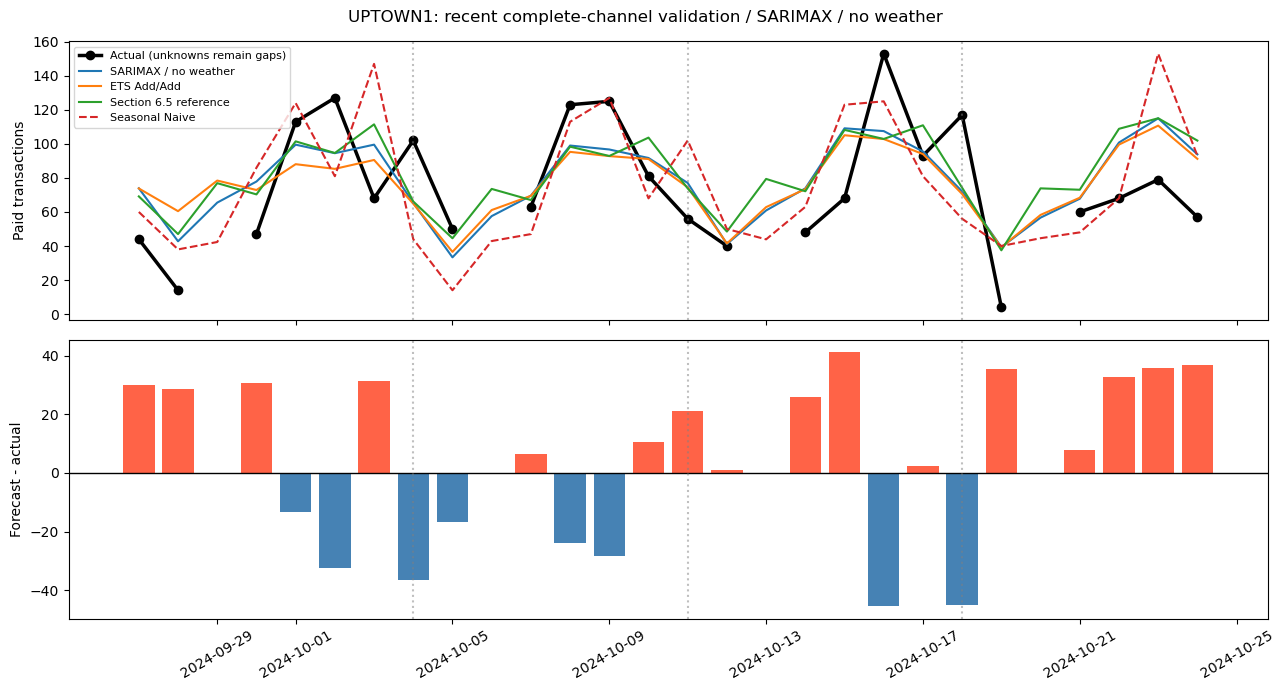

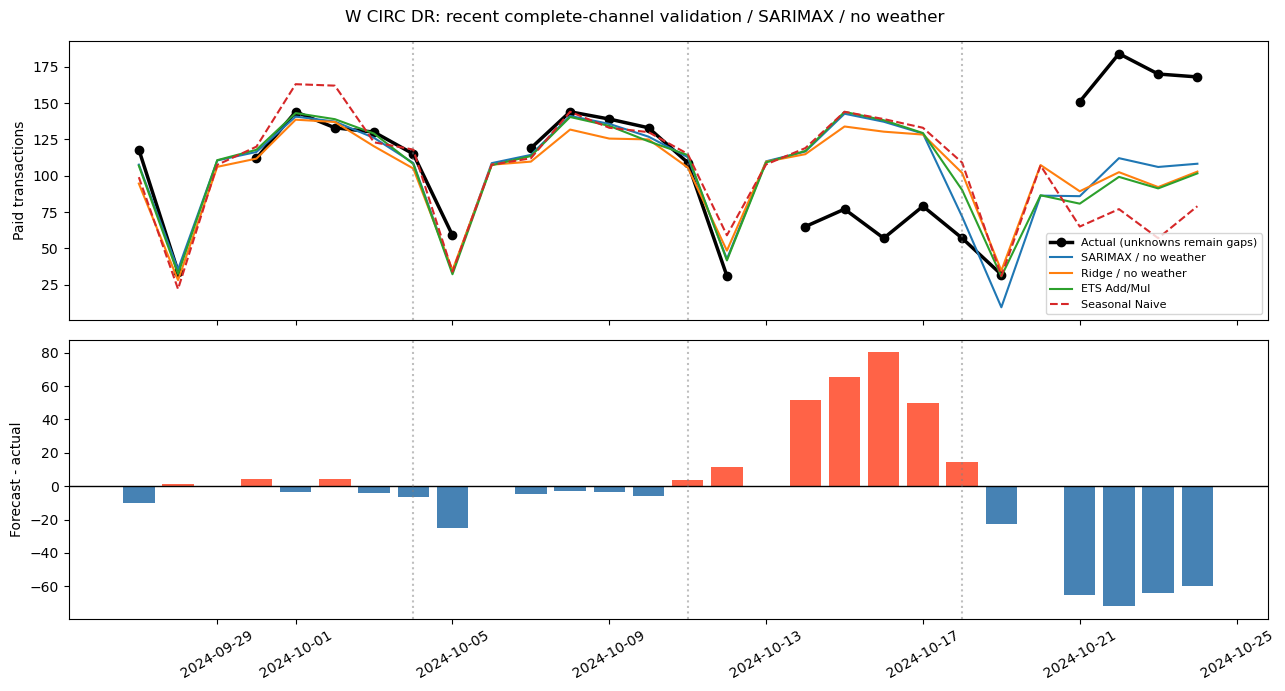

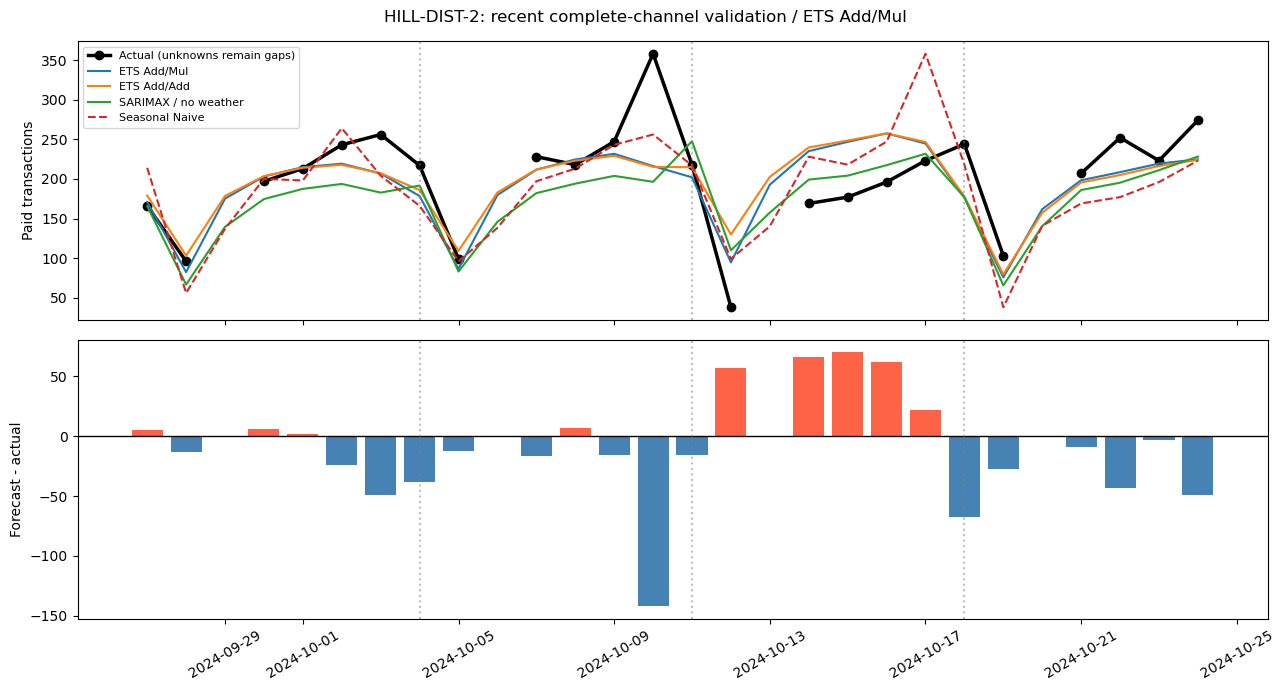

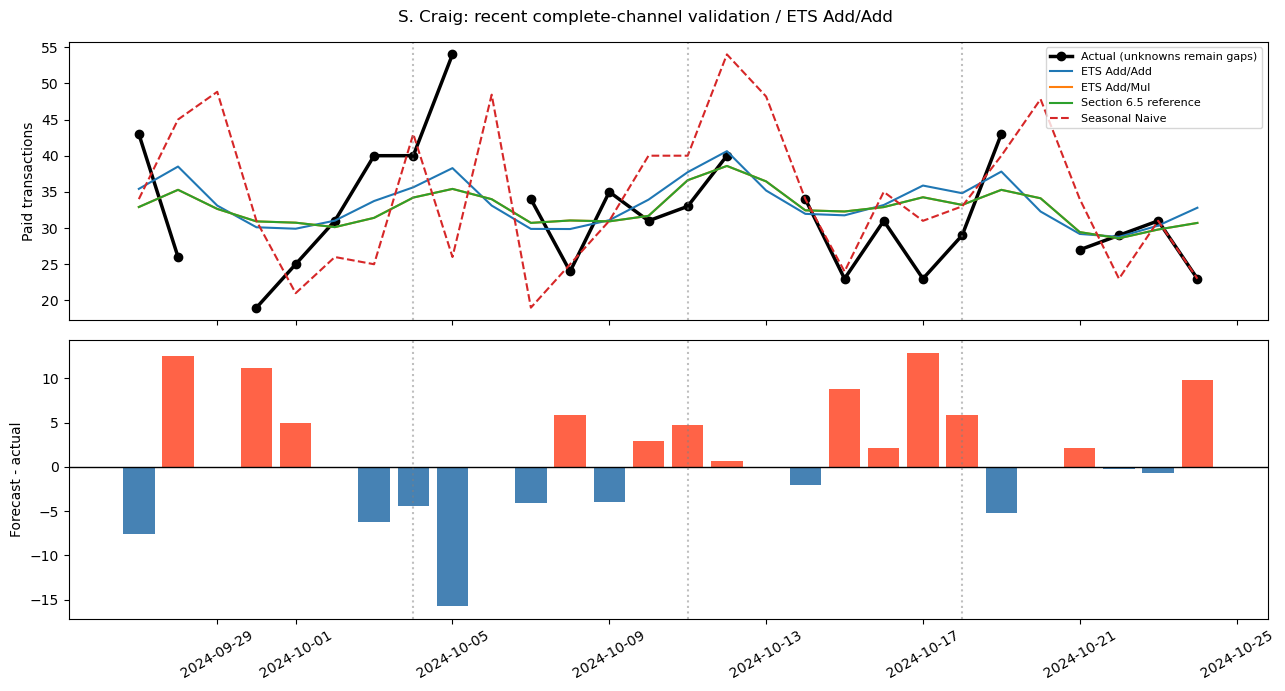

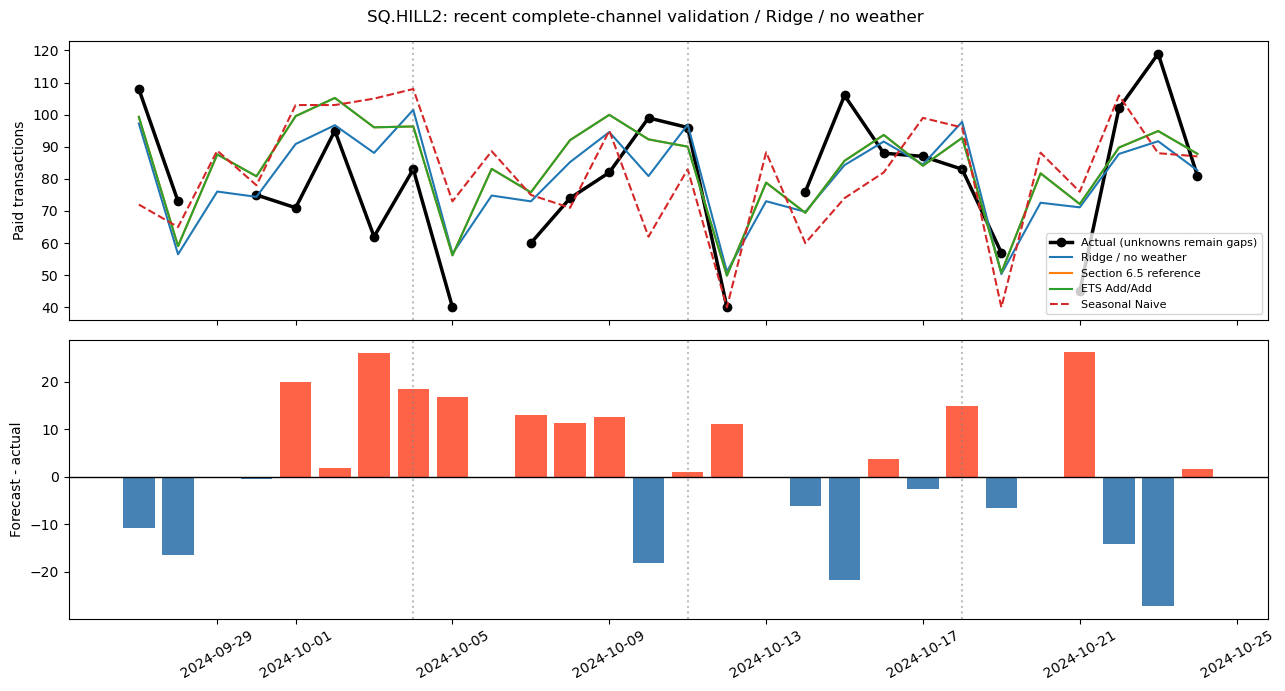

High-error-zone findings (descriptive, not causal):
HILL-DIST-2: ETS Add/Mul; MAE=34.25, WAPE=16.9%, bias=-9.70; RMSE improvement=11.3%; better than baseline in 3/4 weeks.
S. Craig: ETS Add/Add; MAE=5.60, WAPE=17.5%, bias=1.43; RMSE improvement=30.0%; better than baseline in 3/4 weeks.
SQ.HILL2: Ridge / no weather; MAE=12.60, WAPE=15.9%, bias=2.22; RMSE improvement=32.4%; better than baseline in 4/4 weeks.
UPTOWN1: SARIMAX / no weather; MAE=25.87, WAPE=34.5%, bias=5.71; RMSE improvement=23.7%; better than baseline in 4/4 weeks.
W CIRC DR: SARIMAX / no weather; MAE=26.55, WAPE=24.9%, bias=-2.56; RMSE improvement=25.5%; better than baseline in 3/4 weeks.


In [ ]:
_recent = p34_validation_df.loc[p34_validation_df['Window'].eq(p34_final_window)].copy()
p34_selected_daily_df = _recent.merge(p34_frozen_plan_df[['Zone', 'Model']],
    on=['Zone', 'Model'], validate='many_to_one')
_thresholds = {}
_first_origin = min(pd.Timestamp(a) for a, b in backtest_periods.values())
for zone in p34_zones:
    _thresholds[zone] = p34_train_slice(series_by_zone[zone], _first_origin, p34_final_window).dropna().quantile(.25)
p34_selected_daily_df['Low-volume threshold'] = p34_selected_daily_df['Zone'].map(_thresholds)
p34_selected_daily_df['Low Actual'] = p34_selected_daily_df['Actual'].le(p34_selected_daily_df['Low-volume threshold'])
p34_selected_daily_df['Weekday'] = p34_selected_daily_df['Date'].dt.day_name()
_weekly_rows = []
for (zone, model, period), part in _recent.groupby(['Zone', 'Model', 'Period']):
    _weekly_rows.append({'Zone': zone, 'Model': model, 'Period': period, **p34_metrics(part['Actual'], part['Forecast'])})
p34_weekly_all_df = pd.DataFrame(_weekly_rows)
p34_weekly_selected_df = p34_weekly_all_df.merge(p34_frozen_plan_df[['Zone', 'Model']], on=['Zone', 'Model'])
_base_week = p34_weekly_all_df.loc[p34_weekly_all_df['Model'].eq('Seasonal Naive'), ['Zone', 'Period', 'RMSE']].rename(columns={'RMSE': 'Baseline RMSE'})
p34_weekly_selected_df = p34_weekly_selected_df.merge(_base_week, on=['Zone', 'Period'], validate='one_to_one')
p34_weekly_selected_df['Beats Baseline'] = p34_weekly_selected_df['RMSE'] < p34_weekly_selected_df['Baseline RMSE']
_summary = p34_weekly_selected_df.groupby('Zone').agg(
    **{'Weekly RMSE SD': ('RMSE', lambda s: s.std(ddof=0)),
       'Worst Weekly RMSE': ('RMSE', 'max'), 'Weeks Better than Baseline': ('Beats Baseline', 'sum')}).reset_index()
p34_diagnostic_summary_df = p34_frozen_plan_df.merge(_summary, on='Zone', validate='one_to_one')
_base_overall = p34_model_comparison_df.loc[p34_model_comparison_df['Window'].eq(p34_final_window)
    & p34_model_comparison_df['Model'].eq('Seasonal Naive'), ['Zone', 'RMSE']].rename(columns={'RMSE': 'Baseline RMSE'})
p34_diagnostic_summary_df = p34_diagnostic_summary_df.merge(_base_overall, on='Zone')
p34_diagnostic_summary_df['RMSE Improvement %'] = 100*(p34_diagnostic_summary_df['Baseline RMSE']-p34_diagnostic_summary_df['RMSE'])/p34_diagnostic_summary_df['Baseline RMSE'].replace(0, np.nan)
p34_top_errors_df = (p34_selected_daily_df.loc[p34_selected_daily_df['Zone'].isin(p34_focus_zones)
    & p34_selected_daily_df['Actual'].notna()].sort_values(['Zone', 'Abs Error'], ascending=[True, False])
    .groupby('Zone', sort=False).head(5).copy())
_volume_rows = []
for (zone, low), part in p34_selected_daily_df.loc[p34_selected_daily_df['Zone'].isin(p34_focus_zones)
    & p34_selected_daily_df['Actual'].notna()].groupby(['Zone', 'Low Actual']):
    _volume_rows.append({'Zone': zone, 'Group': 'Low volume' if low else 'Other observed days',
        'Threshold': _thresholds[zone], 'Mean Actual': part['Actual'].mean(), **p34_metrics(part['Actual'], part['Forecast'])})
p34_low_volume_df = pd.DataFrame(_volume_rows)
print('Focus-zone diagnostic summary:')
display(p34_diagnostic_summary_df.loc[p34_diagnostic_summary_df['Zone'].isin(p34_focus_zones)].round(2))
print('Weekly actual-vs-forecast errors:')
display(p34_weekly_selected_df.loc[p34_weekly_selected_df['Zone'].isin(p34_focus_zones)].round(2))
print('Largest five daily errors per focus zone:')
display(p34_top_errors_df[['Zone', 'Date', 'Weekday', 'Model', 'Actual', 'Forecast', 'Error', 'APE %', 'Low Actual']])
print('Low-volume comparison; inspect N scored before interpreting percentages:')
display(p34_low_volume_df.round(2))
for zone in p34_focus_zones:
    actual = p34_selected_daily_df.loc[p34_selected_daily_df['Zone'].eq(zone)].sort_values('Date')
    best = p34_frozen_plan_df.loc[p34_frozen_plan_df['Zone'].eq(zone), 'Model'].iloc[0]
    top = p34_ranked_candidates_df.loc[p34_ranked_candidates_df['Zone'].eq(zone)].head(3)['Model'].tolist()
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    axes[0].plot(actual['Date'], actual['Actual'], 'ko-', lw=2.5, label='Actual (unknowns remain gaps)')
    for model in dict.fromkeys([best]+top+['Seasonal Naive']):
        part = _recent.loc[_recent['Zone'].eq(zone) & _recent['Model'].eq(model)].sort_values('Date')
        axes[0].plot(part['Date'], part['Forecast'], '--' if model == 'Seasonal Naive' else '-', label=model)
    scored = actual.loc[actual['Actual'].notna()]
    axes[1].bar(scored['Date'], scored['Error'], color=np.where(scored['Error'].ge(0), 'tomato', 'steelblue'))
    axes[1].axhline(0, color='black', lw=1)
    for start, end in list(backtest_periods.values())[1:]:
        for ax in axes: ax.axvline(start, ls=':', color='grey', alpha=.5)
    axes[0].legend(fontsize=8); axes[0].set_ylabel('Paid transactions')
    axes[1].set_ylabel('Forecast - actual'); axes[1].tick_params(axis='x', rotation=30)
    fig.suptitle(f'{zone}: recent complete-channel validation / {best}')
    fig.tight_layout()
    p34_plot_save(fig, 'diagnostic_'+zone.replace(' ', '_').replace('.', '_')+'.png')
print('High-error-zone findings (descriptive, not causal):')
for row in p34_diagnostic_summary_df.loc[p34_diagnostic_summary_df['Zone'].isin(p34_focus_zones)].to_dict('records'):
    print(f"{row['Zone']}: {row['Model']}; MAE={row['MAE']:.2f}, WAPE={row['WAPE %']:.1f}%, "
          f"bias={row['Bias']:.2f}; RMSE improvement={row['RMSE Improvement %']:.1f}%; "
          f"better than baseline in {int(row['Weeks Better than Baseline'])}/{len(p34_periods)} weeks.")

### 6.12a Snow Covariates and Matched-Comparison Design

Three model classes are compared: the zone-specific model family selected in Section 6.5, SARIMAX without weather, and SARIMAX with snow. Both SARIMAX variants use `(1,0,1) × (0,1,1,7)`, identical three-year training targets, training-only imputation, optimisation settings, constraints, and validation dates. Snow is the only additional predictor and is standardised using training-window statistics. Missing weather is not replaced with zero snowfall.

Daily weather comes from the shared Pittsburgh Open-Meteo historical grid described in Section 2.9 and is restricted to the study cutoff. Observed weather during the validation week is used only in the retrospective weather experiment. Snow-model predictions do not enter final-model ranking, holdout model choice, the watchlist, or the final seven-day forecast.

The fall benchmark covers all nine zones and four seven-day validation windows. The winter benchmark covers SHADYSIDE1, SHADYSIDE2, and SQ.HILL1 across 86 complete seven-day windows per zone in the 2017–2018 through 2023–2024 winters. The Section 6.5 family was selected using fall 2024 validation and is carried retrospectively into earlier winters; it is not a model family selected prospectively in each winter.

Source-coverage flags are applied to both training and target periods. All-history results are reported separately from the subset excluding the mobile-data advisory period. Valid comparisons require successful, converged fits and use identical observed target dates; planned, retained, and scored window counts are reported.


In [ ]:
import requests

def p34_weather_archive():
    first = min(series_by_zone[z].index.min() for z in p34_zones)
    last = pd.Timestamp(calendar_end)
    cache = p34_output_dir/'weather_archive_daily.csv'
    if 'zone_weather' in globals():
        candidate = zone_weather.loc[zone_weather['zone'].eq(p34_zones[0]),
            ['date','temp_mean','rain_mm','snow_cm']].copy()
    elif cache.exists():
        candidate = pd.read_csv(cache)
    else:
        if 'zone_coordinates' in globals():
            coord = zone_coordinates[['latitude','longitude']].median()
        else:
            coords = payment_points[['id','latitude','longitude']].copy()
            coords['id'] = coords['id'].astype('string').str.strip()
            for col in ['latitude','longitude']:
                coords[col] = pd.to_numeric(coords[col], errors='coerce')
            active = memberships.loc[memberships['zone'].isin(p34_zones)
                & memberships['active_physical'], ['zone','id']]
            mapped = active.merge(coords, on='id', how='left').drop_duplicates(['zone','id'])
            mapped = mapped.loc[mapped['latitude'].between(40,41) & mapped['longitude'].between(-81,-79)]
            per_zone = mapped.groupby('zone')[['latitude','longitude']].median().reindex(p34_zones)
            if per_zone.isna().any().any():
                raise ValueError('Cannot obtain all zone coordinates; run 2.9 or provide the weather cache.')
            coord = per_zone.median()
        response = requests.get('https://archive-api.open-meteo.com/v1/archive',params={
            'latitude':float(coord['latitude']), 'longitude':float(coord['longitude']),
            'start_date':first.strftime('%Y-%m-%d'), 'end_date':last.strftime('%Y-%m-%d'),
            'daily':'temperature_2m_mean,rain_sum,snowfall_sum', 'timezone':'America/New_York',
            'temperature_unit':'celsius','precipitation_unit':'mm'},timeout=60)
        response.raise_for_status()
        candidate = pd.DataFrame(response.json()['daily']).rename(columns={
            'time':'date','temperature_2m_mean':'temp_mean','rain_sum':'rain_mm','snowfall_sum':'snow_cm'})
    candidate['date'] = pd.to_datetime(candidate['date'])
    if candidate['date'].duplicated().any():
        raise ValueError('Duplicate weather dates.')
    candidate = candidate.set_index('date').sort_index().reindex(pd.date_range(first,last))
    if candidate[['temp_mean','rain_mm','snow_cm']].isna().any().any():
        raise ValueError('Incomplete weather archive; missing weather is not zero snowfall.')
    if candidate['snow_cm'].lt(0).any():
        raise ValueError('Negative snowfall.')
    candidate.rename_axis('date').reset_index().to_csv(cache,index=False)
    return candidate

p34_weather_daily = p34_weather_archive()

def p34_source_safe(start, end):
    # Conservative boundary around the provider's April/May 2021 advisory.
    return bool(pd.Timestamp(end) < pd.Timestamp('2021-04-01')
        or pd.Timestamp(start) >= p34_clean_start)

def p34_snow_fit(raw, index):
    train = p34_prepare(raw)
    weather_train = p34_weather_daily.reindex(raw.index)[['snow_cm']]
    weather_test = p34_weather_daily.reindex(index)[['snow_cm']]
    if weather_train.isna().any().any() or weather_test.isna().any().any():
        raise ValueError('Snow inputs must be observed; do not impute unknown future weather.')
    mean = weather_train.mean()
    scale = weather_train.std(ddof=0).replace(0,1)
    x_train, x_test = (weather_train-mean)/scale, (weather_test-mean)/scale
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        fitted = SARIMAX(train, exog=x_train, order=(1,0,1), seasonal_order=(0,1,1,7),
            enforce_stationarity=True, enforce_invertibility=True).fit(disp=False,maxiter=200)
        pred = np.maximum(np.asarray(fitted.forecast(7, exog=x_test),dtype=float),0)
    if len(pred) != 7 or not np.isfinite(pred).all():
        raise ValueError('Incomplete/nonfinite snow-model forecast.')
    info = {'Status':'ok','Converged':bool(fitted.mle_retvals.get('converged',False)),
        'Warnings':' | '.join(dict.fromkeys(str(w.message) for w in caught)),
        'Snow Coefficient (standardised)':float(fitted.params.get('snow_cm',np.nan))}
    return pred, info

p34_weather_models = ['Section 6.5 reference','SARIMAX / no weather','SARIMAX / snow (observed)']
p34_weather_periods = []
for period,(start,end) in backtest_periods.items():
    p34_weather_periods.append({'Stage':'Fall','Winter':'Fall 2024','Period':period,
        'Start':pd.Timestamp(start),'End':pd.Timestamp(end)})
first_date = p34_weather_daily.index.min()
for year in range(first_date.year+3, pd.Timestamp(calendar_end).year):
    cursor = pd.Timestamp(year,12,1)
    last = pd.Timestamp(year+1,3,1)-pd.Timedelta(days=1)
    week = 1
    while cursor+pd.Timedelta(days=6) <= last:
        if cursor-pd.Timedelta(days=1095) >= first_date:
            p34_weather_periods.append({'Stage':'Winter','Winter':f'{year}-{str(year+1)[-2:]}',
                'Period':f'Winter {year}-{str(year+1)[-2:]} / Week {week:02d}',
                'Start':cursor,'End':cursor+pd.Timedelta(days=6)})
        cursor += pd.Timedelta(days=7); week += 1
print('Shared historical snow archive:',p34_weather_daily.index.min().date(),'to',p34_weather_daily.index.max().date())
print('No future observed weather will be used for the final forecasting MVP.')

Shared historical snow archive: 2014-01-02 to 2024-10-31
No future observed weather will be used for the final forecasting MVP.


### 6.12b Retrospective Weather Contribution and Winter Robustness

The three-way comparison evaluates the Section 6.5 reference family against matched no-weather and snow SARIMAX models. ETS is refitted at each forecast origin. Reference ARIMA order and intercept are selected from the initial training window of each winter under the predeclared search budget, then retained while coefficients are refitted on each three-year window.

Snow-specific contribution is assessed using paired no-weather and snow SARIMAX errors. The three-way comparison additionally requires a valid reference-model fit. Failed and nonconverged fits are recorded and excluded from the relevant paired analysis. Results are separated by winter and by snowy versus no-snow validation weeks.

A negative RMSE change relative to no-weather SARIMAX indicates lower error conditional on observed future snow. Winter-level consistency is summarised by the number of comparable winters with improvement, median and mean paired RMSE change, and scored-day counts. All-history and coverage-screened results are distinguished. These findings do not establish operational accuracy with weather forecasts, a causal demand response, or revenue gains.


Weather-model comparison: UPTOWN2; 4 windows
Weather-model comparison: UPTOWN1; 4 windows
Weather-model comparison: SHADYSIDE1; 90 windows
Winter progress: SHADYSIDE1 / 2017-18
Winter progress: SHADYSIDE1 / 2018-19
Winter progress: SHADYSIDE1 / 2019-20
Winter progress: SHADYSIDE1 / 2019-20
Winter progress: SHADYSIDE1 / 2020-21
Winter progress: SHADYSIDE1 / 2021-22
Winter progress: SHADYSIDE1 / 2022-23
Winter progress: SHADYSIDE1 / 2023-24
Weather-model comparison: SHADYSIDE2; 90 windows
Winter progress: SHADYSIDE2 / 2017-18
Winter progress: SHADYSIDE2 / 2018-19
Winter progress: SHADYSIDE2 / 2019-20
Winter progress: SHADYSIDE2 / 2019-20
Winter progress: SHADYSIDE2 / 2020-21
Winter progress: SHADYSIDE2 / 2021-22
Winter progress: SHADYSIDE2 / 2022-23
Winter progress: SHADYSIDE2 / 2023-24
Weather-model comparison: SQ.HILL1; 90 windows
Winter progress: SQ.HILL1 / 2017-18
Winter progress: SQ.HILL1 / 2018-19
Winter progress: SQ.HILL1 / 2019-20
Winter progress: SQ.HILL1 / 2019-20
Winter progre

,Zone,Stage,Winter,Snow Condition,Model,Planned Weeks,Retained Weeks,Scored Weeks,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,No-weather RMSE (same dates),Reference RMSE (same dates),RMSE change vs no weather %,RMSE change vs reference %
0,HILL-DIST-2,Fall,Fall 2024,No-snow week,Section 6.5 reference,4,4,4,52.56,41.88,26.62,20.67,-6.96,24,51.08,52.56,2.91,0.00
1,HILL-DIST-2,Fall,Fall 2024,No-snow week,SARIMAX / no weather,4,4,4,51.08,39.84,26.48,19.66,-17.85,24,51.08,52.56,0.00,-2.83
2,HILL-DIST-2,Fall,Fall 2024,No-snow week,SARIMAX / snow (observed),4,4,4,51.04,39.81,26.47,19.65,-17.77,24,51.08,52.56,-0.08,-2.90
3,S. Craig,Fall,Fall 2024,No-snow week,Section 6.5 reference,4,4,4,7.65,6.05,21.40,18.89,2.10,24,11.79,7.65,-35.13,0.00
4,S. Craig,Fall,Fall 2024,No-snow week,SARIMAX / no weather,4,4,4,11.79,10.13,37.78,31.65,9.01,24,11.79,7.65,0.00,54.16
5,S. Craig,Fall,Fall 2024,No-snow week,SARIMAX / snow (observed),4,4,4,11.84,10.17,37.94,31.77,9.07,24,11.79,7.65,0.43,54.82
6,SHADYSIDE1,Fall,Fall 2024,No-snow week,Section 6.5 reference,4,4,4,24.29,20.65,5.16,5.12,-0.53,24,24.72,24.29,-1.73,0.00
7,SHADYSIDE1,Fall,Fall 2024,No-snow week,SARIMAX / no weather,4,4,4,24.72,19.56,4.82,4.85,-5.86,24,24.72,24.29,0.00,1.76
8,SHADYSIDE1,Fall,Fall 2024,No-snow week,SARIMAX / snow (observed),4,4,4,24.73,19.57,4.82,4.85,-5.47,24,24.72,24.29,0.05,1.81
45,SHADYSIDE2,Fall,Fall 2024,No-snow week,Section 6.5 reference,4,4,4,40.99,31.41,5.20,4.77,16.55,24,40.52,40.99,1.14,0.00


Winter three-way comparison: reference family vs matched no-weather/snow SARIMAX:


,Zone,Stage,Winter,Snow Condition,Model,Planned Weeks,Retained Weeks,Scored Weeks,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,No-weather RMSE (same dates),Reference RMSE (same dates),RMSE change vs no weather %,RMSE change vs reference %
9,SHADYSIDE1,Winter,2017-18,Snowy week,Section 6.5 reference,12,12,12,98.77,64.16,66.68,12.63,4.27,70,97.85,98.77,0.94,0.00
10,SHADYSIDE1,Winter,2017-18,Snowy week,SARIMAX / no weather,12,12,12,97.85,56.01,65.61,11.03,28.21,70,97.85,98.77,0.00,-0.93
11,SHADYSIDE1,Winter,2017-18,Snowy week,SARIMAX / snow (observed),12,12,12,91.64,50.31,64.31,9.90,22.81,70,97.85,98.77,-6.35,-7.22
12,SHADYSIDE1,Winter,2018-19,No-snow week,Section 6.5 reference,3,3,3,132.41,72.23,89.52,14.30,-3.15,18,125.02,132.41,5.91,0.00
13,SHADYSIDE1,Winter,2018-19,No-snow week,SARIMAX / no weather,3,3,3,125.02,56.45,85.61,11.18,23.55,18,125.02,132.41,0.00,-5.58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,SQ.HILL1,Winter,2023-24,No-snow week,SARIMAX / no weather,4,1,1,119.26,100.00,10.29,9.61,56.29,4,119.26,108.57,0.00,9.84
119,SQ.HILL1,Winter,2023-24,No-snow week,SARIMAX / snow (observed),4,1,1,120.54,101.45,10.45,9.75,58.59,4,119.26,108.57,1.08,11.03
120,SQ.HILL1,Winter,2023-24,Snowy week,Section 6.5 reference,9,3,3,136.54,108.74,13.55,11.34,1.46,17,120.57,136.54,13.25,0.00
121,SQ.HILL1,Winter,2023-24,Snowy week,SARIMAX / no weather,9,3,3,120.57,90.91,11.44,9.48,-11.40,17,120.57,136.54,0.00,-11.70


Snow-only increment; all-history retrospective screen (negative change = improvement):


...

,Zone,Stage,Winter,Snow Condition,Model,Planned Weeks,Retained Weeks,Scored Weeks,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,No-weather RMSE (same dates),Reference RMSE (same dates),RMSE change vs no weather %,RMSE change vs reference %
0,SHADYSIDE1,Winter,2017-18,Snowy week,SARIMAX / no weather,12,12,12,97.85,56.01,65.61,11.03,28.21,70,97.85,NaN,0.00,NaN
1,SHADYSIDE1,Winter,2017-18,Snowy week,SARIMAX / snow (observed),12,12,12,91.64,50.31,64.31,9.90,22.81,70,97.85,NaN,-6.35,NaN
2,SHADYSIDE1,Winter,2018-19,No-snow week,SARIMAX / no weather,3,3,3,125.02,56.45,85.61,11.18,23.55,18,125.02,NaN,0.00,NaN
3,SHADYSIDE1,Winter,2018-19,No-snow week,SARIMAX / snow (observed),3,3,3,126.01,58.10,86.47,11.51,30.89,18,125.02,NaN,0.79,NaN
4,SHADYSIDE1,Winter,2018-19,Snowy week,SARIMAX / no weather,9,9,9,81.60,61.51,14.11,12.36,38.56,50,81.60,NaN,0.00,NaN
5,SHADYSIDE1,Winter,2018-19,Snowy week,SARIMAX / snow (observed),9,9,9,76.12,56.28,12.80,11.31,31.57,50,81.60,NaN,-6.71,NaN
6,SHADYSIDE1,Winter,2019-20,No-snow week,SARIMAX / no weather,2,2,2,50.25,31.93,6.73,6.07,9.59,10,50.25,NaN,0.00,NaN
7,SHADYSIDE1,Winter,2019-20,No-snow week,SARIMAX / snow (observed),2,2,2,50.44,32.34,6.82,6.14,11.06,10,50.25,NaN,0.38,NaN
8,SHADYSIDE1,Winter,2019-20,Snowy week,SARIMAX / no weather,11,11,11,40.22,32.39,6.19,6.12,2.75,64,40.22,NaN,0.00,NaN
9,SHADYSIDE1,Winter,2019-20,Snowy week,SARIMAX / snow (observed),11,11,11,36.49,30.89,5.80,5.84,-0.73,64,40.22,NaN,-9.29,NaN


Consistency across snowy winters; NOT issue-time forecasting accuracy:


,Zone,Winters,Winters_Improved,Median_Change_Pct,Mean_Change_Pct,Total_Scored_Days
0,SHADYSIDE1,7,7,-8.55,-9.06,392
1,SHADYSIDE2,7,7,-9.30,-9.11,392
2,SQ.HILL1,7,7,-12.08,-11.26,393


Failed/nonconverged weather/reference fits:


,Zone,Stage,Winter,Period,Snow Condition,Snow Days,Training Source Safe,Target Source Safe,Model,Reference Family,Train Start,Train End,Training Days,Status,Converged,Warnings,Snow Coefficient (standardised)
672,SQ.HILL1,Winter,2019-20,Winter 2019-20 / Week 09,Snowy week,6,True,True,Section 6.5 reference,Auto ARIMA Seasonal,2017-01-26,2020-01-25,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
687,SQ.HILL1,Winter,2020-21,Winter 2020-21 / Week 01,Snowy week,5,True,True,Section 6.5 reference,Auto ARIMA Seasonal,2017-12-02,2020-11-30,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
696,SQ.HILL1,Winter,2020-21,Winter 2020-21 / Week 04,Snowy week,4,True,True,Section 6.5 reference,Auto ARIMA Seasonal,2017-12-23,2020-12-21,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
702,SQ.HILL1,Winter,2020-21,Winter 2020-21 / Week 06,Snowy week,1,True,True,Section 6.5 reference,Auto ARIMA Seasonal,2018-01-06,2021-01-04,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
798,SQ.HILL1,Winter,2023-24,Winter 2023-24 / Week 02,No-snow week,0,False,True,Section 6.5 reference,Auto ARIMA Seasonal,2020-12-08,2023-12-07,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
807,SQ.HILL1,Winter,2023-24,Winter 2023-24 / Week 05,Snowy week,5,False,True,Section 6.5 reference,Auto ARIMA Seasonal,2020-12-29,2023-12-28,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
810,SQ.HILL1,Winter,2023-24,Winter 2023-24 / Week 06,Snowy week,4,False,True,Section 6.5 reference,Auto ARIMA Seasonal,2021-01-05,2024-01-04,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
816,SQ.HILL1,Winter,2023-24,Winter 2023-24 / Week 08,Snowy week,2,False,True,Section 6.5 reference,Auto ARIMA Seasonal,2021-01-19,2024-01-18,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
819,SQ.HILL1,Winter,2023-24,Winter 2023-24 / Week 09,No-snow week,0,False,True,Section 6.5 reference,Auto ARIMA Seasonal,2021-01-26,2024-01-25,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN
822,SQ.HILL1,Winter,2023-24,Winter 2023-24 / Week 10,No-snow week,0,False,True,Section 6.5 reference,Auto ARIMA Seasonal,2021-02-02,2024-02-01,1095,ok,False,Maximum Likelihood optimization failed to conv...,NaN


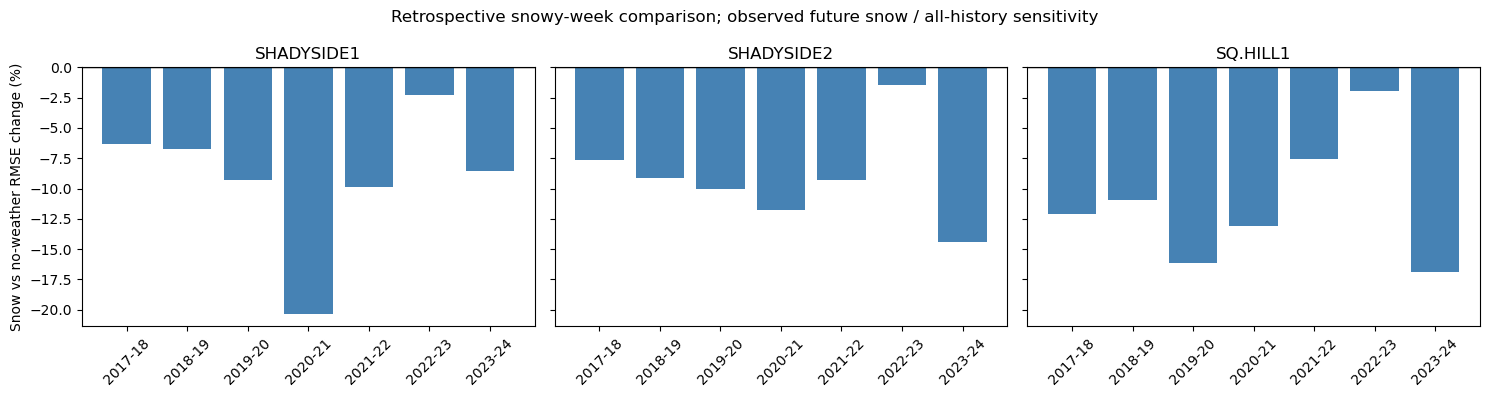

Weather experiment is separate: its snow forecasts are NOT final-model candidates.


In [ ]:
p34_weather_predictions, p34_weather_fit_rows = [], []
p34_snow_focus = ['SHADYSIDE1','SHADYSIDE2','SQ.HILL1']
for zone in p34_zones:
    periods_for_zone = [p for p in p34_weather_periods if p['Stage']=='Fall' or zone in p34_snow_focus]
    print(f'Weather-model comparison: {zone}; {len(periods_for_zone)} windows',flush=True)
    y = series_by_zone[zone]
    for number, p in enumerate(periods_for_zone):
        if p['Stage']=='Winter' and number % 12 == 4:
            print(f"Winter progress: {zone} / {p['Winter']}",flush=True)
        index = pd.date_range(p['Start'],p['End'])
        raw = p34_train_slice(y,p['Start'],'Three-year sensitivity')
        snow_days = int(p34_weather_daily.reindex(index)['snow_cm'].gt(0).sum())
        meta = {'Zone':zone,'Stage':p['Stage'],'Winter':p['Winter'],'Period':p['Period'],
            'Snow Condition':'Snowy week' if snow_days else 'No-snow week','Snow Days':snow_days,
            'Training Source Safe':p34_source_safe(raw.index.min(),raw.index.max()),
            'Target Source Safe':p34_source_safe(index.min(),index.max())}
        for model in p34_weather_models:
            try:
                if p['Stage']=='Fall' and model != 'SARIMAX / snow (observed)':
                    saved = p34_validation_df.loc[p34_validation_df['Zone'].eq(zone)
                        & p34_validation_df['Window'].eq('Three-year sensitivity')
                        & p34_validation_df['Period'].eq(p['Period']) & p34_validation_df['Model'].eq(model)].sort_values('Date')
                    status_row = p34_fit_status_df.loc[p34_fit_status_df['Zone'].eq(zone)
                        & p34_fit_status_df['Window'].eq('Three-year sensitivity')
                        & p34_fit_status_df['Period'].eq(p['Period']) & p34_fit_status_df['Model'].eq(model)].iloc[0]
                    if len(saved) != 7:
                        raise ValueError('Earlier validation fit did not produce all seven predictions.')
                    pred, info = saved['Forecast'].to_numpy(), status_row.to_dict()
                elif model == 'SARIMAX / snow (observed)':
                    pred, info = p34_snow_fit(raw,index)
                else:
                    pred, info = p34_fit(raw,index,model,zone=zone,reference_scope=f"Winter: {p['Winter']}")
                p34_weather_predictions.append(pd.DataFrame({**meta,'Model':model,'Date':index,
                    'Actual':y.reindex(index).to_numpy(),'Forecast':pred}))
            except Exception as exc:
                info = {'Status':f'failed: {type(exc).__name__}: {exc}','Converged':False,'Warnings':''}
            p34_weather_fit_rows.append({**meta,'Model':model,'Reference Family':p34_reference_map[zone]
                if model=='Section 6.5 reference' else '',
                'Train Start':raw.index.min(),'Train End':raw.index.max(),'Training Days':len(raw),
                'Status':info['Status'],'Converged':bool(info['Converged']),
                'Warnings':info.get('Warnings',''),'Snow Coefficient (standardised)':info.get('Snow Coefficient (standardised)',np.nan)})
p34_weather_predictions_df = pd.concat(p34_weather_predictions,ignore_index=True)
p34_weather_fit_status_df = pd.DataFrame(p34_weather_fit_rows)
_weather_keys = ['Zone','Stage','Winter','Period']
_status = p34_weather_fit_status_df.assign(Success=lambda d: d['Status'].eq('ok') & d['Converged'])
_status_wide = _status.pivot(index=_weather_keys,columns='Model',values='Success').fillna(False)
_three_ok = _status_wide[p34_weather_models].all(axis=1)
_pair_ok = _status_wide[['SARIMAX / no weather','SARIMAX / snow (observed)']].all(axis=1)
_eligible_three = _three_ok.rename('Three-way complete').reset_index()
_eligible_pair = _pair_ok.rename('Snow pair complete').reset_index()
p34_weather_scored_df = p34_weather_predictions_df.merge(_eligible_three,on=_weather_keys,validate='many_to_one').merge(
    _eligible_pair,on=_weather_keys,validate='many_to_one')

def p34_weather_summary(table, grouping, models, complete_col):
    records = []
    for key, group in table.groupby(grouping,sort=True):
        if not isinstance(key,tuple): key=(key,)
        eligible = group.loc[group[complete_col]].copy()
        wide = eligible.pivot(index=['Period','Date'],columns='Model',values='Forecast').reindex(columns=models)
        truth = eligible.groupby(['Period','Date'])['Actual'].agg(['first','nunique'])
        if truth['nunique'].gt(1).any(): raise ValueError('Actuals differ across weather variants.')
        valid = truth['first'].notna().reindex(wide.index,fill_value=False) & np.isfinite(wide).all(axis=1)
        wide = wide.loc[valid]; actual = truth['first'].reindex(wide.index)
        base_metrics = p34_metrics(actual,wide['SARIMAX / no weather'])
        ref_rmse = p34_metrics(actual,wide['Section 6.5 reference'])['RMSE'] if 'Section 6.5 reference' in models else np.nan
        for model in models:
            metrics = p34_metrics(actual,wide[model])
            base = base_metrics['RMSE']
            records.append({**dict(zip(grouping,key)),'Model':model,
                'Planned Weeks':group['Period'].nunique(),'Retained Weeks':eligible['Period'].nunique(),
                'Scored Weeks':wide.index.get_level_values('Period').nunique(),**metrics,
                'No-weather RMSE (same dates)':base,'Reference RMSE (same dates)':ref_rmse,
                'RMSE change vs no weather %':100*(metrics['RMSE']-base)/base if base>0 else np.nan,
                'RMSE change vs reference %':100*(metrics['RMSE']-ref_rmse)/ref_rmse if ref_rmse>0 else np.nan})
    return pd.DataFrame(records)

_g = ['Zone','Stage','Winter','Snow Condition']
p34_weather_threeway_df = p34_weather_summary(p34_weather_scored_df,_g,p34_weather_models,'Three-way complete')
p34_weather_pair_df = p34_weather_summary(p34_weather_scored_df,_g,
    ['SARIMAX / no weather','SARIMAX / snow (observed)'],'Snow pair complete')
_clean_weather = p34_weather_scored_df.loc[p34_weather_scored_df['Training Source Safe']
    & p34_weather_scored_df['Target Source Safe']]
p34_weather_clean_pair_df = p34_weather_summary(_clean_weather,_g,
    ['SARIMAX / no weather','SARIMAX / snow (observed)'],'Snow pair complete')
_snow = p34_weather_pair_df.loc[p34_weather_pair_df['Stage'].eq('Winter')
    & p34_weather_pair_df['Snow Condition'].eq('Snowy week')
    & p34_weather_pair_df['Model'].eq('SARIMAX / snow (observed)')
    & p34_weather_pair_df['N scored'].gt(0)]
p34_weather_consistency_df = _snow.groupby('Zone').agg(
    Winters=('Winter','nunique'),Winters_Improved=('RMSE change vs no weather %',lambda s:int(s.lt(0).sum())),
    Median_Change_Pct=('RMSE change vs no weather %','median'),
    Mean_Change_Pct=('RMSE change vs no weather %','mean'),Total_Scored_Days=('N scored','sum')).reset_index()
print('Fall three-way comparison, on the SAME three-year windows and scored dates:')
display(p34_weather_threeway_df.loc[p34_weather_threeway_df['Stage'].eq('Fall')].round(2))
print('Winter three-way comparison: reference family vs matched no-weather/snow SARIMAX:')
display(p34_weather_threeway_df.loc[p34_weather_threeway_df['Stage'].eq('Winter')].round(2))
print('Snow-only increment; all-history retrospective screen (negative change = improvement):')
display(p34_weather_pair_df.loc[p34_weather_pair_df['Stage'].eq('Winter')].round(2))
print('Clean-source paired subset; excludes advisory-affected TRAIN and TARGET periods:')
display(p34_weather_clean_pair_df.round(2))
print('Consistency across snowy winters; NOT issue-time forecasting accuracy:')
display(p34_weather_consistency_df.round(2))
print('Failed/nonconverged weather/reference fits:')
display(p34_weather_fit_status_df.loc[p34_weather_fit_status_df['Status'].ne('ok')
    | ~p34_weather_fit_status_df['Converged']])
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,zone in zip(axes,p34_snow_focus):
    part=_snow.loc[_snow['Zone'].eq(zone)].sort_values('Winter')
    ax.bar(part['Winter'],part['RMSE change vs no weather %'],
        color=np.where(part['RMSE change vs no weather %'].lt(0),'steelblue','tomato'))
    ax.axhline(0,color='black',lw=1); ax.set_title(zone); ax.tick_params(axis='x',rotation=45)
axes[0].set_ylabel('Snow vs no-weather RMSE change (%)')
fig.suptitle('Retrospective snowy-week comparison; observed future snow / all-history sensitivity')
fig.tight_layout(); p34_plot_save(fig,'snow_sarimax_paired_winter_comparison.png')
assert set(p34_weather_models)==set(p34_weather_fit_status_df['Model'])
assert p34_weather_predictions_df['Date'].max()<pd.Timestamp(holdout_start)
print('Weather experiment is separate: its snow forecasts are NOT final-model candidates.')

### 6.13 Reserved Holdout Assessment

The validation-selected models are assessed on **2024-10-25–2024-10-31**. Candidate ranking, training-history policy, and model specifications are fixed before this assessment. Unknown actuals remain missing and are excluded from scoring.

If a selected model fails or does not converge during refitting, the first successful, converged candidate in the frozen validation ranking is used. Numerical fallback is recorded and is never chosen using holdout accuracy. Reported metrics include RMSE, MAE, MAPE, WAPE, bias, Seasonal Naive RMSE, and empirical coverage of the heuristic error bands.

Because this short holdout week has been reviewed during model development, its results are descriptive diagnostics rather than a newly unseen confirmatory test. Poor performance remains visible and can trigger manual review; it does not trigger model reselection.


Reserved holdout assessment; no model was selected using these errors:


,Zone,Validation Winner,Holdout Model,Numerical Fallback,RMSE,MAE,MAPE %,WAPE %,Bias,N scored,Baseline RMSE,Heuristic Band Coverage,Converged
0,HILL-DIST-2,ETS Add/Mul,ETS Add/Mul,False,17.545,14.646,8.495,7.127,-2.235,6,26.870,1.000,True
1,S. Craig,ETS Add/Add,ETS Add/Add,False,7.045,6.007,24.652,22.956,5.366,6,6.621,0.833,True
2,SHADYSIDE1,SARIMAX / no weather,SARIMAX / no weather,False,30.545,27.448,7.495,7.395,25.819,6,42.994,0.667,True
3,SHADYSIDE2,Ridge / no weather,Ridge / no weather,False,32.469,30.775,4.764,4.624,-23.704,6,38.949,1.000,True
4,SQ.HILL1,Section 6.5 reference,Section 6.5 reference,False,39.283,34.419,3.670,3.682,-4.567,6,39.573,1.000,True
5,SQ.HILL2,Ridge / no weather,Ridge / no weather,False,11.217,8.932,11.266,11.096,-0.907,6,19.192,1.000,True
6,UPTOWN1,SARIMAX / no weather,SARIMAX / no weather,False,38.785,27.261,23.309,29.365,-21.454,6,52.852,0.667,True
7,UPTOWN2,Section 6.5 reference,Section 6.5 reference,False,62.550,48.893,10.483,9.730,-48.893,6,86.287,0.500,True
8,W CIRC DR,SARIMAX / no weather,SARIMAX / no weather,False,16.498,14.837,10.265,11.127,-10.815,6,46.918,1.000,True


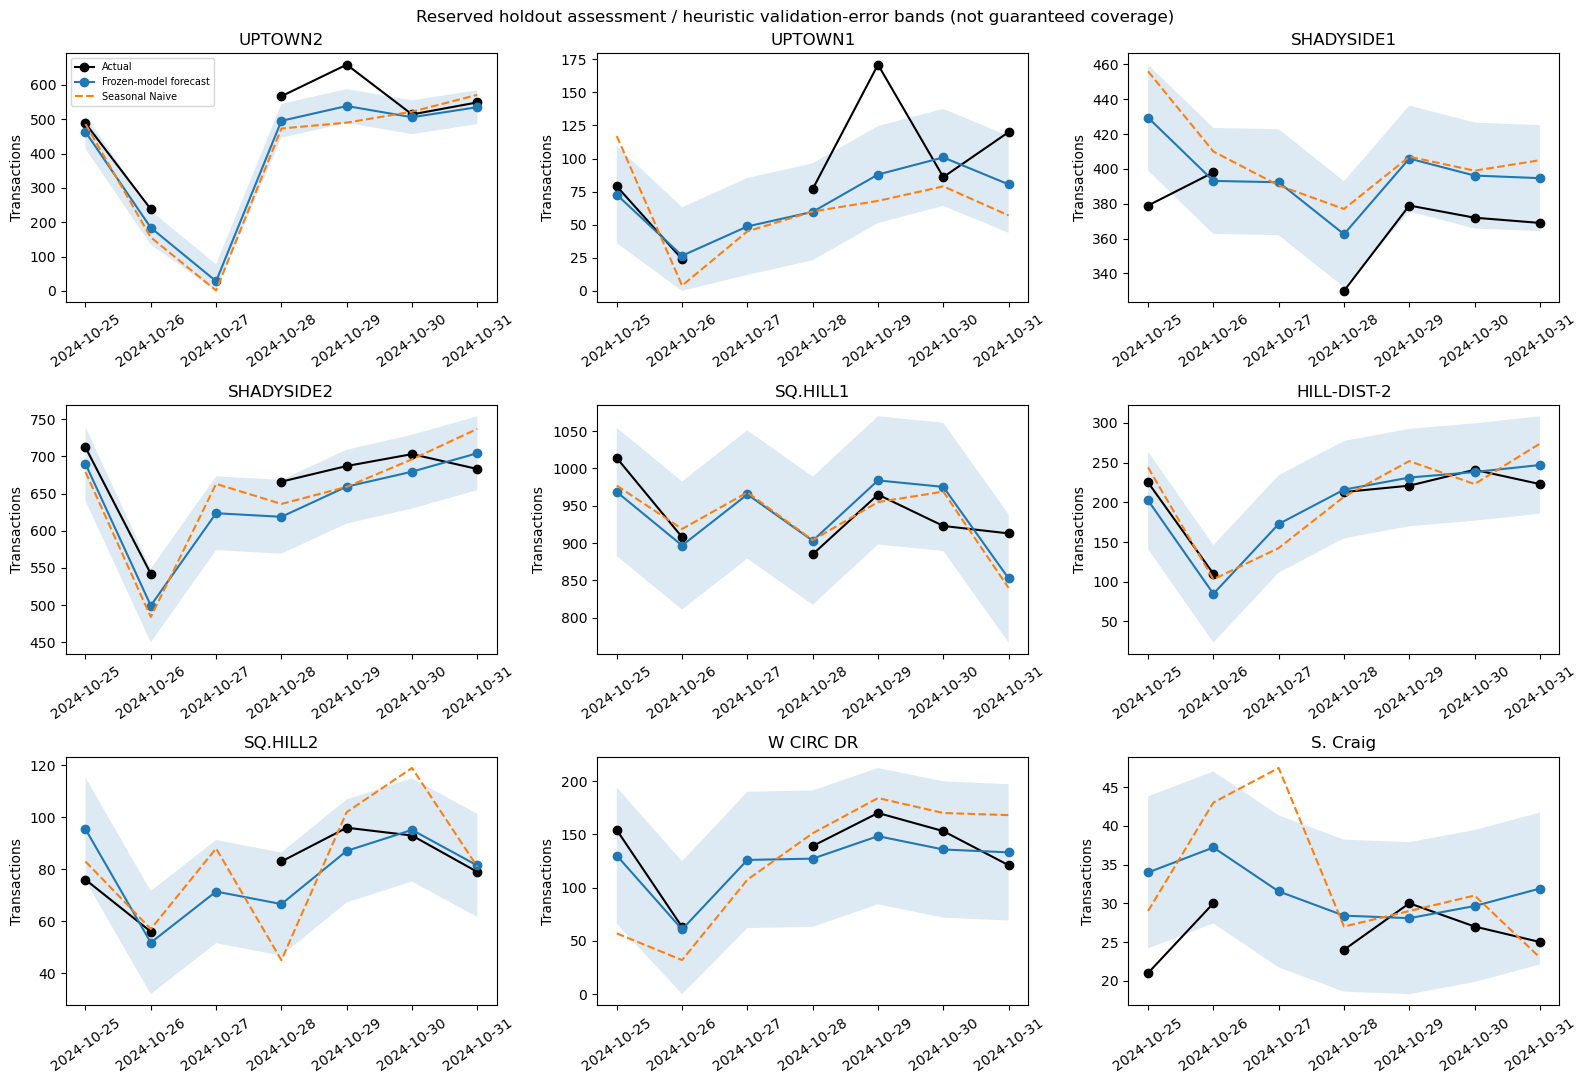

In [ ]:
def p34_refit_ranked(zone, origin, index, preferred=None):
    candidates = p34_ranked_candidates_df.loc[p34_ranked_candidates_df['Zone'].eq(zone), 'Model'].tolist()
    if preferred is not None:
        candidates = [preferred]+[m for m in candidates if m != preferred]
    attempts = []
    raw = p34_train_slice(series_by_zone[zone], origin, p34_final_window)
    for model in candidates:
        try:
            pred, info = p34_fit(raw, index, model, zone=zone)
            attempts.append(info)
            if info['Converged']:
                return pred, info, raw, attempts
        except Exception as exc:
            attempts.append({'Model': model, 'Status': f'failed: {exc}', 'Converged': False})
    raise ValueError(f'{zone}: all frozen candidates failed; do not fabricate a forecast.')

p34_holdout_index = pd.date_range(holdout_start, calendar_end, freq='D')
p34_holdout_rows, p34_holdout_metric_rows, p34_refit_attempts = [], [], []
for row in p34_frozen_plan_df.to_dict('records'):
    zone = row['Zone']
    pred, info, raw, attempts = p34_refit_ranked(zone, holdout_start, p34_holdout_index)
    p34_refit_attempts.extend({'Stage': 'Holdout', 'Zone': zone, **a} for a in attempts)
    actual = series_by_zone[zone].reindex(p34_holdout_index)
    base, base_info = p34_fit(raw, p34_holdout_index, 'Seasonal Naive', zone=zone)
    selected_validation = _recent.loc[_recent['Zone'].eq(zone) & _recent['Model'].eq(info['Model'])]
    radius = p34_band_radius(selected_validation['Error'])
    lower, upper = np.maximum(pred-radius, 0), pred+radius
    scored = actual.notna().to_numpy()
    coverage = np.mean((actual.to_numpy()[scored] >= lower[scored]) & (actual.to_numpy()[scored] <= upper[scored])) if scored.any() else np.nan
    p34_holdout_rows.append(pd.DataFrame({'Zone': zone, 'Date': p34_holdout_index,
        'Model': info['Model'], 'Actual': actual.to_numpy(), 'Forecast': pred,
        'Baseline Forecast': base, 'Lower heuristic band': lower, 'Upper heuristic band': upper}))
    p34_holdout_metric_rows.append({'Zone': zone, 'Validation Winner': row['Model'],
        'Holdout Model': info['Model'], 'Numerical Fallback': info['Model'] != row['Model'],
        **p34_metrics(actual, pred), 'Baseline RMSE': p34_metrics(actual, base)['RMSE'],
        'Heuristic Band Coverage': coverage, 'Converged': info['Converged']})
p34_holdout_predictions_df = pd.concat(p34_holdout_rows, ignore_index=True)
p34_holdout_metrics_df = pd.DataFrame(p34_holdout_metric_rows)
print('Reserved holdout assessment; no model was selected using these errors:')
display(p34_holdout_metrics_df.round(3))
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, zone in zip(axes.flat, p34_zones):
    part = p34_holdout_predictions_df.loc[p34_holdout_predictions_df['Zone'].eq(zone)]
    ax.plot(part['Date'], part['Actual'], 'ko-', label='Actual')
    ax.plot(part['Date'], part['Forecast'], 'o-', label='Frozen-model forecast')
    ax.plot(part['Date'], part['Baseline Forecast'], '--', label='Seasonal Naive')
    ax.fill_between(part['Date'], part['Lower heuristic band'], part['Upper heuristic band'], alpha=.15)
    ax.set_title(zone); ax.tick_params(axis='x', rotation=35); ax.set_ylabel('Transactions')
axes.flat[0].legend(fontsize=7)
fig.suptitle('Reserved holdout assessment / heuristic validation-error bands (not guaranteed coverage)')
fig.tight_layout()
p34_plot_save(fig, 'holdout_all_nine_zones.png')

### 6.14 Seven-Day Demand Forecasts and Zone Watchlist

The frozen model families are refitted after the study cutoff to forecast **2024-11-01–2024-11-07** using the recent, coverage-screened training window. This is a historical forecast demonstration, not a current-date operational forecast. November observations after the cutoff are not used to tune or score this issuance.

Historical normal demand is the mean transaction count for each corresponding weekday over the preceding eight calendar weeks. At least four observed examples of that weekday are required. Unsupported weekdays retain an unreported raw model prediction for audit but have no published forecast, uncertainty band, or demand signal. They are not assumed to have zero demand. Watchlist totals therefore cover supported days rather than a complete seven-day occupancy estimate.

High, Normal, and Low are defined by the ±20% planning threshold relative to historical normal. A signal is labelled Tentative when its heuristic band crosses the relevant threshold. Manual review is triggered by holdout WAPE above 25%, fewer than five scored holdout days, or a numerical/model fallback. These are predefined MVP review rules, not statistically optimal pricing thresholds.

The watchlist supports prioritisation of management review. It does not estimate available spaces, price elasticity, an optimal rate, or guaranteed revenue uplift.


Seven calendar days; unsupported weekdays deliberately remain unpublished:


,Zone,Date,Model,Raw Model Forecast,Forecast,Lower heuristic band,Upper heuristic band,Historical Normal,Weekday Examples,Supported Day,Change vs Normal %,Signal,Quality,Coverage Note
0,HILL-DIST-2,2024-11-01,ETS Add/Mul,206.843988,206.843988,145.455919,268.232058,201.500,8,True,2.652103,Normal,Monitor,Observed-weekday support
1,HILL-DIST-2,2024-11-02,ETS Add/Mul,87.685211,87.685211,26.297141,149.073281,80.625,8,True,8.756851,Normal,Monitor,Observed-weekday support
2,HILL-DIST-2,2024-11-03,ETS Add/Mul,169.394538,NaN,NaN,NaN,NaN,0,False,NaN,Insufficient data,Monitor,Unsupported weekday; not zero demand
3,HILL-DIST-2,2024-11-04,ETS Add/Mul,215.760028,215.760028,154.371959,277.148098,204.375,8,True,5.570656,Normal,Monitor,Observed-weekday support
4,HILL-DIST-2,2024-11-05,ETS Add/Mul,230.320558,230.320558,168.932488,291.708628,211.625,8,True,8.834286,Normal,Monitor,Observed-weekday support
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,W CIRC DR,2024-11-03,SARIMAX / no weather,107.652788,NaN,NaN,NaN,NaN,0,False,NaN,Insufficient data,Monitor,Unsupported weekday; not zero demand
59,W CIRC DR,2024-11-04,SARIMAX / no weather,119.571099,119.571099,55.597584,183.544614,118.125,8,True,1.224211,Normal,Monitor,Observed-weekday support
60,W CIRC DR,2024-11-05,SARIMAX / no weather,145.777485,145.777485,81.803969,209.751000,145.125,8,True,0.449602,Normal,Monitor,Observed-weekday support
61,W CIRC DR,2024-11-06,SARIMAX / no weather,134.272370,134.272370,70.298855,198.245885,135.500,8,True,-0.906000,Normal,Monitor,Observed-weekday support


Zone watchlist (supported-day totals, NOT occupancy or revenue):


,Zone,Model,Forecast Start,Forecast End,Supported Days,Supported-day Forecast Total,Supported-day Historical Normal,Change vs Normal %,Signal,Review Status,Holdout WAPE %,Holdout Model,Final Model Changed,Numerical Fallback,Suggested Action
7,UPTOWN2,Section 6.5 reference,2024-11-01,2024-11-07,6,2943.90,2759.38,6.69,Normal,Monitor,9.73,Section 6.5 reference,False,False,Maintain and monitor
6,UPTOWN1,SARIMAX / no weather,2024-11-01,2024-11-07,6,495.87,470.75,5.34,Normal,Manual review,29.37,SARIMAX / no weather,False,False,Check data/model reliability before any pricin...
0,HILL-DIST-2,ETS Add/Mul,2024-11-01,2024-11-07,6,1232.27,1173.88,4.97,Normal,Monitor,7.13,ETS Add/Mul,False,False,Maintain and monitor
4,SQ.HILL1,Section 6.5 reference,2024-11-01,2024-11-07,6,5649.31,5676.88,-0.49,Normal,Monitor,3.68,Section 6.5 reference,False,False,Maintain and monitor
8,W CIRC DR,SARIMAX / no weather,2024-11-01,2024-11-07,6,676.64,683.62,-1.02,Normal,Monitor,11.13,SARIMAX / no weather,False,False,Maintain and monitor
2,SHADYSIDE1,SARIMAX / no weather,2024-11-01,2024-11-07,6,2333.62,2420.75,-3.60,Normal,Monitor,7.39,SARIMAX / no weather,False,False,Maintain and monitor
3,SHADYSIDE2,Ridge / no weather,2024-11-01,2024-11-07,6,3856.22,4026.00,-4.22,Normal,Monitor,4.62,Ridge / no weather,False,False,Maintain and monitor
5,SQ.HILL2,Ridge / no weather,2024-11-01,2024-11-07,6,475.05,502.88,-5.53,Normal,Monitor,11.10,Ridge / no weather,False,False,Maintain and monitor
1,S. Craig,ETS Add/Add,2024-11-01,2024-11-07,6,173.37,198.75,-12.77,Normal,Monitor,22.96,ETS Add/Add,False,False,Maintain and monitor


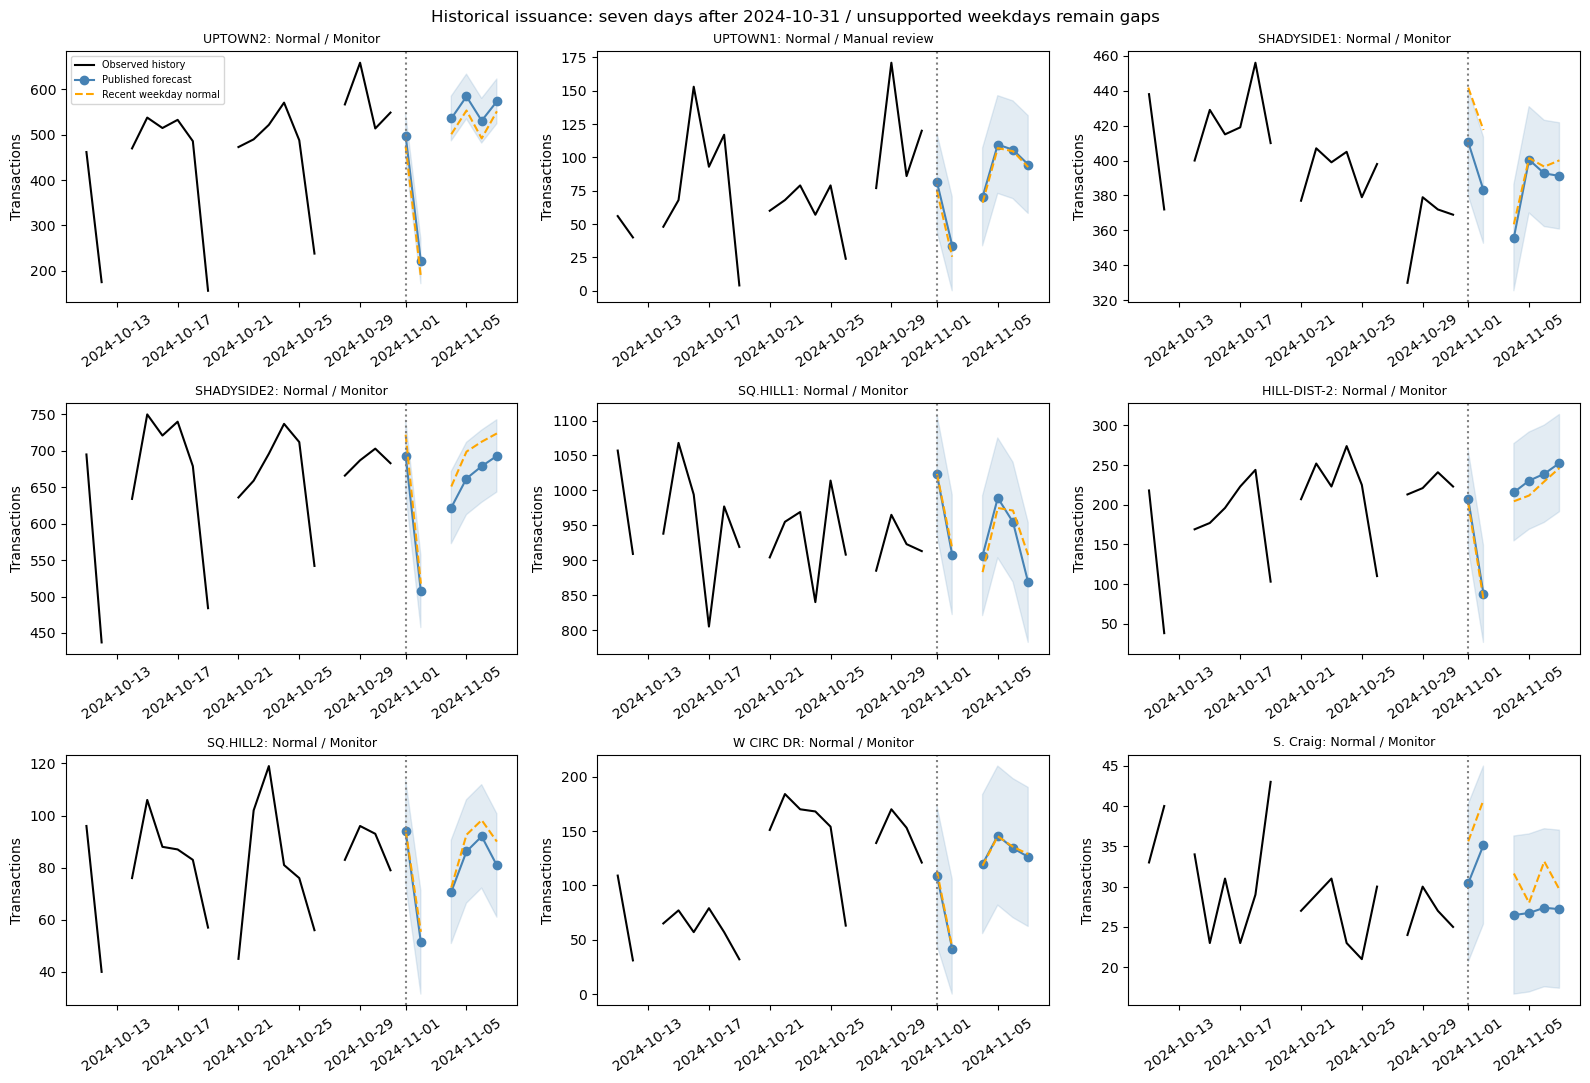

In [ ]:
p34_future_origin = pd.Timestamp(calendar_end)+pd.Timedelta(days=1)
p34_future_index = pd.date_range(p34_future_origin, periods=7, freq='D')
p34_future_rows, p34_watch_rows = [], []
for row in p34_frozen_plan_df.to_dict('records'):
    zone = row['Zone']
    hold = p34_holdout_metrics_df.loc[p34_holdout_metrics_df['Zone'].eq(zone)].iloc[0]
    pred, info, raw, attempts = p34_refit_ranked(zone, p34_future_origin, p34_future_index, preferred=hold['Holdout Model'])
    p34_refit_attempts.extend({'Stage': 'Final forecast', 'Zone': zone, **a} for a in attempts)
    final_model = info['Model']
    validation = _recent.loc[_recent['Zone'].eq(zone) & _recent['Model'].eq(final_model)]
    radius = p34_band_radius(validation['Error'])
    history = series_by_zone[zone].loc[(series_by_zone[zone].index >= p34_future_origin-pd.Timedelta(days=56))
        & (series_by_zone[zone].index < p34_future_origin)].dropna()
    normal_by_weekday = history.groupby(history.index.dayofweek).mean()
    n_by_weekday = history.groupby(history.index.dayofweek).count()
    normals = np.array([normal_by_weekday.get(d.dayofweek, np.nan) for d in p34_future_index])
    counts = np.array([n_by_weekday.get(d.dayofweek, 0) for d in p34_future_index])
    supported = (counts >= 4) & np.isfinite(normals) & (normals > 0)
    published = np.where(supported, pred, np.nan)
    lower = np.where(supported, np.maximum(pred-radius, 0), np.nan)
    upper = np.where(supported, pred+radius, np.nan)
    change = (published/normals-1)*100
    daily_signal = np.where(~supported, 'Insufficient data', np.where(change > 100*p34_signal_threshold,
        'High', np.where(change < -100*p34_signal_threshold, 'Low', 'Normal')))
    final_fallback = final_model != row['Model']
    holdout_model_changed = final_model != hold['Holdout Model']
    review = (not np.isfinite(hold['WAPE %']) or hold['WAPE %'] > 25 or hold['N scored'] < 5
        or hold['Numerical Fallback'] or final_fallback or holdout_model_changed)
    p34_future_rows.append(pd.DataFrame({'Zone': zone, 'Date': p34_future_index, 'Model': final_model,
        'Raw Model Forecast': pred, 'Forecast': published, 'Lower heuristic band': lower,
        'Upper heuristic band': upper, 'Historical Normal': normals, 'Weekday Examples': counts,
        'Supported Day': supported, 'Change vs Normal %': change, 'Signal': daily_signal,
        'Quality': 'Manual review' if review else 'Monitor',
        'Coverage Note': np.where(supported, 'Observed-weekday support', 'Unsupported weekday; not zero demand')}))
    total = float(pred[supported].sum())
    normal_total = float(normals[supported].sum())
    deviation = 100*(total/normal_total-1) if normal_total > 0 else np.nan
    signal = ('Insufficient data' if not supported.any() else 'High' if deviation > 100*p34_signal_threshold
        else 'Low' if deviation < -100*p34_signal_threshold else 'Normal')
    # Summed marginal bounds are only a sensitivity envelope, NOT an 80% weekly interval.
    envelope_low, envelope_high = np.nansum(lower), np.nansum(upper)
    tentative = ((signal == 'High' and envelope_low <= normal_total*(1+p34_signal_threshold))
        or (signal == 'Low' and envelope_high >= normal_total*(1-p34_signal_threshold)))
    confidence = 'Manual review' if review else 'Tentative' if tentative else 'Monitor'
    action = ('Check data/model reliability before any pricing decision' if review else
        'Review high demand; consider a controlled pricing pilot, not an automatic increase' if signal == 'High' else
        'Review low-demand causes and operating strategy' if signal == 'Low' else 'Maintain and monitor')
    p34_watch_rows.append({'Zone': zone, 'Model': final_model, 'Forecast Start': p34_future_index.min(),
        'Forecast End': p34_future_index.max(), 'Supported Days': int(supported.sum()),
        'Supported-day Forecast Total': total, 'Supported-day Historical Normal': normal_total,
        'Change vs Normal %': deviation, 'Signal': signal, 'Review Status': confidence,
        'Holdout WAPE %': hold['WAPE %'], 'Holdout Model': hold['Holdout Model'],
        'Final Model Changed': holdout_model_changed, 'Numerical Fallback': final_fallback,
        'Suggested Action': action})
p34_future_forecasts_df = pd.concat(p34_future_rows, ignore_index=True)
p34_watchlist_df = pd.DataFrame(p34_watch_rows).sort_values('Change vs Normal %', ascending=False)
print('Seven calendar days; unsupported weekdays deliberately remain unpublished:')
display(p34_future_forecasts_df)
print('Zone watchlist (supported-day totals, NOT occupancy or revenue):')
_watchlist_display = p34_watchlist_df.copy()
_display_numeric = _watchlist_display.select_dtypes(include='number').columns
_watchlist_display[_display_numeric] = _watchlist_display[_display_numeric].round(2)
display(_watchlist_display)
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, zone in zip(axes.flat, p34_zones):
    part = p34_future_forecasts_df.loc[p34_future_forecasts_df['Zone'].eq(zone)]
    past = series_by_zone[zone].loc[(series_by_zone[zone].index >= p34_future_origin-pd.Timedelta(days=21))
        & (series_by_zone[zone].index < p34_future_origin)]
    ax.plot(past.index, past, color='black', label='Observed history')
    ax.plot(part['Date'], part['Forecast'], 'o-', color='steelblue', label='Published forecast')
    ax.plot(part['Date'], part['Historical Normal'].where(part['Supported Day']), '--', color='orange', label='Recent weekday normal')
    ax.fill_between(part['Date'], part['Lower heuristic band'], part['Upper heuristic band'], color='steelblue', alpha=.15)
    ax.axvline(p34_future_origin, ls=':', color='grey')
    watch = p34_watchlist_df.loc[p34_watchlist_df['Zone'].eq(zone)].iloc[0]
    ax.set_title(f"{zone}: {watch['Signal']} / {watch['Review Status']}", fontsize=9)
    ax.tick_params(axis='x', rotation=35); ax.set_ylabel('Transactions')
axes.flat[0].legend(fontsize=7)
fig.suptitle('Historical issuance: seven days after 2024-10-31 / unsupported weekdays remain gaps')
fig.tight_layout()
p34_plot_save(fig, 'future_seven_days_all_nine_zones.png')

### 6.15 Reproducibility, Exported Results, and Study Limitations

The final analysis uses the prepared daily-zone series and validation definitions established in Sections 6.1 and 6.3. Sections 6.10–6.15 generate the model comparisons, weather experiment, holdout diagnostics, and final forecasts. The two input files are `transaction_info.csv` and `parking_info.csv`; file references and exports are relative to the project directory. The weather archive is reused from Section 2.9 or from the accompanying cache, or retrieved from Open-Meteo when neither is available.

Exported results include validation predictions and fit logs, model rankings and selected specifications, high-error-zone diagnostics, matched weather comparisons, holdout predictions and metrics, daily forecasts, the zone watchlist, and eight figures. Automated checks verify nine zones × seven forecast dates, no validation/holdout overlap, training strictly before each forecast origin, identical observed targets across comparisons, and finite nonnegative raw forecasts. Unsupported-day forecasts remain unpublished.

The study is a historical forecasting MVP and a management-review aid. Paid transactions are not physical occupancy. Source undercoverage, limited scored validation days, development-stage holdout review, retrospective weather inputs, and heuristic uncertainty bands limit interpretation. A current deployment would require updated transactions, verified payment coverage, issue-time weather forecasts where relevant, and operational and pricing-policy checks. Revenue effects and customer response to price changes require a controlled pricing pilot rather than extrapolation from forecast accuracy.


In [ ]:
p34_refit_attempts_df = pd.DataFrame(p34_refit_attempts)
assert len(p34_future_forecasts_df) == 9*7
assert not p34_future_forecasts_df.duplicated(['Zone', 'Date']).any()
assert set(p34_future_forecasts_df['Zone']) == set(p34_zones)
assert p34_validation_df['Date'].max() < pd.Timestamp(holdout_start)
assert p34_holdout_predictions_df['Date'].max() < p34_future_forecasts_df['Date'].min()
assert np.isfinite(p34_future_forecasts_df['Raw Model Forecast']).all()
assert p34_future_forecasts_df['Raw Model Forecast'].ge(0).all()
assert p34_future_forecasts_df.loc[~p34_future_forecasts_df['Supported Day'], 'Forecast'].isna().all()
assert p34_frozen_plan_df['Source safe'].all() and p34_frozen_plan_df['Fit eligible'].all()
assert p34_fit_status_df['Train End'].notna().all()
for row in p34_fit_status_df.to_dict('records'):
    assert pd.Timestamp(row['Train End']) < pd.Timestamp(backtest_periods[row['Period']][0])
for zone in p34_zones:
    part = p34_future_forecasts_df.loc[p34_future_forecasts_df['Zone'].eq(zone)]
    assert len(part) == 7 and part['Date'].min() == p34_future_origin
    assert part['Date'].max() == p34_future_origin+pd.Timedelta(days=6)
for (zone, window, model, period), part in p34_validation_df.groupby(['Zone', 'Window', 'Model', 'Period']):
    truth = series_by_zone[zone].reindex(part['Date']).to_numpy()
    assert np.allclose(part['Actual'], truth, equal_nan=True)
p34_reference_specifications_df = pd.DataFrame(list(p34_reference_specs.values()))
for spec in p34_reference_specs.values():
    assert pd.Timestamp(spec['Search Train End']) < pd.Timestamp(spec['Search Origin'])
print('ARIMA specifications selected from initial training windows only:')
display(p34_reference_specifications_df)
p34_export_tables = {
    'reference_arima_specifications':p34_reference_specifications_df,
    'validation_predictions': p34_validation_df, 'validation_fit_log': p34_fit_status_df,
    'history_model_comparison': p34_model_comparison_df, 'frozen_model_choices': p34_frozen_plan_df,
    'diagnostic_summary': p34_diagnostic_summary_df, 'weekly_diagnostics': p34_weekly_selected_df,
    'largest_error_dates': p34_top_errors_df, 'low_volume_diagnostics': p34_low_volume_df,
    'holdout_predictions': p34_holdout_predictions_df, 'holdout_metrics': p34_holdout_metrics_df,
    'future_seven_day_forecasts': p34_future_forecasts_df, 'zone_watchlist': p34_watchlist_df,
    'refit_attempt_log': p34_refit_attempts_df,
    'weather_reference_fit_log':p34_weather_fit_status_df,
    'weather_reference_predictions':p34_weather_predictions_df,
    'weather_threeway_comparison':p34_weather_threeway_df,
    'snow_no_weather_paired_comparison':p34_weather_pair_df,
    'snow_no_weather_clean_source_comparison':p34_weather_clean_pair_df,
    'snow_sarimax_winter_consistency':p34_weather_consistency_df}
for name, table in p34_export_tables.items():
    table.to_csv(p34_output_dir/f'{name}.csv', index=False)
print('Verification passed: no holdout-based reselection; missing truth retained; 63 audited future rows.')
print('Results directory:', p34_output_dir.relative_to(Path.cwd()).as_posix())
print('Figures:', len(p34_figure_paths))
print('Final summary:')
for row in p34_watchlist_df.to_dict('records'):
    print(f"{row['Zone']}: {row['Model']}; {row['Supported Days']} supported days; "
          f"forecast={row['Supported-day Forecast Total']:.1f}, normal={row['Supported-day Historical Normal']:.1f}; "
          f"change={row['Change vs Normal %']:+.1f}%; {row['Signal']} / {row['Review Status']}; "
          f"holdout WAPE={row['Holdout WAPE %']:.1f}%.")
assert not p34_frozen_plan_df['Model'].str.contains('snow',case=False).any()
print('Verified: observed-snow experiments never enter final candidate ranking.')


ARIMA specifications selected from initial training windows only:


,Zone,Scope,Reference Family,Order,Seasonal Order,With Intercept,Search Origin,Search Train Start,Search Train End,Max Search Steps,Soft Search Seconds
0,SQ.HILL1,History: Recent complete channels,Auto ARIMA Seasonal,"(3, 0, 0)","(2, 1, 0, 7)",False,2024-09-27,2023-11-01,2024-09-26,20,20
1,SQ.HILL1,History: Two-year sensitivity,Auto ARIMA Seasonal,"(0, 0, 1)","(0, 1, 1, 7)",True,2024-09-27,2022-09-28,2024-09-26,20,20
2,SQ.HILL1,History: Three-year sensitivity,Auto ARIMA Seasonal,"(1, 0, 0)","(0, 1, 1, 7)",True,2024-09-27,2021-09-28,2024-09-26,20,20
3,W CIRC DR,History: Recent complete channels,Auto ARIMA Seasonal,"(2, 0, 1)","(1, 1, 1, 7)",True,2024-09-27,2023-11-01,2024-09-26,20,20
4,W CIRC DR,History: Two-year sensitivity,Auto ARIMA Seasonal,"(1, 0, 1)","(1, 1, 1, 7)",True,2024-09-27,2022-09-28,2024-09-26,20,20
5,W CIRC DR,History: Three-year sensitivity,Auto ARIMA Seasonal,"(1, 0, 1)","(2, 1, 1, 7)",True,2024-09-27,2021-09-28,2024-09-26,20,20
6,SQ.HILL1,Winter: 2017-18,Auto ARIMA Seasonal,"(1, 0, 1)","(0, 1, 1, 7)",True,2017-12-01,2014-12-02,2017-11-30,20,20
7,SQ.HILL1,Winter: 2018-19,Auto ARIMA Seasonal,"(0, 0, 3)","(0, 1, 1, 7)",True,2018-12-01,2015-12-02,2018-11-30,20,20
8,SQ.HILL1,Winter: 2019-20,Auto ARIMA Seasonal,"(0, 0, 3)","(0, 1, 1, 7)",True,2019-12-01,2016-12-01,2019-11-30,20,20
9,SQ.HILL1,Winter: 2020-21,Auto ARIMA Seasonal,"(2, 0, 0)","(2, 1, 1, 7)",True,2020-12-01,2017-12-02,2020-11-30,20,20


Verification passed: no holdout-based reselection; missing truth retained; 63 audited future rows.
Results directory: results/rateright_part34
Figures: 8
Final summary:
UPTOWN2: Section 6.5 reference; 6 supported days; forecast=2943.9, normal=2759.4; change=+6.7%; Normal / Monitor; holdout WAPE=9.7%.
UPTOWN1: SARIMAX / no weather; 6 supported days; forecast=495.9, normal=470.8; change=+5.3%; Normal / Manual review; holdout WAPE=29.4%.
HILL-DIST-2: ETS Add/Mul; 6 supported days; forecast=1232.3, normal=1173.9; change=+5.0%; Normal / Monitor; holdout WAPE=7.1%.
SQ.HILL1: Section 6.5 reference; 6 supported days; forecast=5649.3, normal=5676.9; change=-0.5%; Normal / Monitor; holdout WAPE=3.7%.
W CIRC DR: SARIMAX / no weather; 6 supported days; forecast=676.6, normal=683.6; change=-1.0%; Normal / Monitor; holdout WAPE=11.1%.
SHADYSIDE1: SARIMAX / no weather; 6 supported days; forecast=2333.6, normal=2420.8; change=-3.6%; Normal / Monitor; holdout WAPE=7.4%.
SHADYSIDE2: Ridge / no weather; 

### 6.16 One-Year Winter Model Selection and Retrospective Forecasts

This section builds a winter-specific candidate using a **365-day rolling training window** and compares a fixed seasonal SARIMAX with and without observed snowfall. It uses the same historical winter weeks as Section 6.12 for SHADYSIDE1, SHADYSIDE2, and SQ.HILL1. Model choice is based only on source-screened winters through 2019–20; winter 2020–21 is held out for a separate check. Later winters are shown as retrospective sensitivity results because their training histories overlap the provider's mobile-payment coverage advisory.

The two SARIMAX variants use the same order, training days, and observed target dates; snowfall is the only difference. Observed snowfall from the forecast week is used, so these are retrospective forecasts, not issue-time forecasts. This section does not change the all-season choices in 6.11 or the 2024-11-01–2024-11-07 watchlist in 6.14.

**Run only this code cell if your current kernel still has the prepared objects from Sections 6.1, 6.10, and 6.12a.** If the kernel was restarted, rerun the data-preparation cells through 6.1, the setup code cell directly under 6.10, and the setup code cell directly under 6.12a. You do not need to rerun the full notebook from the beginning.


In [ ]:
# Winter-specific, 365-day SARIMAX comparison. Uses the prepared objects from Sections 6.1 and 6.12a.
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display

winter_365_required = [
    "series_by_zone", "p34_weather_daily", "p34_weather_periods",
    "p34_prepare", "p34_snow_fit", "p34_source_safe", "p34_metrics"
]
winter_365_missing = [name for name in winter_365_required if name not in globals()]
if winter_365_missing:
    raise RuntimeError(
        "Missing prepared objects: " + ", ".join(winter_365_missing) +
        ". In this notebook run Section 6.1 and the setup cell immediately below 6.12a; "
        "a full restart-and-run-all is not required."
    )

winter_365_zones = [z for z in ["SHADYSIDE1", "SHADYSIDE2", "SQ.HILL1"] if z in series_by_zone]
winter_365_days = 365
winter_365_periods = [p for p in p34_weather_periods if p.get("Stage") == "Winter"]
if not winter_365_zones or not winter_365_periods:
    raise ValueError("No focus zones or historical winter periods are available.")

winter_365_forecasts = []
winter_365_fits = []
for zone in winter_365_zones:
    y = series_by_zone[zone].astype(float)
    for period in winter_365_periods:
        start, end = pd.Timestamp(period["Start"]), pd.Timestamp(period["End"])
        test_index = pd.date_range(start, end, freq="D")
        train_index = pd.date_range(start - pd.Timedelta(days=winter_365_days), periods=winter_365_days, freq="D")
        raw = y.reindex(train_index)
        actual = y.reindex(test_index)
        train_source_safe = p34_source_safe(train_index.min(), train_index.max())
        target_source_safe = p34_source_safe(test_index.min(), test_index.max())
        source_safe = train_source_safe and target_source_safe
        meta = {
            "Zone": zone, "Winter": period["Winter"], "Period": period["Period"],
            "Start": start, "End": end, "Training Days": len(raw),
            "Imputed Training Days": int(raw.isna().sum()),
            "Training Source Safe": train_source_safe,
            "Target Source Safe": target_source_safe,
            "Source Safe": source_safe,
        }

        # No-weather seasonal SARIMAX.
        try:
            train = p34_prepare(raw)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                fitted = SARIMAX(
                    train, order=(1, 0, 1), seasonal_order=(0, 1, 1, 7),
                    enforce_stationarity=True, enforce_invertibility=True
                ).fit(disp=False, maxiter=200)
            no_pred = np.maximum(np.asarray(fitted.forecast(len(test_index)), dtype=float), 0)
            no_ok = bool(fitted.mle_retvals.get("converged", False)) and len(no_pred) == 7 and np.isfinite(no_pred).all()
            no_status = "ok" if no_ok else "nonconverged or invalid forecast"
            no_warning = " | ".join(dict.fromkeys(str(w.message) for w in caught))
        except Exception as exc:
            no_pred = np.full(7, np.nan)
            no_ok = False
            no_status = f"failed: {type(exc).__name__}: {exc}"
            no_warning = ""

        # Snow SARIMAX; p34_snow_fit scales snowfall from the training period only.
        try:
            snow_pred, snow_info = p34_snow_fit(raw, test_index)
            snow_ok = bool(snow_info.get("Converged", False)) and len(snow_pred) == 7 and np.isfinite(snow_pred).all()
            snow_status = "ok" if snow_ok else "nonconverged or invalid forecast"
            snow_warning = snow_info.get("Warnings", "")
        except Exception as exc:
            snow_pred = np.full(7, np.nan)
            snow_ok = False
            snow_status = f"failed: {type(exc).__name__}: {exc}"
            snow_warning = ""

        for model, prediction, ok, status, warning in [
            ("SARIMAX / no weather", no_pred, no_ok, no_status, no_warning),
            ("SARIMAX / snow (observed)", snow_pred, snow_ok, snow_status, snow_warning),
        ]:
            winter_365_fits.append({**meta, "Model": model, "Converged": ok, "Status": status, "Warnings": warning})
            winter_365_forecasts.append(pd.DataFrame({
                **meta, "Model": model, "Date": test_index,
                "Actual": actual.to_numpy(), "Forecast": prediction,
                "Fit Converged": ok,
            }))

winter_365_fit_status_df = pd.DataFrame(winter_365_fits)
winter_365_forecasts_df = pd.concat(winter_365_forecasts, ignore_index=True)

# Score only matched windows where both models converged, on the exact same observed target dates.
fit_wide = winter_365_fit_status_df.pivot_table(
    index=["Zone", "Winter", "Period"], columns="Model", values="Converged", aggfunc="first"
).fillna(False)
fit_wide["Paired Fit"] = fit_wide["SARIMAX / no weather"] & fit_wide["SARIMAX / snow (observed)"]
paired_keys = fit_wide.loc[fit_wide["Paired Fit"]].reset_index()[["Zone", "Winter", "Period"]]
winter_365_paired_df = winter_365_forecasts_df.merge(
    paired_keys, on=["Zone", "Winter", "Period"], how="inner", validate="many_to_one"
)

# Pair the actuals and forecasts before scoring so the two variants always use identical dates.
winter_365_pair_rows = []
for (zone, winter, period), part in winter_365_paired_df.groupby(["Zone", "Winter", "Period"], sort=True):
    wide = part.pivot(index="Date", columns="Model", values="Forecast")
    actual = part.drop_duplicates("Date").set_index("Date")["Actual"].reindex(wide.index)
    valid = actual.notna() & np.isfinite(wide["SARIMAX / no weather"]) & np.isfinite(wide["SARIMAX / snow (observed)"])
    if not valid.any():
        continue
    for model in ["SARIMAX / no weather", "SARIMAX / snow (observed)"]:
        metrics = p34_metrics(actual.loc[valid], wide.loc[valid, model])
        winter_365_pair_rows.append({
            "Zone": zone, "Winter": winter, "Period": period, "Model": model,
            "N scored": metrics["N scored"], "RMSE": metrics["RMSE"],
            "MAE": metrics["MAE"], "MAPE %": metrics["MAPE %"], "WAPE %": metrics["WAPE %"],
        })
winter_365_window_metrics_df = pd.DataFrame(winter_365_pair_rows)
if winter_365_window_metrics_df.empty:
    raise ValueError("No matched, converged winter windows were available to score.")

# Aggregate matched window predictions, then select on source-screened winters through 2019-20.
summary_rows = []
for zone in winter_365_zones:
    for coverage_label, use in [("Source-screened", True), ("All-history sensitivity", False)]:
        subset = winter_365_paired_df.loc[
            winter_365_paired_df["Zone"].eq(zone)
            & (winter_365_paired_df["Source Safe"].eq(True) if use else True)
        ]
        if subset.empty:
            continue
        wide = subset.pivot_table(index=["Period", "Date"], columns="Model", values="Forecast", aggfunc="first")
        actual = subset.drop_duplicates(["Period", "Date"]).set_index(["Period", "Date"])["Actual"].reindex(wide.index)
        valid = actual.notna() & np.isfinite(wide["SARIMAX / no weather"]) & np.isfinite(wide["SARIMAX / snow (observed)"])
        if not valid.any():
            continue
        for model in ["SARIMAX / no weather", "SARIMAX / snow (observed)"]:
            metrics = p34_metrics(actual.loc[valid], wide.loc[valid, model])
            summary_rows.append({
                "Zone": zone, "Coverage Set": coverage_label, "Model": model,
                "Paired Winters": int(subset.drop_duplicates("Period").set_index("Period")["Winter"].reindex(
                    wide.loc[valid].index.get_level_values("Period")).nunique()),
                "Paired 7-day Windows": wide.loc[valid].index.get_level_values("Period").nunique(),
                **metrics,
            })
winter_365_summary_df = pd.DataFrame(summary_rows)

selection_rows = []
for zone in winter_365_zones:
    selection = winter_365_paired_df.loc[
        winter_365_paired_df["Zone"].eq(zone)
        & winter_365_paired_df["Source Safe"]
        & ~winter_365_paired_df["Winter"].eq("2020-21")
    ]
    wide = selection.pivot_table(index=["Period", "Date"], columns="Model", values="Forecast", aggfunc="first")
    actual = selection.drop_duplicates(["Period", "Date"]).set_index(["Period", "Date"])["Actual"].reindex(wide.index)
    valid = actual.notna() & np.isfinite(wide["SARIMAX / no weather"]) & np.isfinite(wide["SARIMAX / snow (observed)"])
    if not valid.any():
        raise ValueError(f"{zone}: no source-screened selection dates before winter 2020-21.")
    scores = {model: p34_metrics(actual.loc[valid], wide.loc[valid, model]) for model in wide.columns}
    winner = min(scores, key=lambda model: scores[model]["RMSE"])
    selected_dates = wide.loc[valid].index
    period_to_winter = selection.drop_duplicates("Period").set_index("Period")["Winter"]
    selection_rows.append({
        "Zone": zone, "Selection Winters": int(period_to_winter.reindex(selected_dates.get_level_values("Period")).nunique()),
        "Selection Windows": int(selected_dates.get_level_values("Period").nunique()),
        "Winter Model Selected": winner, "Validation RMSE": scores[winner]["RMSE"],
        "No-weather RMSE": scores["SARIMAX / no weather"]["RMSE"],
        "Snow RMSE": scores["SARIMAX / snow (observed)"]["RMSE"],
        "N scored": scores[winner]["N scored"],
    })
winter_365_selection_df = pd.DataFrame(selection_rows)

# One source-screened winter (2020-21) is held aside from the model-selection winters.
winter_365_holdout_rows = []
for row in winter_365_selection_df.to_dict("records"):
    zone, chosen = row["Zone"], row["Winter Model Selected"]
    held = winter_365_paired_df.loc[
        winter_365_paired_df["Zone"].eq(zone) & winter_365_paired_df["Winter"].eq("2020-21")
        & winter_365_paired_df["Source Safe"]
    ]
    if held.empty:
        continue
    wide = held.pivot_table(index=["Period", "Date"], columns="Model", values="Forecast", aggfunc="first")
    actual = held.drop_duplicates(["Period", "Date"]).set_index(["Period", "Date"])["Actual"].reindex(wide.index)
    valid = actual.notna() & np.isfinite(wide["SARIMAX / no weather"]) & np.isfinite(wide["SARIMAX / snow (observed)"])
    if not valid.any():
        continue
    metrics = p34_metrics(actual.loc[valid], wide.loc[valid, chosen])
    held_dates = wide.loc[valid].index
    winter_365_holdout_rows.append({
        "Zone": zone, "Winter Holdout": "2020-21", "Selected Winter Model": chosen,
        "RMSE": metrics["RMSE"], "MAE": metrics["MAE"], "WAPE %": metrics["WAPE %"],
        "N scored": metrics["N scored"],
        "Paired Windows": held_dates.get_level_values("Period").nunique(),
    })
winter_365_holdout_df = pd.DataFrame(winter_365_holdout_rows)

print("One-year winter model selection; source-screened winters through 2019-20:")
display(winter_365_selection_df.round(2))
print("Held-aside source-screened winter check (2020-21; not used for selection):")
display(winter_365_holdout_df.round(2))
print("All-history results are sensitivity evidence; earlier mobile-payment coverage may be incomplete:")
display(winter_365_summary_df.round(2))
print("Fit failures and nonconvergence requiring review:")
display(winter_365_fit_status_df.loc[~winter_365_fit_status_df["Converged"]].head(30))
print("Historical winter forecast rows:", len(winter_365_forecasts_df),
      "| paired scored windows:", winter_365_window_metrics_df["Period"].nunique())


One-year winter model selection; source-screened winters through 2019-20:


,Zone,Selection Winters,Selection Windows,Winter Model Selected,Validation RMSE,No-weather RMSE,Snow RMSE,N scored
0,SHADYSIDE1,3,37,SARIMAX / snow (observed),77.17,81.61,77.17,212
1,SHADYSIDE2,3,37,SARIMAX / snow (observed),119.96,126.42,119.96,212
2,SQ.HILL1,3,37,SARIMAX / snow (observed),239.34,261.18,239.34,212


Held-aside source-screened winter check (2020-21; not used for selection):


,Zone,Winter Holdout,Selected Winter Model,RMSE,MAE,WAPE %,N scored,Paired Windows
0,SHADYSIDE1,2020-21,SARIMAX / snow (observed),51.63,40.90,11.26,67,12
1,SHADYSIDE2,2020-21,SARIMAX / snow (observed),62.07,48.20,10.67,67,12
2,SQ.HILL1,2020-21,SARIMAX / snow (observed),110.37,87.54,12.17,67,12


All-history results are sensitivity evidence; earlier mobile-payment coverage may be incomplete:


,Zone,Coverage Set,Model,Paired Winters,Paired 7-day Windows,RMSE,MAE,MAPE %,WAPE %,Bias,N scored
0,SHADYSIDE1,Source-screened,SARIMAX / no weather,4,49,79.55,50.56,30.84,10.61,11.31,279
1,SHADYSIDE1,Source-screened,SARIMAX / snow (observed),4,49,71.87,44.37,28.91,9.31,8.73,279
2,SHADYSIDE1,All-history sensitivity,SARIMAX / no weather,7,86,69.60,44.35,22.26,9.98,6.45,487
3,SHADYSIDE1,All-history sensitivity,SARIMAX / snow (observed),7,86,63.83,40.50,21.03,9.12,4.85,487
4,SHADYSIDE2,Source-screened,SARIMAX / no weather,4,49,116.66,73.00,36.94,10.92,5.99,279
5,SHADYSIDE2,Source-screened,SARIMAX / snow (observed),4,49,108.91,66.56,35.52,9.96,3.27,279
6,SHADYSIDE2,All-history sensitivity,SARIMAX / no weather,7,86,102.45,63.10,26.05,9.83,3.71,487
7,SHADYSIDE2,All-history sensitivity,SARIMAX / snow (observed),7,86,96.29,58.78,25.06,9.16,1.77,487
8,SQ.HILL1,Source-screened,SARIMAX / no weather,4,49,241.50,146.63,57.02,11.03,15.26,279
9,SQ.HILL1,Source-screened,SARIMAX / snow (observed),4,49,215.53,125.78,54.60,9.47,9.30,279


Fit failures and nonconvergence requiring review:


,Zone,Winter,Period,Start,End,Training Days,Imputed Training Days,Training Source Safe,Target Source Safe,Source Safe,Model,Converged,Status,Warnings


Historical winter forecast rows: 3612 | paired scored windows: 86


#### 6.16a 2020–21 Paired Winter Holdout Comparison

This small follow-up compares the snow and no-weather SARIMAX forecasts on the same 2020–21 winter dates. It reuses the fitted forecasts from 6.16 and does not refit either model. Run it after 6.16 in the same kernel.


In [ ]:
# Paired comparison on the held-aside 2020-21 winter; no additional model fitting.
_required = ["winter_365_paired_df", "winter_365_selection_df", "p34_metrics"]
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError("Run Section 6.16 first in this kernel; missing: " + ", ".join(_missing))

winter_2021_comparison_rows = []
for selection in winter_365_selection_df.to_dict("records"):
    zone = selection["Zone"]
    held = winter_365_paired_df.loc[
        winter_365_paired_df["Zone"].eq(zone)
        & winter_365_paired_df["Winter"].eq("2020-21")
        & winter_365_paired_df["Source Safe"]
    ].copy()
    if held.empty:
        continue
    wide = held.pivot_table(index=["Period", "Date"], columns="Model", values="Forecast", aggfunc="first")
    actual = held.drop_duplicates(["Period", "Date"]).set_index(["Period", "Date"])["Actual"].reindex(wide.index)
    valid = actual.notna() & np.isfinite(wide["SARIMAX / no weather"]) & np.isfinite(wide["SARIMAX / snow (observed)"])
    if not valid.any():
        continue
    actual_pair = actual.loc[valid]
    no_weather = p34_metrics(actual_pair, wide.loc[valid, "SARIMAX / no weather"])
    snow = p34_metrics(actual_pair, wide.loc[valid, "SARIMAX / snow (observed)"])
    change = 100 * (snow["RMSE"] - no_weather["RMSE"]) / no_weather["RMSE"] if no_weather["RMSE"] else np.nan
    winter_2021_comparison_rows.append({
        "Zone": zone,
        "Selected winter model": selection["Winter Model Selected"],
        "Paired windows": wide.loc[valid].index.get_level_values("Period").nunique(),
        "Scored days": no_weather["N scored"],
        "No-weather RMSE": no_weather["RMSE"],
        "Snow SARIMAX RMSE": snow["RMSE"],
        "RMSE change vs no weather (%)": change,
        "No-weather MAE": no_weather["MAE"],
        "Snow SARIMAX MAE": snow["MAE"],
        "No-weather WAPE (%)": no_weather["WAPE %"],
        "Snow SARIMAX WAPE (%)": snow["WAPE %"],
    })
winter_2021_paired_holdout_df = pd.DataFrame(winter_2021_comparison_rows)
if winter_2021_paired_holdout_df.empty:
    raise ValueError("No matched, source-screened 2020-21 holdout dates were available.")
print("Held-aside winter: snow RMSE change below zero means the snow model improved on the same dates.")
display(winter_2021_paired_holdout_df.round(2))


Held-aside winter: snow RMSE change below zero means the snow model improved on the same dates.


,Zone,Selected winter model,Paired windows,Scored days,No-weather RMSE,Snow SARIMAX RMSE,RMSE change vs no weather (%),No-weather MAE,Snow SARIMAX MAE,No-weather WAPE (%),Snow SARIMAX WAPE (%)
0,SHADYSIDE1,SARIMAX / snow (observed),12,67,72.66,51.63,-28.94,55.37,40.90,15.25,11.26
1,SHADYSIDE2,SARIMAX / snow (observed),12,67,78.12,62.07,-20.54,59.26,48.20,13.11,10.67
2,SQ.HILL1,SARIMAX / snow (observed),12,67,164.35,110.37,-32.85,122.44,87.54,17.02,12.17
